In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import sys
import joblib
import typing as tp
import pandas as pd
from functools import partial

sys.path.append('../src')

## Чтение данных

In [3]:
data_rubq = joblib.load('data/data_rubq.pkl')
data_mmlu = joblib.load('data/data_mmlu.pkl')
data_la = joblib.load('data/data_longanswer.pkl')
data_mmlu_dgr = pd.read_parquet('data/dgr_data_mmlu.parquet')
data_la2 = joblib.load('data/LongAnswerExample.pkl')
data_mmlu_dgr_with_errors = pd.read_pickle('data/dgr_data_mmlu_with_errors.pkl')
data_mmlu_dgr_cripto = pd.read_pickle('data/dgr_data_mmlu_test_cripto.pkl')
data_mmlu_few_shot = pd.read_pickle('data/MMLU_with_fewshots.pkl')
data_rag = pd.read_pickle('data/data_rag.pkl')
data_dialogues = joblib.load('data/joy_dataset.pkl')
data_rewrite = joblib.load('data/flores-devtest.pkl')
data_paraphrase = joblib.load('data/ru_paraphraser.pkl')
data_ner = joblib.load('data/data_ner.pkl')

## Создание модели

In [6]:
# contour = 'mlspace'
contour = 'sigma'

In [6]:
RQUID = 'INSERT_YOUR_CLIENT_ID_HERE'
AUTH_DATA = 'INSERT_YOUR_CLIENT_SECRET_HERE'
mlspace_auth = {'OAUTH_URL': 'https://ngw.devices.sberbank.ru:9443/api/v2/oauth',
                'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
                'TOKEN': None}
sigma_auth = {'OAUTH_URL': 'https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',
              'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
              'TOKEN': None}
total_auth = {'mlspace': mlspace_auth,
              'sigma': sigma_auth}

from llm_val.model.MultiThreadGigaModel import MultiThreadGigaModel

In [7]:
model = MultiThreadGigaModel(n_jobs=8,
                             rquid=RQUID,
                             auth_data=AUTH_DATA,
                             oauth_url=total_auth[contour]['OAUTH_URL'],
                             api_url=total_auth[contour]['API_URL'],
                             token=total_auth[contour]['TOKEN'])

In [8]:
from llm_val.utils.api import GigaChatAPI

## Создание Sampler'а и Scorer'а

In [4]:
from llm_val.sampler.Sampler import Sampler
from llm_val.sampler.RuBQSampler import RuBQSampler
from llm_val.sampler.MMLUSampler import MMLUSampler
from llm_val.sampler.DGR_MMLUSampler import DGR_MMLUSampler
from llm_val.sampler.LongAnswerSampler import LongAnswerSampler
from llm_val.sampler.RAGSampler import RAGSampler
from llm_val.sampler.DialogueSampler import DialogueSampler
from llm_val.sampler.RewriteSampler import RewriteSampler
from llm_val.sampler.NerSampler import NerSampler
from llm_val.sampler.OOTRuBQSampler import OOTRuBQSampler
from llm_val.sampler.OOTMMLUSampler import OOTMMLUSampler
from llm_val.sampler.OOTLongAnswerSampler import OOTLongAnswerSampler
from llm_val.sampler.AgentMemorySampler import AgentMemorySampler

sampler_rubq = RuBQSampler(data_rubq)
sampler_mmlu = MMLUSampler(data_mmlu)
sampler_la = LongAnswerSampler(data_la)
sampler_mmlu_dgr = DGR_MMLUSampler(data_mmlu_dgr)
sampler_mmlu_dgr_with_errors = DGR_MMLUSampler(data_mmlu_dgr_with_errors)
sampler_mmlu_dgr_cripto = DGR_MMLUSampler(data_mmlu_dgr_cripto)
sampler_mmlu_few_shot = MMLUSampler(data_mmlu_few_shot)
sampler_la2 = LongAnswerSampler(data_la2)
sampler_la2.test['X']['true_answer'] = data_la2.groupby(by=['id_task'])['true_answer'].first().apply(lambda x: [x])
sampler_rag = RAGSampler(data_rag)
sampler_dialogue = DialogueSampler(data_dialogues)
sampler_rewrite = RewriteSampler(data_rewrite)
sampler_paraphrase = RewriteSampler(data_paraphrase)
sampler_ner = NerSampler(data_ner, ['Drugname', 'Drugclass', 'Drugform', 'DI', 'ADR', 'Finding'])
sampler_agent_memory = AgentMemorySampler(data_la2)

In [5]:
from llm_val.scorer.UniversalScorer import UniversalScorer
from llm_val.scorer.NerScorer import NerScorer
from llm_val.utils.metrics import METRICS
from llm_val.utils.ner_metrics import NER_METRICS

scorer = UniversalScorer(metrics=METRICS)
scorer_ner = NerScorer(metrics={'ner_exact_match_micro_f1': NER_METRICS['ner_exact_match_micro_f1']})

# Раздел 0. Предварительная валидация инструкций подготовленных датасетов

## Тест 0.1. Независимость Pretrain&Test

Тест требует написания собственной функции для чтения train-файлов. По умолчанию имеется функция `parse_train_samples_from_path`, которая умеет читать .txt файлы и резать их на чанки.

Функцию для чтения файлов необходимо класть в параметр `train_reader_fn` теста. Она должна принимать на вход `str` или `List[str]` с путем/путями к файлам. На выход она должна отдавать `Tuple[List[str]]` - список (чанков) текстов с обучения и уникальные индексы для них.

In [38]:
from llm_val.utils.train_test_intersection_utils import parse_train_samples_from_path
from llm_val.val_test.middlegame.valtest_train_test_intersection import valtest_train_test_intersection

Для примера был сгенерирован игрушечный набор текстов, а также вопросы и ответы для них. Пути к файлам указаны в следующей ячейке. Тест может принимать на вход любой сэмплер с непустым полем `question`. При `use_answers=True` также необходимо наличие поля `true_answer`, в котором должны лежать ответы, подлежащие проверке на присутствие в train-выборке.

In [39]:
data_M1 = joblib.load('data/M1_data_rubq.pkl')
sampler_M1 = RuBQSampler(data_M1)
path_to_train_files = 'data/M1_train_example.txt'

Исходные train-тексты рекомендуется разрезать на чанки, поскольку длина тестовых запросов обычно значительно меньше длины текстов с обучения.
Длина чанка подбирается экспериментально, исходя из качества детекции пересечений. В качестве базового значения можно использовать 2-3 средних длины тестового запроса.

In [40]:
chunk_size = int(sampler_M1.test['X']['question'].apply(len).mean()) * 2
train_reader_fn = partial(parse_train_samples_from_path, chunk_size=chunk_size, verbose=True)

In [48]:
res = valtest_train_test_intersection(sampler_M1, 
                                      path_to_train_files=path_to_train_files, 
                                      train_reader_fn=train_reader_fn,
                                      use_answers=True,
                                      use_adaptive_thresholding=True,
                                      random_state=17,
                                      verbose=True)

Reading train_files...


  0%|          | 0/1 [00:00<?, ?it/s]

Selecting adaptive threshold...


  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Selected similarity threshold = 0.3 with score 1.0
Calculating similarities...
Aggregating similar texts...


In [49]:
res['report']['result_dataframes'][0]

,Количество
Тип сходства,
Полная подстрока исходного текста,0.00
Полная подстрока предобработанного текста,0.00
Превышен лимит общих слов для исходных текстов,1.00
Превышен лимит общих слов для предобработанных текстов,7.00
Суммарно пересечений,8.00
Доля test-текстов в train,0.24


In [50]:
res['precomputed']['similar_texts']

,test_index,train_index,test_text,train_text,similarity_type
2,Q_8,data/M1_train_example.txt_chunk_2,Какую проблему с водоснабжением и канализацией...,стремления сделать жизнь людей более комфортно...,Превышен лимит общих слов для предобработанных...
3,Q_13,data/M1_train_example.txt_chunk_4,"Кто встретил Софию, когда она открыла дверь в ...","дверь. Дверь была деревянной, с резными узорам...",Превышен лимит общих слов для предобработанных...
14,A_7,data/M1_train_example.txt_chunk_2,['для обеспечения безопасности жителей деревни...,стремления сделать жизнь людей более комфортно...,Превышен лимит общих слов для исходных текстов
15,A_8,data/M1_train_example.txt_chunk_2,['проблема с водоснабжением и канализацией зак...,стремления сделать жизнь людей более комфортно...,Превышен лимит общих слов для предобработанных...
16,A_9,data/M1_train_example.txt_chunk_2,['после успешной работы в деревне молодой инже...,стремления сделать жизнь людей более комфортно...,Превышен лимит общих слов для предобработанных...
17,A_11,data/M1_train_example.txt_chunk_3,['во время своих прогулок софия гуляла по живо...,"строительство новых дорог, мостов, школ и боль...",Превышен лимит общих слов для предобработанных...
18,A_13,data/M1_train_example.txt_chunk_4,"['когда софия открыла дверь в волшебный сад, е...","дверь. Дверь была деревянной, с резными узорам...",Превышен лимит общих слов для предобработанных...
19,A_14,data/M1_train_example.txt_chunk_4,"['внутри дома, куда привёл софию старичок, был...","дверь. Дверь была деревянной, с резными узорам...",Превышен лимит общих слов для предобработанных...


## Тест 0.2. Качество PreTrain

In [10]:
from llm_val.val_test.middlegame.valtest_pretrain_quality import valtest_pretrain_quality

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

class ModelHugWrapper:
    def __init__(self,
                 model_name: str,
                 device: str='cpu',
                 half: bool=False):
        self.model = AutoModelForSequenceClassification.from_pretrained(model_name)
        if half:
            self.model = self.model.half()
        self.device = device

    def generate(self,
                 batch: tp.Any,
                 config: tp.Dict[str, tp.Any]):
        with torch.no_grad():
            return self.model(torch.tensor(batch['input_ids'], device=self.device),
                              torch.tensor(batch['attention_mask'], device=self.device),
                              **config)
    
    def to_device(self):
        self.model.to(self.device)
        self.model.eval()


class TokenizerHugWrapper:
    def __init__(self, model_name: str):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
    
    def encode(self, batch: tp.Any, config: tp.Dict[str, tp.Any]):
        return self.tokenizer(batch, **config)


toxity_model_name = 'apanc/russian-inappropriate-messages'
toxity_model = ModelHugWrapper(toxity_model_name, device='cuda', half=True)
toxity_tokenizer = TokenizerHugWrapper(toxity_model_name)
toxity_model_config = {}
toxity_tokenizer_config = {'encode_config': {'max_length': 512,
                                             'padding': 'max_length',
                                             'truncation': True,
                                             'return_token_type_ids': False},
                            'decode_config': {'skip_special_tokens': True}}

literacy_model_name = 'RussianNLP/ruRoBERTa-large-rucola'
literacy_model = ModelHugWrapper(literacy_model_name, device='cuda', half=True)
literacy_tokenizer = TokenizerHugWrapper(literacy_model_name)
literacy_model_config = {}
literacy_tokenizer_config = {'encode_config': {'max_length': 512,
                                               'padding': 'max_length',
                                               'truncation': True,
                                               'return_token_type_ids': False},
                            'decode_config': {'skip_special_tokens': True}}


С помощью ```speech_quality_args``` подаются параметры для теста 2.7. на качество речи.

100%|██████████| 12/12 [00:01<00:00, 10.90it/s]


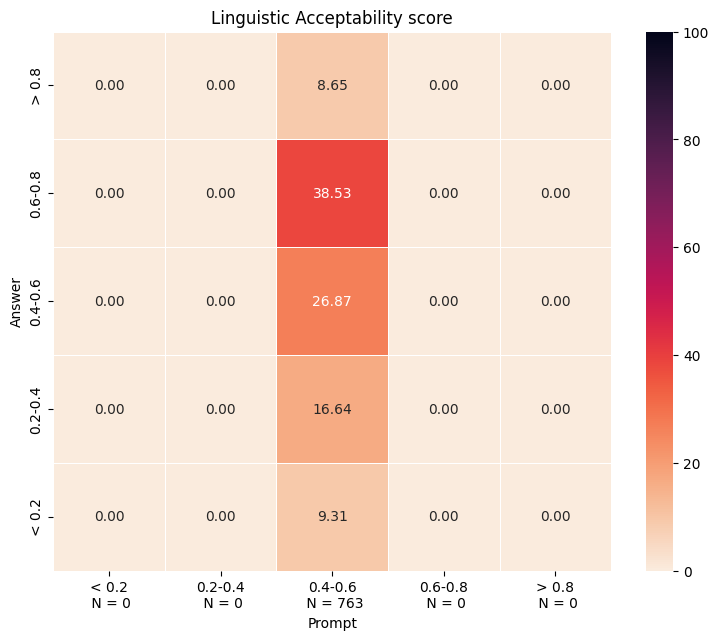

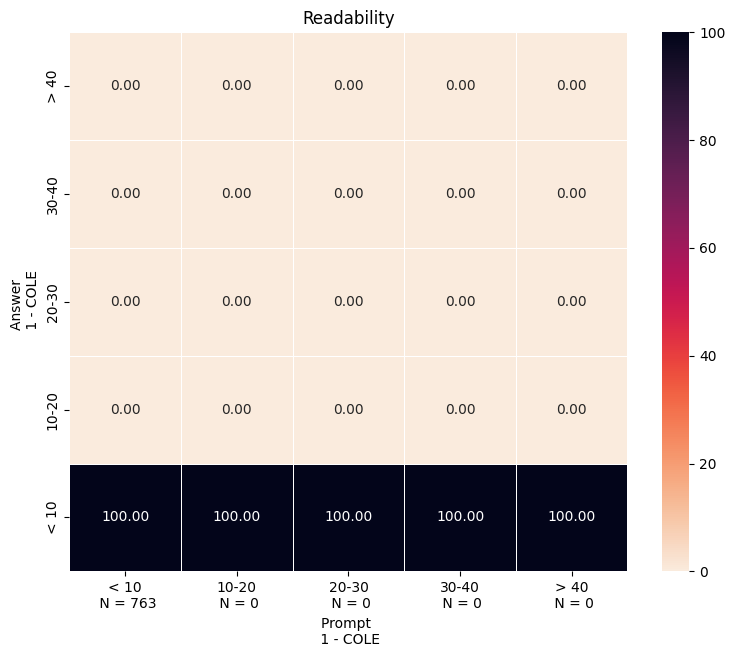

In [13]:
from llm_val.utils.input_prepocessors import preprocess_pkl_input

res = valtest_pretrain_quality(input_list=['./data/data_raw.pkl'],            
                               model=model,
                               preprocess_input=preprocess_pkl_input,
                               goal_theme='любая тема', 
                               speech_quality_args={'test_literacy': True,
                                                    'literacy_model': literacy_model,
                                                    'literacy_tokenizer': literacy_tokenizer,
                                                    'literacy_model_config': literacy_model_config,
                                                    'literacy_tokenizer_config': literacy_tokenizer_config},
                               toxity_args={'model': toxity_model,
                                            'tokenizer': toxity_tokenizer,
                                            'model_config': toxity_model_config,
                                            'tokenizer_config': toxity_tokenizer_config})

In [14]:
display(res['report']['result_dataframes'][0])

,Значение,Результат теста
Изменчивость во времени,0.657895,green
Соответствие тематики цели дообучения,0.907895,green
Токсичность,0.000000,green
Наличие дубликатов,0.115334,yellow
Доля зацикливаний,0.010650,green
Лингвистическая грамотность,0.541048,green
Читаемость,90.015050,green


## Тест 0.3. Наличие обоснований семантических дубликатов/противоречий

In [6]:
from llm_val.val_test.middlegame.valtest_duplicates import valtest_duplicates

Пример вызова теста без загрузки модели (в качестве близости берется SimHash).

Без модели строится только таблица дубликатов по колонке `raw_prompt`:

In [7]:
res = valtest_duplicates(sampler_mmlu_dgr_cripto,
                         sampler_type='MMLU',
                         model=None,
                         threshold=(0.0, 0.05),
                         threshold_duplicates=0.98,
                         threshold_contradictions=0.9875)

Calculate cos similarity raw_prompt:   0%|          | 0/67 [00:00<?, ?it/s]

In [8]:
res['precomputed']['Таблица пар расстояний raw_prompt'].head()

,idx_1,idx_2,similarity
0,27,28,1.000
1,48,60,1.000
2,0,30,1.000
3,59,61,1.000
4,5,6,0.875


Загрузка модели (модель должна иметь метод `encode`):

In [9]:
import os
import torch
import typing as tp
from typing import Union
from sentence_transformers import SentenceTransformer

class EmbeddingModel:
    def __init__(self,
                 model_path: tp.Any=None,
                 name: str='intfloat/multilingual-e5-large',
                 device: str='cpu'):
        self.model_path = model_path
        if model_path is None:
            os.environ['CURL_CA_BUNDLE'] = ''
            model = SentenceTransformer(name, trust_remote_code = True)
        else:
            model = SentenceTransformer.load(model_path)
        self.model = model
        self.device = device
        
    def to_device(self):
        self.model.to(self.device)
        self.model.eval()
    
    def encode(self, 
               documents: Union[tp.List[str], str]):
        with torch.no_grad():
            return self.model.encode(documents)
    
    def save(self, model_path: str):
        self.model.save(model_path)

In [12]:
model_path = r'C:\Users\...' #EmbeddingModel()
model = EmbeddingModel(model_path = model_path)
model.to_device()

Wall time: 2.81 s


Пример вызова теста для MMLU формата с использовнием модели multilingual-e5-large.

Для MMLU формата с использованием эмбеддинг-модели строятся две таблицы парных расстояний для `raw_prompt` и для `question + answer_options[true_answer]`. По этим таблицам соответственно строятся две таблицы противоречий.

In [9]:
res = valtest_duplicates(sampler_mmlu_dgr_cripto,
                         sampler_type='MMLU',
                         model=model,
                         threshold=(0.0, 0.05),
                         threshold_duplicates=0.98,
                         threshold_contradictions=0.9875)

Progress encode raw_prompt in documents:   0%|          | 0/68 [00:00<?, ?it/s]

Calculate cos similarity raw_prompt:   0%|          | 0/67 [00:00<?, ?it/s]

Progress encode question + true answer in documents:   0%|          | 0/68 [00:00<?, ?it/s]

Calculate cos similarity question + true answer:   0%|          | 0/67 [00:00<?, ?it/s]

Противоречия, найденные для колонки `raw_prompt`:

In [10]:
res['precomputed']['Таблица противоречий raw_prompt']

,idx_1,idx_2,raw_prompt_1,true_answer_1,raw_prompt_2,true_answer_2
0,48.0,60.0,Ты аналитик по криптовалютам Как называется по...,C,Ты аналитик по криптовалютам Как называется по...,B
1,59.0,61.0,Ты аналитик по криптовалютам Назовите три осно...,A,Ты аналитик по криптовалютам Назовите три осно...,C
2,0.0,30.0,Ты аналитик по криптовалютам Какие ограничения...,E,Ты аналитик по криптовалютам Какие ограничения...,B


Для форматов RuBQ и LongAnswer строится только таблица дубликатов по колонке `raw_prompt`:

In [13]:
res = valtest_duplicates(sampler_la,
                         sampler_type='LongAnswer',
                         model=model,
                         threshold=(0.0, 0.05),
                         threshold_duplicates=0.999,
                         threshold_contradictions=0.9875)

Progress encode raw_prompt in documents:   0%|          | 0/5 [00:00<?, ?it/s]

Calculate cos similarity raw_prompt:   0%|          | 0/4 [00:00<?, ?it/s]

In [14]:
res['precomputed']['Таблица пар расстояний raw_prompt']

,idx_1,idx_2,similarity
0,0,2,0.998752
1,2,3,0.997582
2,0,3,0.997579
3,1,3,0.997325
4,1,2,0.997026
5,0,1,0.996735
6,2,4,0.992857
7,0,4,0.992361
8,1,4,0.991479
9,3,4,0.991174


## Тест 0.4. Чувствительность метрики относительно размера тестового сета

In [7]:
from llm_val.val_test.middlegame.valtest_metric_sens_by_size import valtest_metric_sens_by_size

В тесте реализован подсчет доверительного интервала для accuracy и для других стандартных метрик бинарной классификации (precision, recall, F1-мера).

Для метрики accuracy существует стандартная формула доверительного интервала Уилсона для биномиального распредления:

100%|██████████| 78/78 [00:00<00:00, 5450.42it/s]


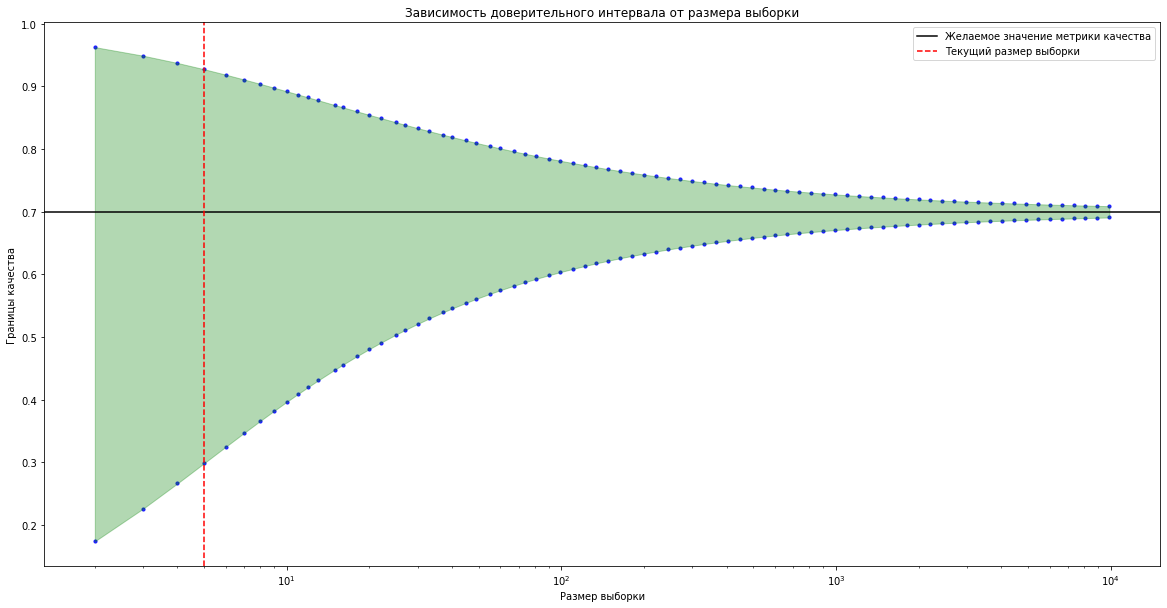

In [13]:
res = valtest_metric_sens_by_size(sampler=sampler_rubq, 
                                  data_type='test',
                                  metric='accuracy',
                                  n_sample_border=(2, 10_000),
                                  target_metric=0.7,
                                  quantile=0.95)

In [9]:
res['report']['result_dataframes'][0]

,Текущий размер выборки,Целевое значение метрики,Квантиль доверительного интервала
0,5,0.7,0.95


Для оценки доверительного интервала для всех остальных метрик бинарной классификации требуется использовать все четыре значения бинарной матрицы (TP, FP, FN, TN), в связи с этим тест для этих метрик можно провести только, если известны их доли по имеющимся данным или известны примерные оценки этих долей.

Эта оценка происходит генерацией выборок с указанными долями значений бинарной матрицы и подсчетом на этих выборках метрик.

Итак, пусть нам известны эти доли, тогда мы создаем словарь с ними и подаем его в тест с указанием интересующей нас метрики:

In [10]:
dict_of_binary_freqs = {'TP': 0.3,
                        'FP': 0.1,
                        'FN': 0.1,
                        'TN': 0.5}

100%|██████████| 78/78 [00:24<00:00,  3.16it/s]


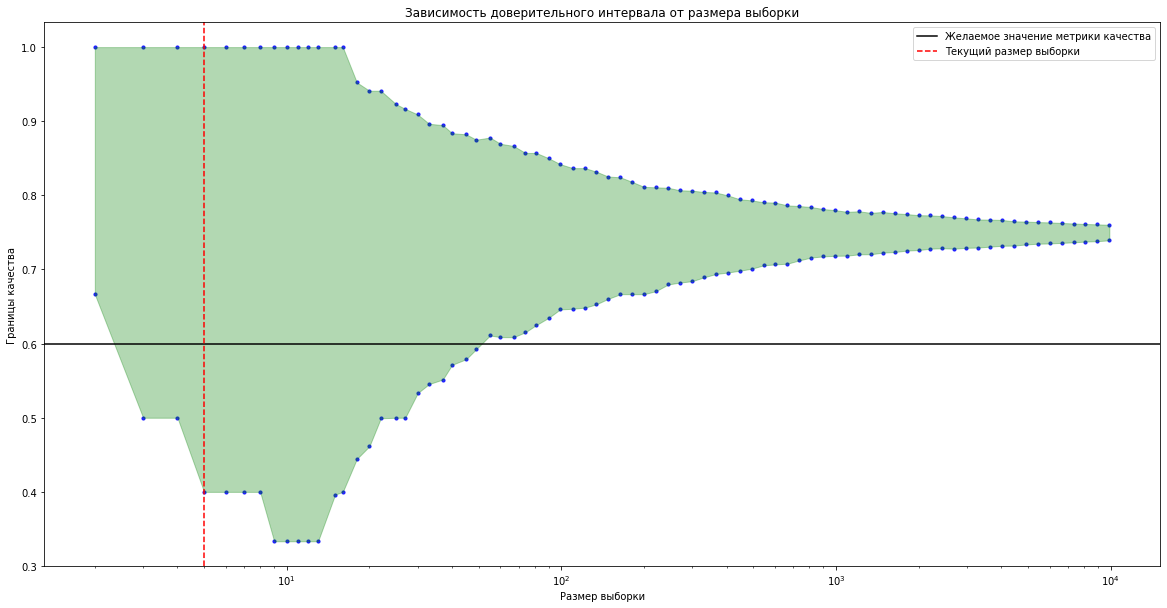

In [15]:
res = valtest_metric_sens_by_size(sampler=sampler_rubq, 
                                  data_type='test',
                                  metric='f1-score',
                                  dict_of_binary_freqs=dict_of_binary_freqs,
                                  n_gened_set=1000,
                                  n_sample_border=(2, 10_000),
                                  target_metric=0.6,
                                  quantile=0.95)

In [12]:
res['report']['result_dataframes'][0]

,Текущий размер выборки,Целевое значение метрики,Квантиль доверительного интервала
0,5,0.6,0.95


Если выборки очень маленькие, то границы интервала могут "прыгать", но на хоть сколько-то адекватных размерах они приходят в норму.

## Тест 0.5. Распределение вариантов ответов

In [12]:
from llm_val.val_test.middlegame.valtest_uniform_distribution_mmlu import valtest_uniform_distribution_mmlu

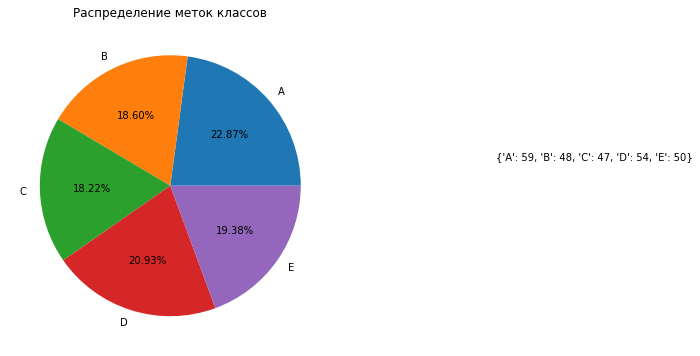

In [13]:
res = valtest_uniform_distribution_mmlu(sampler_mmlu_dgr, alpha=0.05)

In [14]:
res['report']['result_dataframes'][0]

,Количество ответов
Вариант ответа,
A,59
B,48
C,47
D,54
E,50


In [15]:
res['precomputed']['stats']

{'chi': 1.883720930232558, 'p_value': 0.7571348159833132}

Пример использования теста с проведенным перемешиванием

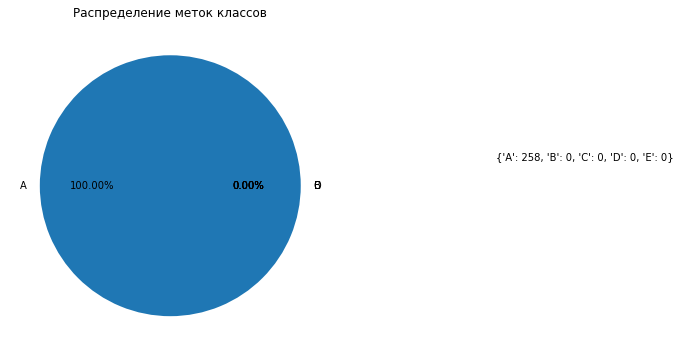

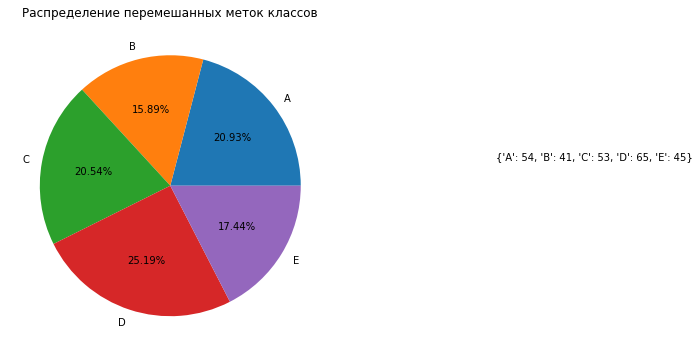

In [16]:
sampler_mmlu_dgr.test['X']['true_answer'] = 'A'
res = valtest_uniform_distribution_mmlu(sampler_mmlu_dgr, alpha=0.05)

Распределение перемешанных ответов:

In [17]:
res['report']['result_dataframes'][1]

,Количество ответов
Вариант ответа,
A,54
B,41
C,53
D,65
E,45


Датасет с перемешанными вариантами ответов:

In [18]:
res['precomputed']['permutate_data_mmlu']

,system,question,context,thema,answer_options,true_answer,row_prompt,model_answer
0,"Ты эксперт на валютном рынке, торгующий как сп...",Какой тип опциона позволяет его владельцу испо...,None,None,"{'A': 'Бинарный опцион', 'B': 'Европейский опц...",C,"Ты эксперт на валютном рынке, торгующий как сп...",None
1,"Ты эксперт на валютном рынке, торгующий как сп...",Какие из перечисленных инструментов являются т...,None,None,"{'A': 'Форвардные контракты', 'B': 'Акции', 'C...",A,"Ты эксперт на валютном рынке, торгующий как сп...",None
2,"Ты эксперт на валютном рынке, торгующий как сп...",Что такое валютный опцион?,None,None,{'A': 'Процентная ставка по кредиту в иностран...,C,"Ты эксперт на валютном рынке, торгующий как сп...",None
3,"Ты эксперт на валютном рынке, торгующий как сп...",Что такое своп в контексте валютных деривативов?,None,None,"{'A': 'Один из видов опционов на валюту', 'B':...",B,"Ты эксперт на валютном рынке, торгующий как сп...",None
4,"Ты эксперт на валютном рынке, торгующий как сп...",Какой из нижеперечисленных примеров является п...,None,None,"{'A': 'Приобретение валюты наличными', 'B': 'И...",C,"Ты эксперт на валютном рынке, торгующий как сп...",None
...,...,...,...,...,...,...,...,...
253,"Ты эксперт на валютном рынке, торгующий как сп...","Ситуация, при которой дериватив в будущем буде...",None,None,"{'A': 'Спред', 'B': 'Арбитраж', 'C': 'Хеджиров...",B,"Ты эксперт на валютном рынке, торгующий как сп...",None
254,"Ты эксперт на валютном рынке, торгующий как сп...",Что такое паритет покупательской способности (...,None,None,"{'A': 'Теория, утверждающая, что в долгосрочно...",D,"Ты эксперт на валютном рынке, торгующий как сп...",None
255,"Ты эксперт на валютном рынке, торгующий как сп...",В чем заключается смысл покрытого процентного ...,None,None,{'A': 'Реальные процентные ставыки в разных ст...,A,"Ты эксперт на валютном рынке, торгующий как сп...",None
256,"Ты эксперт на валютном рынке, торгующий как сп...",Что из себя представляет RUONIA?,None,None,"{'A': 'Ставка по кредитам, предоставляемым физ...",B,"Ты эксперт на валютном рынке, торгующий как сп...",None


## Тест 0.6. Наличие корреляции между корректностью и длиной ответа

In [6]:
from llm_val.val_test.middlegame.valtest_answer_length_corr import valtest_answer_length_corr

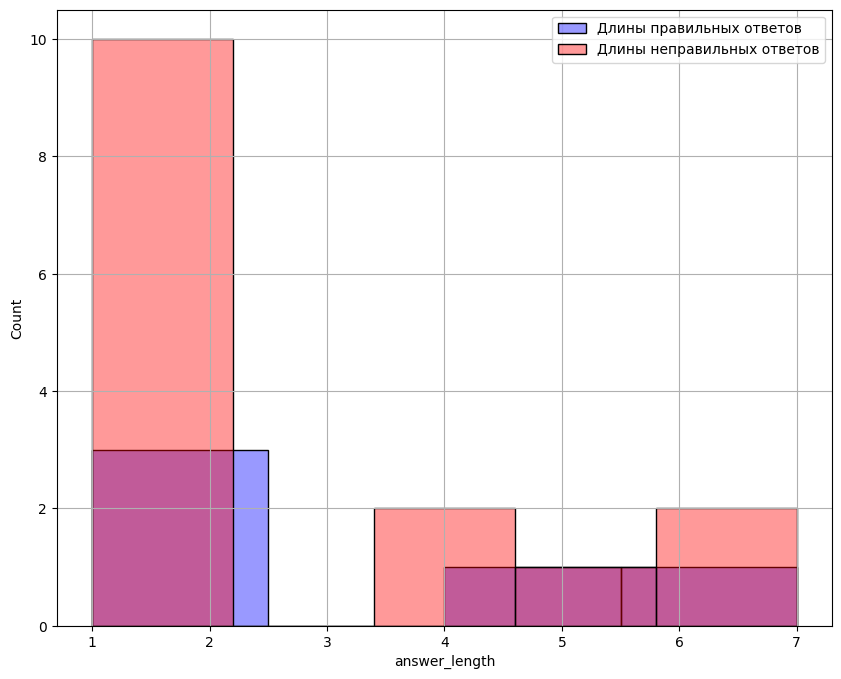

In [7]:
res = valtest_answer_length_corr(sampler=sampler_mmlu,
                                 data_type='test',
                                 semaphore_threshold_spear=0.3,
                                 semaphore_threshold_pval=0.05,
                                 is_info=False)

In [8]:
display(res['report']['result_dataframes'][0])

,Статистика,Значение статистики,p-value статистики
0,Корреляция Спирмена,0.114855,0.629683


## Тест 0.7.  Присутствие в датасете вопросов, точная формулировка которых есть в Интернете

Приоритетный способ использования теста - запуск через поисковый движок rambler.

#### Пример использования rambler (рекомендуемый способ).

In [13]:
from llm_val.val_test.middlegame.valtest_internet_exact_match import valtest_internet_exact_match

In [17]:
res = valtest_internet_exact_match(sampler=sampler_mmlu,
                                   data_type='test',
                                   engine='rambler',
                                   top_to_check=5,
                                   verbose=True)

100%|██████████| 5/5 [00:27<00:00,  5.59s/it]


In [18]:
display(res['report']['result_dataframes'][0])

,Доля найденных вопросов без ответов
0,0.2


In [19]:
display(res['report']['result_dataframes'][1])

,Найденные вопросы,Найденные ссылки
0,Чем апартаменты отличаются от квартир?,"[https://realty.yandex.ru/journal/post/chem-apartamenty-otlichayutsya-ot-kvartiry-i-stoit-li-v-nih-zhit/, https://dzen.ru/a/Z5YSFUqPlDRVwd3I, https://www.cian.ru/stati-bolshaja-raznitsa-chem-apartamenty-otlichajutsja-ot-kvartir-217612/, https://www.raiffeisen-media.ru/nedvizhimost/chem-apartamenty-otlichayutsya-ot-kvartir/, https://www.cian.ru/novosti-bolshinstvo-rossijan-ne-znajut-chem-apartamenty-otlichajutsja-ot-kvartir-336726/]"


Помимо этого, в тесте поддерживаются и другие поисковые системы. Однако в этом случае есть возможность столкнуться с проблемой, заключающейсяся в том, что запросы, отправляемые в поисковую систему, достаточно оперативно блокируются. 
По данным проведенного стресс тестирования для трех доступных поисковиков получены следующие результаты:

Google - каждые 100 запросов количество запросов, получивших 429, растет на 5-6%. Из 1000 запросов падало в среднем 450.

Yandex - капча на первый же запрос независимо от устройства и IP.

DuckDuckGo - нет закономерности, может отработать 200 запросов без бана, может забанить на 40-50 запрос.

Для избежания бана предусмотрено 2 инструмента:

1) Параметры таймаутов на запросы, см. докстринги к тесту.

2) Ротационное проксирование запросов. Имеет особенности и требует наличия рабочих прокси. Подробное описание далее.

#### Пример использования без прокси.

In [11]:
from llm_val.val_test.middlegame.valtest_internet_exact_match import valtest_internet_exact_match

In [12]:
res = valtest_internet_exact_match(sampler=sampler_mmlu,
                                   data_type='test',
                                   engine='google',
                                   top_to_check=5,
                                   verbose=True)

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:36<00:00,  7.20s/it]


In [13]:
display(res['report']['result_dataframes'][0])

,Доля найденных вопросов без ответов
0,0.2


In [14]:
display(res['report']['result_dataframes'][1])

,Найденные вопросы,Найденные ссылки
0,Чем апартаменты отличаются от квартир?,[https://xn--90aivcdt6dxbc.xn--p1ai/articles/q...


#### Пример использования с прокси.

Во избежание бана личного/рабочего IP можно использовать ротационные прокси, с которых будут отправляться запросы в поисковик. В таком случае на каждый запрос будет отправляться до `max_proxy_retries` запросов с разных прокси, пока тест не получит ответ с кодом 200.

Тестом поддерживается 3 типа прокси: `http`, `socks5` и `socks4`, которые передаются в параметры теста `http_proxies`, `socks5_proxies` и `socks4_proxies` соответственно. Поддерживается также использование случайного прокси на каждую попытку получить ответ, см. параметр `proxying_policy`. 

Для использования прокси требуется собрать список строк в формате ссылок.

В рамках тестирования данной функциональности было обнаружено, что Google и DuckDuckGo при проксировании запросов могут отвечать с кодом 200, однако присылать ответ с HTML с неизвестным содержанием, не связанным с запросом. Природа этого явления не была выяснена. В связи с этим рекомендуется проверять ответы на запросы перед выставлением светофора по тесту.

In [44]:
with open('data/http_proxies.txt', 'r') as f:
    http_proxies = f.read().split('\n')
    
with open('data/socks5_proxies.txt', 'r') as f:
    socks5_proxies = f.read().split('\n')

In [45]:
from llm_val.val_test.middlegame.valtest_internet_exact_match import valtest_internet_exact_match

In [46]:
res = valtest_internet_exact_match(sampler=sampler_mmlu,
                                   data_type='test',
                                   top_to_check=5,
                                   max_proxy_retries=5,
                                   proxying_policy='random',
                                   http_proxies=http_proxies,
                                   socks5_proxies=socks5_proxies,
                                   verbose=True)

  0%|                                                                                            | 0/5 [00:00<?, ?it/s]

Proxy 128.14.225.204:12088 not available
Proxy 106.14.91.83:8443 not available
Proxy 121.43.146.222:1111 not available
Proxy 118.193.58.234:19164 not available
Proxy 121.43.146.222:1111 not available
No pages scrapped


 20%|████████████████▊                                                                   | 1/5 [00:47<03:10, 47.67s/it]

Proxy 121.43.146.222:1111 not available
Proxy 103.169.41.224:3125 not available
Proxy 118.193.58.234:19164 not available
Proxy 103.169.41.224:3125 not available
Proxy 103.169.41.224:3125 not available
No pages scrapped


 40%|█████████████████████████████████▌                                                  | 2/5 [01:49<02:47, 55.82s/it]

...

Proxy 158.255.215.50:16993 not available
Proxy 120.26.104.146:8008 not available
Proxy 118.193.58.165:12382 not available
Proxy 118.193.58.234:19164 not available
Proxy 120.26.104.146:8008 not available
No pages scrapped


 80%|███████████████████████████████████████████████████████████████████▏                | 4/5 [02:33<00:53, 53.41s/it]

Proxy 128.14.225.204:12088 not available
Proxy 158.255.215.50:16993 not available
Proxy 118.193.58.165:12382 not available
Proxy 106.14.91.83:8443 not available
Proxy 121.43.146.222:1111 not available
No pages scrapped


100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [02:59<00:00, 35.80s/it]

5 question-answer pairs did not get a response from serach


In [47]:
display(res['report']['result_dataframes'][0])

,Доля найденных вопросов без ответов
0,0.0


In [48]:
display(res['report']['result_dataframes'][1])

,Найденные вопросы,Найденные ссылки


Для удобства упавшие запросы записываются в `precomputed` в поля `failed_questions` (только вопросы) и `failed_pairs` (вопрос-ответ). После этого их можно собрать в простой сэмплер и запустить тест заново.

In [29]:
res['precomputed']

{'found_frac_without_answers': 0.0,
 'found_frac_with_answers': 0.0,
 'failed_questions': [('Какие объекты недвижимости можно приобрести с использованием ипотечного кредита по программе строящееся жилье?',),
  ('Какой минимальный срок кредита доступен при оформлении ипотечного кредита?',),
  ('Чем апартаменты отличаются от квартир?',),
  ('Какой минимальный первоначальный взнос необходим для получения кредита на коммерческую недвижимость?',),
  ('Какие требования к заемщикам предусмотрены для программы коммерческой недвижимости?',)],
 'failed_pairs': [('Какие объекты недвижимости можно приобрести с использованием ипотечного кредита по программе строящееся жилье?',
   'Офисное помещение'),
  ('Какой минимальный срок кредита доступен при оформлении ипотечного кредита?',
   '6 месяцев'),
  ('Чем апартаменты отличаются от квартир?',
   'Отсутствие возможности оформления постоянной регистрации'),
  ('Какой минимальный первоначальный взнос необходим для получения кредита на коммерческую недв

In [23]:
failed_queries = pd.DataFrame(data=res['precomputed']['failed_pairs'] + res['precomputed']['failed_questions'], columns = ['question', 'true_answer'])
failed_queries['true_answer'] = failed_queries['true_answer'].apply(lambda x: [x])
failed_queries = failed_queries.groupby('question').sum().reset_index()

Для простоты примера упавшие запросы были пересобраны в RuBQ-вид.

In [24]:
failed_queries

,question,true_answer
0,Какие объекты недвижимости можно приобрести с ...,"[Офисное помещение, None]"
1,Какие требования к заемщикам предусмотрены для...,"[Возраст заемщика от 21 до 75 лет., None]"
2,Какой минимальный первоначальный взнос необход...,"[30%, None]"
3,Какой минимальный срок кредита доступен при оф...,"[6 месяцев, None]"
4,Чем апартаменты отличаются от квартир?,[Отсутствие возможности оформления постоянной ...


In [25]:
failed_queries_sampler = Sampler(test={'X': failed_queries, 'y': None})

In [26]:
res_for_failed = valtest_internet_exact_match(sampler=failed_queries_sampler,
                                              data_type='test',
                                              engine='google',
                                              top_to_check=5,
                                              verbose=True)

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:53<00:00, 10.64s/it]


In [27]:
display(res_for_failed['report']['result_dataframes'][0])

,Доля найденных вопросов без ответов
0,0.2


In [28]:
display(res_for_failed['report']['result_dataframes'][1])

,Найденные вопросы,Найденные ссылки
0,Чем апартаменты отличаются от квартир?,[https://xn--90aivcdt6dxbc.xn--p1ai/articles/q...


## Тест 0.8 Определение вопросов, не относящиеся к теме (не по цели бизнес-процесса)

Для теста необходимо написать класс-обертку над моделью, которая обязана иметь метод `q_relevance`. 

Метод `q_relevance` на вход должен принимать строго 2 обязательных именованных параметра (указываются в начале):
1. `question` - вопрос
2. `topics` - список тем, к которым может быть отнесен данный запрос

Данный метод должен возвращать строку "да" или "нет" либо строку, в которой эта информация ("да" или "нет") присутствует.

Ниже приведен пример такого класса, в котором в конструкторе: 
1. инициализируется модель
2. фиксируется `system_prompt` 
3. фиксируется `user_prompt`
4. по функционалу добавляются `few_shots`

Для запуска этой обертки необходимо установить пакеты:

- `pip install langchain==0.3.13`
- `pip install langchain-gigachat==0.3.2`

In [43]:
from langchain_gigachat.chat_models import GigaChat
from langchain.prompts import ChatPromptTemplate, SystemMessagePromptTemplate, HumanMessagePromptTemplate

class ModelOffTopicDetections:
    def __init__(self,
                 model_name: str,
                 system_prompt: str,
                 user_prompt: str,
                 few_shots: tp.List[str]=[],
                 **kwargs):
        '''
        Инициализация модели.
        Parameters:
            model_name:    Название модели
            system_prompt: Системный промпт
            user_prompt:   Юзер промпт
            few_shots:     Список фью-шотов
            **kwargs:      Дополнительные параметры для инициализации модели
        '''
        self.model_name = model_name
        self.system_prompt = system_prompt
        self.user_prompt = user_prompt
        self.few_shots = few_shots
        for key, value in kwargs.items():
            setattr(self, key, value)
        self.model = GigaChat(model=self.model_name, 
                              **kwargs)
        
    def q_relevance(self,
                    question: str,
                    topics: tp.List[str],
                    **kwargs) -> str:
        '''
        Функция, определяющая, относится ли вопрос хотя бы к одной теме или нет. 
        Parameters:
            question: Вопрос
            topics:   Список тематик, к которым может относится вопрос
            **kwargs: Дополнительные параметры для отладки messages
        '''
        input_variables = ['topics', 'question']
        separator_length = 20
        system_template = self.system_prompt
        system_message = SystemMessagePromptTemplate.from_template(system_template)
        user_template = self.user_prompt
        if len(few_shots) > 0:
            input_variables += ['few_shot_{}'.format(i) for i in enumerate(self.few_shots)]
            separator = ''.join(['_']*separator_length) + '\n'
            user_template = user_template.strip('Ответ: ') + separator + 'Примеры: \n' + ' \n\n'.join(few_shots)
            user_template += separator + 'Ответ: '
        user_message = HumanMessagePromptTemplate.from_template(input_variables=input_variables, template=user_template)
        chat_prompt = ChatPromptTemplate.from_messages([system_message, user_message])
        verbose = True if ('verbose' in kwargs) and (kwargs['verbose'] is True) else False
        if verbose:
            loggs = chat_prompt.format_prompt(topics=', '.join(topics),
                                              question=question).to_messages()
            for message in loggs:
                print(f'{message.type}: \n {message.content}')
        chain = chat_prompt | self.model
        return chain.invoke({'topics': ', '.join(topics), 'question': question}).content.strip().lower()

Инициализируем модель и проверим её работу:

In [48]:
system_prompt = """Ты помощник, определяющий релевантность вопроса списку тематик (отвечающий только "Да" или "Нет" на русском языке!)"""
user_prompt = """У тебя есть список тематик: [{topics}]. Я дам тебе Вопрос: "{question}".
Ты должен ответить только "Да" или "Нет" (на русском), в зависимости от того, относится ли вопрос к хотя бы одной из тематик. 
Ответ: """
few_shots = [
"""Список тематик: [опционы, фьючерсы, свопы]. 
Вопрос: Cap/Floor options прайсят с помощью модели Блэка-Шоулза? 
[A] Нет
[B] Да
[C] Прайсят обычно по модели "MyllynParas"
[D] Прайсят обычно по модели "Знакомтесь Джо-Блэк"
[F] Все варианты ответов выше верные
Ответ : Да""", 
"""Список тематик: [математика].
Вопрос: как пишется слово русский или руский?
Ответ: Нет
"""]
rel_model = ModelOffTopicDetections(model_name='GigaChat-Max',
                                    system_prompt=system_prompt,
                                    user_prompt=user_prompt,
                                    few_shots=few_shots,
                                    auth_url=sigma_auth['OAUTH_URL'],
                                    credentials=AUTH_DATA,
                                    verify_ssl_certs=False,
                                    scope='GIGACHAT_API_CORP',
                                    top_p=1e-4, 
                                    verbose=False)
topics = ['спорт', 'музыка']
question = 'Как написать функцию на Python?'
rel_model.q_relevance(question=question,
                      topics=topics, 
                      verbose=True)

system: 
 Ты помощник, определяющий релевантность вопроса списку тематик (отвечающий только "Да" или "Нет" на русском языке!)
human: 
 У тебя есть список тематик: [спорт, музыка]. Я дам тебе Вопрос: "Как написать функцию на Python?".
Ты должен ответить только "Да" или "Нет" (на русском), в зависимости от того, относится ли вопрос к хотя бы одной из тематик. 
____________________
Примеры: 
Список тематик: [опционы, фьючерсы, свопы]. 
Вопрос: Cap/Floor options прайсят с помощью модели Блэка-Шоулза? 
[A] Нет
[B] Да
[C] Прайсят обычно по модели "MyllynParas"
[D] Прайсят обычно по модели "Знакомтесь Джо-Блэк"
[F] Все варианты ответов выше верные
Ответ : Да 

Список тематик: [математика].
Вопрос: как пишется слово русский или руский?
Ответ: Нет
____________________
Ответ: 


'нет'

In [49]:
from llm_val.val_test.middlegame.valtest_unrelated_questions import valtest_unrelated_questions 

Для запуска теста валидатор обязан определить список релевантных тем  - `themes`, где 
`themes[i]` - список тематик, которые относятся к вопросу `question[i]`.

In [58]:
themes_mmlu_dgr = [['финансовая математика', 
                    'финансы',
                    'хэджирование',
                    'деривативы и производные финансовые инструменты', 
                    'опционы',
                    'Interest Rate продукты и операции связанные с процентными кривыми',
                    'валютные конверсии и операции с валютой'] 
                   for i in range(sampler_mmlu_dgr.test['X'].shape[0])]
res = valtest_unrelated_questions(sampler=sampler_mmlu_dgr,
                                  data_type='test',
                                  themes = themes_mmlu_dgr,
                                  model=rel_model)

Calculate...:   0%|          | 0/258 [00:00<?, ?it/s]

In [61]:
res['report']['result_dataframes'][0]

,count
Model answers,
да,193
нет,65


## Тест 0.9. Понятность и четкость формулировки вопроса

In [18]:
from llm_val.val_test.middlegame.valtest_clearness_understandable import valtest_clearness_understandable

Для создания модели для проведения теста необходимы переменные:
- `one_shot` - пример промта (вопроса) для LLM;
- `criterions` - кортеж из критериев, по которым будет оцениваться `one_shot`;
- `system_promt_cascade` - кортеж из нескольких system promt, в каждом из которых содержится инструкция по оценке итогового критерия из списка `criterions`;
- `probable_answer_cascade` - кортеж из ответов на `one_shot` в соответствии с system promt из `system_promt_cascade`.

Требования к промтам:
- В каждом элементе `probable_answer_cascade` обязательно наличие `surround_symbols` - кортежа из двух строк, которые должны оборачивать оценку LLM внутри текста для удобного парсинга оценки. Например, в приведенном здесь скрипте это строки "(((" и ")))";
- Длины для `criterions`, `system_promt_cascade` и `probable_answer_cascade` должны совпадать.

In [19]:
one_shot = 'Как дела?'

criterions = ['Логика и ясность', 'Полнота', 'Конкретность', 'Адекватность']

system_promt_cascade = (
    'Ты — строгий валидатор промта. Тебе будет дан текст, включающий вопрос от пользователя или инструкцию для модели.\nТвоя задача — оценить логичность и ясность формулировки. Оцени, понятен ли вопрос и не вызывает ли путаницу.\nДай оценку по шкале от 1 до 5 и заключи её в тройные скобки (((...))). Комментируй ошибки, если они есть.',
    'Ты — строгий валидатор промта. Тебе будет дан текст, включающий вопрос от пользователя или инструкцию для модели.\nТвоя задача — оценить полноту информации. Проверь, содержит ли промт достаточно данных для создания разумного ответа.\nДай оценку по шкале от 1 до 5 и заключи её в тройные скобки (((...))). Комментируй недостатки, если они есть.',
    'Ты — строгий валидатор промта. Тебе будет дан текст, включающий вопрос от пользователя или инструкцию для модели.\nТвоя задача — оценить конкретность формулировки. Проверь, насколько четко изложена цель вопроса. Общие вопросы должны получать низкую оценку.\nДай оценку по шкале от 1 до 5 и заключи её в тройные скобки (((...))). Комментируй, если запрос недостаточно конкретен.',
    'Ты — строгий валидатор промта. Тебе будет дан текст, включающий вопрос от пользователя или инструкцию для модели.\nТвоя задача — оценить адекватность вопроса. Проверь, насколько запрос имеет смысл и полезен для модели. Бессмысленные и нелепые вопросы получают низкую оценку.\nДай оценку по шкале от 1 до 5 и заключи её в тройные скобки (((...))). Объясни ошибки, если они есть.'
)

probable_answer_cascade = (
    'Логика и ясность: Вопрос логичен и понятен, не вызывает путаницы. Оценка: (((5)))',
    'Полнота: Вопрос слишком краткий и не содержит информации, которая помогла бы дать осмысленный ответ. Он не содержит контекста. Оценка: (((1)))',
    'Конкретность: Вопрос очень общий, цель или направленность не ясна. Оценка: (((1)))',
    'Адекватность: Вопрос не абсурден, но с точки зрения полезности для модели — минимально полезен. Он не помогает в достижении какой-либо практической цели. Оценка: (((2)))'
)

surround_symbols = ('(((', ')))')

Модель для данного теста должна иметь метод predict, который
- принимает на вход `questions: tp.Union[tp.List[str], pd.Series]`;
- возвращает словарь с количеством ключей, равным размеру `criterions`, `system_promt_cascade` и `probable_answer_cascade`, где каждому ключу соответствует список, равный по длине `len(questions)`.

In [20]:
from llm_val.model.MultiThreadCascadeGigaModel import MultiThreadCascadeGigaModel

model_for_clearness = MultiThreadCascadeGigaModel(system_promt_cascade=system_promt_cascade,
                                                  one_shot=one_shot,
                                                  probable_answer_cascade=probable_answer_cascade,
                                                  rquid=RQUID,
                                                  auth_data=AUTH_DATA,
                                                  oauth_url=total_auth[contour]['OAUTH_URL'],
                                                  api_url=total_auth[contour]['API_URL'],
                                                  token=total_auth[contour]['TOKEN'],
                                                  model='GigaChat:latest',
                                                  n_jobs=8)

In [23]:
promts = data_la2.loc[:10]
promts_mapped_dict = {'X': promts, 'y': None}
sampler_for_clearness = Sampler(test=promts_mapped_dict)

In [25]:
report = valtest_clearness_understandable(sampler_for_clearness,
                                          model_for_clearness,
                                          surround_symbols=surround_symbols,
                                          criterions=criterions)

11it [00:00, 113081.73it/s]
11it [00:00, 181643.09it/s]
11it [00:00, 193854.39it/s]
11it [00:00, 189865.61it/s]


In [26]:
report['report']['result_dataframes'][0]

,question,general_assessments,Логика и ясность,Полнота,Конкретность,Адекватность,semaphore
0,Есть ли в этом мире подходящий международный и...,3.50,"Логика и ясность: Вопрос логичен и понятен, не...",Вопрос недостаточно конкретен. Нужно больше ин...,"Конкретность: Вопрос достаточно общий, но подр...",Адекватность: Запрос имеет смысл и является ко...,yellow
1,"Какой курс выбрать для того, чтобы начать рабо...",4.25,Логика и ясность: Вопросы о выборе курсов или ...,Полнота: Просьба о конкретном курсе для начала...,"Конкретность: Запрос достаточно конкретный, це...",Адекватность: Запрос имеет смысл и может быть ...,green
2,Как правильно сделать перенос строки на PHP?,5.00,"Логика и ясность: Вопрос логичен и понятен, не...",Полнота: Просьба о правильном способе сделать ...,"Конкретность: Вопрос достаточно конкретный, це...",Адекватность: Запрос имеет смысл и направлен н...,green
3,Почему язык Си может работать с низкоуровневым...,5.00,"Логика и ясность: Вопрос логичен и понятен, не...",Полнота: Вопрос конкретный и содержит достаточ...,Конкретность: Вопрос конкретный и направлен на...,Адекватность: Вопросы о принципах работы языко...,green
4,Как выйти из цикла while?,4.75,"Логика и ясность: Вопрос логичен и понятен, не...",Полнота: Просьба о помощи с выходом из цикла w...,"Конкретность: Вопрос достаточно конкретный, та...","Вопрос корректный и полезный для модели, так к...",green
5,Как решить проблему перегрева ноутбука?,4.75,"Логика и ясность: Вопрос логичен и понятен, не...",Полнота: Просьба о помощи с решением проблемы ...,Конкретность: Вопрос имеет четкую направленнос...,Адекватность: Запрос имеет смысл и направлен н...,green
6,Как прижать footer к низу страницы?,4.75,"Логика и ясность: Вопрос логичен и понятен, не...",Полнота: Просьба о помощи с технической задаче...,"Конкретность: Вопрос достаточно конкретный, це...",Адекватность: Запрос имеет смысл и может быть ...,green
7,Что нужно иметь и знать в фреймворке React джуну?,4.50,"Логика и ясность: Вопрос логичен и понятен, не...",Полнота: Просьба о предоставлении информации о...,"Конкретность: Вопрос достаточно конкретный, та...",Адекватность: Запрос имеет смысл и полезен для...,green
8,Отключить показы на Windows в Директе и Ads во...,4.25,"Логика и ясность: Вопрос логичен и понятен, не...",Полнота: Просьба о возможности отключения пока...,"Конкретность: Вопрос конкретный, цель ясна - у...","Адекватность: Да, это возможно. В рекламных ка...",green
9,Адаптивный анимированный слайдер?,2.75,Логика и ясность: Запрос звучит корректно и по...,Полнота: Просьба о предоставлении информации о...,"Конкретность: Запрос достаточно конкретный, но...",Вопрос не содержит конкретики и не позволяет о...,yellow


##  Тест 0.10 Единство системного промпта для всех вопросов тестовой выборки.

In [22]:
from llm_val.val_test.middlegame.valtest_unity_system_prompt import valtest_unity_system_prompt

`thematic_classifier` - обязательный параметр для теста. Валидатору необходимо уточнить есть ли тематический классификтора в ML пайплайне. 

- Если его нет, то `system` обязан быть одним для всех вопросов тестового сета.
- Если он есть, то `system` обязан быть одним для всех вопросов из одной тематики.

N.B.: Для L1 кейсов считаем, что классификатор есть.

In [23]:
res = valtest_unity_system_prompt(sampler_la,
                                  thematic_classifier=True)

In [24]:
res['report']['result_dataframes'][0]

,list_of_prompts
devops,NaN
java,NaN


## Тест 0.11 Единство формата

In [7]:
from llm_val.val_test.middlegame.valtest_unity_format import valtest_unity_format
from llm_val.utils.speech_quality.sage_model.sage_api import SageAPI

### MMLU:

Вызов теста без проверки орфографии:

In [8]:
res = valtest_unity_format(sampler_mmlu_dgr_with_errors,
                           data_type='test', 
                           sampler_type='MMLU')
res['report']['result_dataframes'][1]

,Num errors,Error rate
0,13,0.52


Удобный вывод таблицы найденных потенциальных ошибок:

In [9]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', 2000)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
res['report']['result_dataframes'][0]
res['report']['result_dataframes'][0]

,true_answers,pool_answers,encoding,question,answers
Num,,,,,
0,None,Число представленных ответов = 4. Должно быть 5. Некорректная буква C в пуле ответов. Некорректная буква D в пуле ответов. Некорректная буква E в пуле ответов.,"Спецсимволы: ['😉', '★'].",None,None
1,None,None,Спецсимволы: ['😉'].,None,Пустой ответ под буквой C.
2,Некорректная буква [F]]] в true_answer.,Число представленных ответов = 3. Должно быть 5. Некорректная буква E в пуле ответов.,Спецсимволы: ['😉'].,None,None
3,Некорректная буква [] в true_answer.,None,None,None,None
4,None,Число представленных ответов = 3. Должно быть 5.,None,None,None
5,Некорректная буква [E БУКBA] в true_answer.,None,None,None,None
6,Некорректная буква Я ЗAБЫЛ ОТBEТ… в true_answer.,None,None,None,None
8,Некорректная буква [😉] в true_answer.,None,None,None,None
10,None,None,None,None,Пустой ответ под буквой A. Пустой ответ под буквой C.


Создаем словарь для кеширования результатов API SAGE (в нем будут хранится исправленные тексты как values, а сами тексты как keys):

In [9]:
cache_sage_api = {}
sage_model_api = SageAPI(contour=contour)

В случае потери соединения при работе с моделью и прерывания работы теста нужно перезапустить ячейку с тестом - в словаре с кэшем уже сохранены все предыдущие результаты.

In [10]:
res = valtest_unity_format(sampler_mmlu_dgr_with_errors, 
                           data_type='test',
                           sampler_type='MMLU',
                           model=sage_model_api,
                           threshold=(0,0.6),
                           cache_api=cache_sage_api)

100%|██████████| 25/25 [00:56<00:00,  2.28s/it]


In [11]:
res['report']['result_dataframes'][1]

,Num errors,Error rate,Word error rate,Levenshtein distance
0,13,0.52,0.426601,0.087028


Словарь для кэширования результатов также доступен через *precomputed*:

In [12]:
id(cache_sage_api) == id(res['precomputed']['cache_sage_api'])

True

### RuBQ:

In [13]:
res = valtest_unity_format(sampler_rubq,
                           data_type='test', 
                           sampler_type='RuBQ')
res['report']['result_dataframes'][1]

,Num errors,Error rate
0,0,0.0


С проверкой орфографии:

In [15]:
res = valtest_unity_format(sampler_rubq,
                           data_type='test', 
                           sampler_type='RuBQ',
                           model=sage_model_api,
                           threshold=(0,0.6),
                           cache_api=cache_sage_api)
res['report']['result_dataframes'][1]

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [05:05<00:00, 61.07s/it]


,Num errors,Error rate,Word error rate,Levenshtein distance
0,0,0.0,0.321818,0.073779


### LongAnswer:

In [17]:
res = valtest_unity_format(sampler_la,
                           data_type='test', 
                           sampler_type='LongAnswer')
res['report']['result_dataframes'][1]

,Num errors,Error rate
0,0,0.0


С проверкой орфографии:

In [55]:
res = valtest_unity_format(sampler_la,
                           data_type='test', 
                           sampler_type='LongAnswer',
                           model=sage_model_api,
                           threshold=(0,0.75),
                           cache_api=cache_sage_api)
res['report']['result_dataframes'][1]

100%|███████████████████████████████████████████████████████████████████████████████████| 5/5 [15:20<00:00, 184.13s/it]


,Num errors,Error rate,Word error rate,Levenshtein distance
0,0,0.0,0.341664,0.140597


##  Тест 0.12 Соответствие вопросов в датасете его назначению

Для теста необходимы системный промпт и парсер ответа для этого системного промпта. По умолчанию задаем следующий промпт:

In [94]:
task_type = 'RUBQ'

error_codes = {'RUBQ': {'RUBQ_LONG_ANSWER': 'ANSWER содержит развернутые варианты ответов?',
                        'YESNO_RUBQ_ANSWER': 'Варианты ответа в ANSWER состоят только из утверждений "да"/"нет"?',
                        'NO_NUM_DUB_RUBQ': 'Числа в ANSWER НЕ продублированы числительными?',
                        'RUBQ_DETAILED_HINT': 'Дается ли в QUESTION указание на длинный развернутый ответ?'},

               'LONGANSWER': {'LA_NONDETAILED_HINT': 'Дается ли в QUESTION указание на длинный развернутый ответ?',
                              'NOT_LONG_ANSWER': 'ANSWER является кратким ответом или набором кратких вариантов ответов?'}}

system_prompt = f'''
Ты отлично разбираешься в составлении тестов различных форматов для LLM. Тебе будет дан запрос в LLM, в котором будут находиться поля QUESTION и ANSWER для данного запроса. Твоя задача - проверить запрос на соответствие списку проверок, который будет дан ниже. При ответе на каждый из вопросов рассуждай последовательно и аргументируй свой ответ. В самом конце своего ответа укажи поле ERROR_CODES: и в него через запятую вставь ключи пройденных проверок. Не пиши в поле ERROR_CODES ничего, кроме ключей. Если ни одна из проверок не пройдена, закончи свой ответ фразой "ERROR_CODES: NONE"

Список проверок:
{error_codes[task_type.upper()]}
'''    

Идея теста заключается в том, что мы поручаем GC проверить запрос в LLM на соответствие ряду проверок, описание которых находится в словаре error_codes. Для этого промпта используется следующий парсер:

In [95]:
def answer_parser(answer: str,
                  ok_answer_key: str='NONE') -> tp.Tuple[str]:
    '''
    Парсер ответа для дефолтного промпта
    Parameters:
        answer: Ответ GC в строковой форме
        ok_answer_key: Код, означающий отсутствие ошибок или Код, который должен выдать GC, если все ок
    Return:
        Tuple со всеми найденными кодами ошибок
    '''
    if 'ERROR_CODES:' not in answer:
        errors = ['INVALID_GC_OUTPUT']
    else:
        pattern = 'ERROR_CODES:'
        errors_start = answer.find(pattern) + len(pattern)
        errors = answer[errors_start:].strip().strip('.').split(',')
        if ok_answer_key in errors and len(errors) > 1:
            errors.remove(ok_answer_key)
    return tuple(errors)

К сожалению, качество работы GC на данном промпте оставляет желать лучшего и может не соответствовать предъявляемым требованиям. Поэтому ответственному валидатору предоставляется возможность самостоятельно написать промпт и парсер в соответствии со своим взглядом на возможности используемой модели. Промпт `system_prompt` должен представлять собой текст, парсер `answer_parser` должен принимать на вход текст и отдавать на выход Tuple с кодами ошибок. Также обязательно необходимо оставить код ответа `ok_answer_key`, который будет означать, что все проверки пройдены, и добавить GC указание оставлять этот ключ, если все ок.

Подробное описание параметров теста:

`system_prompt`: str - системный промпт

`answer_parser`: tp.Callable\[str, tp.Tuple\[str\]\] - парсер ответа GC

`ok_answer_key`: str - код, который должен выдать GC, если все ок

In [96]:
from llm_val.val_test.middlegame.valtest_question_task_agreement import valtest_question_task_agreement

С промптом по умолчанию ответы получаются нестабильными, модель начинает выдумывать свои шаблоны ответа, в связи с чем рекомендуется использовать temperature=1 и top_p=0.

In [97]:
model_012 = MultiThreadGigaModel(n_jobs=8,
                                 rquid=RQUID,
                                 auth_data=AUTH_DATA,
                                 oauth_url=total_auth[contour]['OAUTH_URL'],
                                 api_url=total_auth[contour]['API_URL'],
                                 token=total_auth[contour]['TOKEN'],
                                 temperature=1,
                                 top_p=0)

In [98]:
res = valtest_question_task_agreement(sampler_rubq,
                                      model=model_012,
                                      system_prompt=system_prompt,
                                      answer_parser=answer_parser,
                                      task_type=task_type,
                                      ok_answer_key='NONE',
                                      verbose_predictions=True)

Checking errors in queries...


  0%|          | 0/5 [00:00<?, ?it/s]

In [99]:
res['report']['result_dataframes'][0]

,Тип ошибки,Значение
0,RUBQ_LONG_ANSWER,2.0
1,NO_NUM_DUB_RUBQ,2.0
2,Всего ошибок,4.0
3,Запросов с ошибками,2.0
4,Доля запросов с ошибками,0.4


In [100]:
res['precomputed']['incorrect_queries']

,question,true_answer,errors
2,Сколько максимально ипотечных кредитов можно в...,"[три, 3]","(RUBQ_LONG_ANSWER, NO_NUM_DUB_RUBQ)"
3,Каков максимальный размер кредита на строящеес...,"[100 000 000 рублей, 100 млн. рублей]","(RUBQ_LONG_ANSWER, NO_NUM_DUB_RUBQ)"


## Тест 0.13.  Соответствие доли тем тестовых вопросов реальному распределению

In [32]:
from llm_val.val_test.middlegame.valtest_topic_proportion import valtest_topic_proportion

In [33]:
apriori_dict = {'thema1': 0.3,
                'thema2': 0.1,
                'thema3': 0.6}

### MMLU

In [34]:
res = valtest_topic_proportion(sampler_mmlu, 
                               apriori_dict)

In [35]:
display(res['report']['result_dataframes'][0])

,Тематика,Реальное распределение,Априорное распределение
0,thema1,0,0.3
1,thema2,0,0.1
2,thrma3,0,0.6


### RuBQ

In [36]:
res = valtest_topic_proportion(sampler_rubq, 
                               apriori_dict)

In [37]:
display(res['report']['result_dataframes'][0])

,Тематика,Реальное распределение,Априорное распределение
0,thema1,0,0.3
1,thema2,0,0.1
2,thrma3,0,0.6


## Тест 0.14. Наличие дублирования числовых ответов числительными

В тесте проводится проверка на наличие дублирования числовых ответов числительными и числительных числами. Важно, чтобы числительные были написаны только текстом, а числа только цифрами. Если число записано, как "11 590 тысяч", то будет найдено число 11 590 и числительное "тысяч", что повлияет на долю продублированных ответов. 

Для работы теста необходимо установить пайплайн русского языка для Spacy. 

В MLSpace необходимо выполнить команду:

```
python -m spacy download ru_core_news_lg --no_deps --target PATH/llm_val/resources/ru_spacy
```

Где ```PATH``` - путь до src.

Для работы в Datalab необходимо перейти по ссылке: https://sberosc.ca.sbrf.ru/dashboard/vulnerabilities/scannedentityversionfile/2020920/change/?_changelist_filters=q%3Dru_core_news, загрузить архив и распаковать его в ```PATH/llm_val/resources/ru_spacy```

Где ```PATH``` - путь до src. 

Готово!

In [5]:
from llm_val.val_test.middlegame.valtest_numbers_numerals_duplicated import valtest_numbers_numerals_duplicated

In [6]:
res = valtest_numbers_numerals_duplicated(sampler=sampler_rubq,
                                          data_type='test',
                                          semaphore_threshold=(0.0, 0.05),
                                          is_info=False,
                                          not_duplicated_dict=None)

In [7]:
res['report']['result_dataframes'][0]

,Проверка,Значение,Результат теста
0,Доля непродублированных числительных и чисел,0.857143,red


In [8]:
res['precomputed']

{'not duplicated': [{'18': 'восемнадцать', '65': 'шестьдесят пять'},
  {},
  {},
  {'100000000': 'сто миллионов', '100': 'сто'},
  {'11590': 'одиннадцать тысяч пятьсот девяносто', 'тысяча': '1000'}],
 'duplicated': [{}, {}, {'три': '3'}, {}, {}],
 'amount': 0.8571428571428571}

## Тест 0.15. Наличие тематик вопросов

In [6]:
from llm_val.val_test.middlegame.valtest_definition_themes import valtest_definition_themes

In [8]:
res = valtest_definition_themes(sampler=sampler_la, 
                                data_type='test')

In [11]:
res['report']['result_dataframes'][0]

,Число вопросов
java,3
devops,2


# Раздел 1. Качество данных

## Тест 1.1. Комплексный тест качества данных.

In [15]:
from llm_val.val_test.data_quality.valtest_complex_data_quality import valtest_complex_data_quality

### RuBQ

In [16]:
res = valtest_complex_data_quality(sampler=sampler_rubq, data_types=('test', 'test'))

In [17]:
display(res['report']['result_dataframes'][0])

,Проверка,test,Результат теста
0,Доля дубликатов,0.0,green
1,Доля противоречий,0.0,green
2,Доля пересечений,1.0,red


### MMLU

In [18]:
res = valtest_complex_data_quality(sampler=sampler_mmlu, data_types=('test', 'test'))

In [19]:
display(res['report']['result_dataframes'][0])

,Проверка,test,Результат теста
0,Доля дубликатов,0.0,green
1,Доля противоречий,0.0,green
2,Доля пересечений,1.0,red


### LongAnswer

In [20]:
res = valtest_complex_data_quality(sampler=sampler_la, data_types=('test', 'test'))

In [21]:
display(res['report']['result_dataframes'][0])

,Проверка,test,Результат теста
0,Доля дубликатов,0.0,green
1,Доля противоречий,0.0,green
2,Доля пересечений,1.0,red


## 1.2 Комплексное качество разметки

### LongAnswer

In [12]:
from llm_val.val_test.data_quality.valtest_annotation_quality import valtest_annotation_quality

In [13]:
res = valtest_annotation_quality(sampler=sampler_la,
                                 data_type='test',
                                 min_periods=1,
                                 semaphore_threshold_spear=(0.1, 0.6),
                                 semaphore_threshold_krip=(0., 0.4),
                                 is_info=False,
                                 spearman_stat=None,
                                 krippendorf_stat=None)

In [14]:
display(res['report']['result_dataframes'][0])

,Наименование критерия,Значение,Результат теста
0,Альфа-версия Криппендорфа,0.097620,yellow
1,Попарный коэффициент Спирмена,0.222222,yellow


## Тест 1.3. Анализ независимости out-of-sample выборки относительно train

In [10]:
from llm_val.val_test.data_quality.valtest_train_test_independence import valtest_train_test_independence

### RuBQ

100%|██████████| 5/5 [00:03<00:00,  1.33it/s]


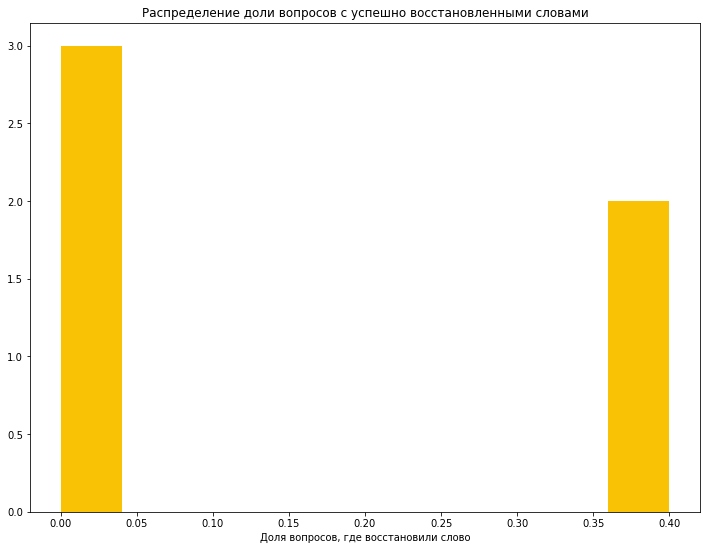

In [11]:
res = valtest_train_test_independence(sampler=sampler_rubq,
                                      model=model,
                                      test_data_type='test',
                                      is_mask_option=False,
                                      is_mask_word=True,
                                      is_split_gini_quantile=False,
                                      mask_word_iterations=5,
                                      mask_word_semaphore_threshold=(0.5, 0.7),
                                      is_info=False,
                                      masked_mmlu_options_found=None,
                                      masked_words_in_text_found=None,
                                      train_test_split_gini_quantile=None)

In [12]:
display(res['report']['result_dataframes'][0])

,Проверка,Статистика,Светофор по проверке
0,Доля восстановленных маскированных слов в текс...,0.16,green


### MMLU

100%|██████████| 5/5 [00:03<00:00,  1.36it/s]


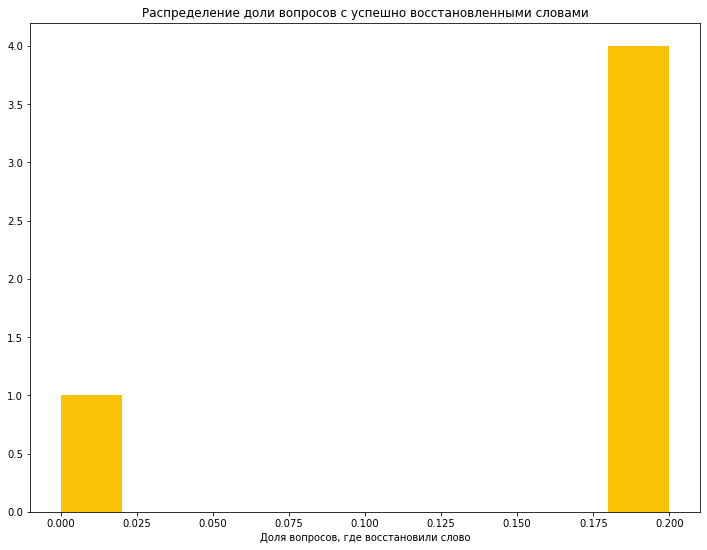

In [13]:
res = valtest_train_test_independence(sampler=sampler_mmlu,
                                      model=model,
                                      test_data_type='test',
                                      is_mask_option=True,
                                      is_mask_word=True,
                                      is_split_gini_quantile=False,
                                      mask_word_iterations=5,
                                      mask_option_semaphore_threshold=(0.01, 0.05),
                                      mask_word_semaphore_threshold=(0.5, 0.7),
                                      is_info=False,
                                      masked_mmlu_options_found=None,
                                      masked_words_in_text_found=None,
                                      train_test_split_gini_quantile=None)

In [14]:
display(res['report']['result_dataframes'][0])

,Проверка,Статистика,Светофор по проверке
0,Доля восстановленных маскированных вариантов о...,0.00,green
1,Доля восстановленных маскированных слов в текс...,0.16,green


### LongAnswer

100%|██████████| 5/5 [00:05<00:00,  1.00s/it]


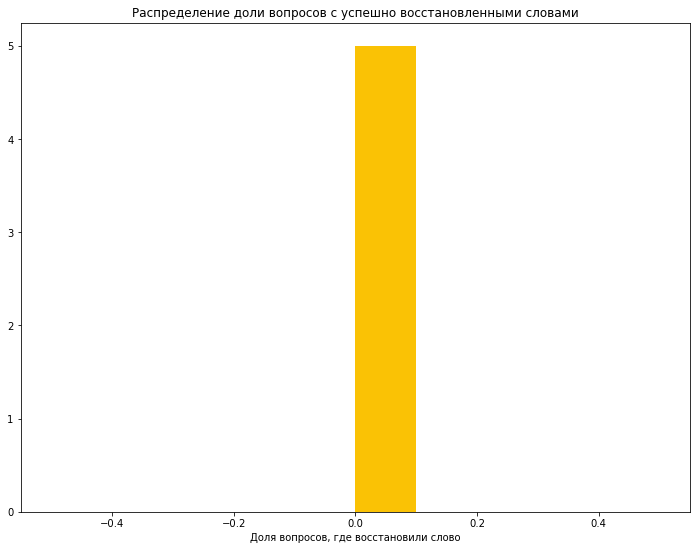

In [15]:
res = valtest_train_test_independence(sampler=sampler_la,
                                      model=model,
                                      test_data_type='test',
                                      is_mask_option=False,
                                      is_mask_word=True,
                                      is_split_gini_quantile=False,
                                      mask_word_iterations=5,
                                      mask_word_semaphore_threshold=(0.5, 0.7),
                                      is_info=False,
                                      masked_mmlu_options_found=None,
                                      masked_words_in_text_found=None,
                                      train_test_split_gini_quantile=None)

In [16]:
display(res['report']['result_dataframes'][0])

,Проверка,Статистика,Светофор по проверке
0,Доля восстановленных маскированных слов в текс...,0.0,green


# Раздел 2. Качество прогноза

## Тест 2.1. Качество прогноза модели по ключевой метрике качества

In [29]:
from llm_val.val_test.model_quality.valtest_metric import valtest_metric

### RuBQ

In [30]:
res = valtest_metric(sampler=sampler_rubq,
                     scorer=scorer,
                     main_metric='single_mean_metric_value',
                     data_type='test',
                     metric_agg='single_mean',
                     semaphore_threshold={'default': (0.2, 0.4)},
                     main_semaphore_threshold=(0.4, 0.6),
                     red_freq_threshold=0.2,
                     yellow_freq_threshold=0.2,
                     greater_is_better=True,
                     is_info=False,
                     metric_value=None)

In [31]:
display(res['report']['result_dataframes'][0])

,"Значение ключевой метрики ""single_mean_metric_value"" на test",Результат теста
0,0.8,green


### MMLU

In [32]:
res = valtest_metric(sampler=sampler_mmlu,
                     scorer=scorer,
                     main_metric='single_mean_metric_value',
                     data_type='test',
                     metric_agg='single_mean',
                     semaphore_threshold={'default': (0.2, 0.4)},
                     main_semaphore_threshold=(0.4, 0.6),
                     red_freq_threshold=0.2,
                     yellow_freq_threshold=0.2,
                     greater_is_better=True,
                     is_info=False,
                     metric_value=None)

In [33]:
display(res['report']['result_dataframes'][0])

,"Значение ключевой метрики ""single_mean_metric_value"" на test",Результат теста
0,0.6,green


### LongAnswer

In [34]:
res = valtest_metric(sampler=sampler_la,
                     scorer=scorer,
                     main_metric='single_mean_Как вы оцениваете качество CodeReview?',
                     data_type='test',
                     metric_agg='single_mean',
                     semaphore_threshold={'default': (0.2, 0.4)},
                     main_semaphore_threshold=(0.4, 0.6),
                     red_freq_threshold=0.2,
                     yellow_freq_threshold=0.2,
                     greater_is_better=True,
                     is_info=False,
                     metric_value=None)

In [35]:
display(res['report']['result_dataframes'][0])
display(res['report']['result_dataframes'][1])

,"Значение ключевой метрики ""single_mean_Как вы оцениваете качество CodeReview?"" на test",Результат теста
0,3.4,green


,Значение метрики на test,Результат теста
"single_mean_Вы согласны с замечаниями и проблемами, описанными в CodeReview?",2.2,green
single_mean_Все существенные проблемы перечислены в CodeReview?,3.0,green
"single_mean_CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?",3.0,green
single_mean_Ответ лаконичен и по существу?,3.0,green
"single_mean_Ответ структурирован, все параметры раскрыты?",2.6,green


## Тест 2.2. Качество прогноза модели по ключевой метрике качества в разрезе тематик/доменов

In [36]:
from llm_val.val_test.model_quality.valtest_metric_by_thema import valtest_metric_by_thema

### RuBQ

In [37]:
res = valtest_metric_by_thema(sampler=sampler_rubq,
                              scorer=scorer,
                              main_metric='single_mean_metric_value',
                              data_type='test',
                              metric_agg='single_mean',
                              semaphore_threshold={'default': (0.4, 0.6)},
                              greater_is_better=True,
                              is_info=False,
                              metric_value_by_thema=None)

In [38]:
display(res['report']['result_dataframes'][0])
display(res['report']['result_dataframes'][1])

,"Значение ключевой метрики ""single_mean_metric_value"" на test в разрезе тематик",Результат теста
None,0.8,green


,count
thema,
None,5


### MMLU

In [39]:
res = valtest_metric_by_thema(sampler=sampler_mmlu,
                              scorer=scorer,
                              main_metric='single_mean_metric_value',
                              data_type='test',
                              metric_agg='single_mean',
                              semaphore_threshold={'default': (0.4, 0.6)},
                              greater_is_better=True,
                              is_info=False,
                              metric_value_by_thema=None)

In [40]:
display(res['report']['result_dataframes'][0])
display(res['report']['result_dataframes'][1])

,"Значение ключевой метрики ""single_mean_metric_value"" на test в разрезе тематик",Результат теста
None,0.6,green


,count
thema,
None,5


### LongAnswer

In [41]:
res = valtest_metric_by_thema(sampler=sampler_la,
                              scorer=scorer,
                              main_metric='single_mean_Как вы оцениваете качество CodeReview?',
                              data_type='test',
                              metric_agg='single_mean',
                              semaphore_threshold={'default': (0.4, 0.6)},
                              greater_is_better=True,
                              is_info=False,
                              metric_value_by_thema=None)

In [42]:
display(res['report']['result_dataframes'][0])
display(res['report']['result_dataframes'][1])
display(res['report']['result_dataframes'][2])
display(res['report']['result_dataframes'][3])

,"Значение ключевой метрики ""single_mean_Как вы оцениваете качество CodeReview?"" на test в разрезе тематик",Результат теста
java,4.0,green
devops,2.5,green


,count
thema,
java,3
devops,2


,Значение метрики на test в разрезе тематики/домена java,Результат теста
"single_mean_Вы согласны с замечаниями и проблемами, описанными в CodeReview?",2.0,green
single_mean_Все существенные проблемы перечислены в CodeReview?,3.0,green
"single_mean_CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?",3.0,green
single_mean_Ответ лаконичен и по существу?,3.0,green
"single_mean_Ответ структурирован, все параметры раскрыты?",3.0,green


,Значение метрики на test в разрезе тематики/домена devops,Результат теста
"single_mean_Вы согласны с замечаниями и проблемами, описанными в CodeReview?",2.5,green
single_mean_Все существенные проблемы перечислены в CodeReview?,3.0,green
"single_mean_CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?",3.0,green
single_mean_Ответ лаконичен и по существу?,3.0,green
"single_mean_Ответ структурирован, все параметры раскрыты?",2.0,green


## Тест 2.3. Статистическая значимость различия значения ключевой метрики качества

In [43]:
from llm_val.val_test.model_quality.valtest_stat_significance import valtest_stat_significance

### RuBQ

In [44]:
res = valtest_stat_significance(sampler=sampler_rubq,
                                data_type='test',
                                main_column=None,
                                value_threshold=0.5,
                                extra_samplers=None,
                                same_questions=False,
                                semaphore_threshold=0.01,
                                is_info=False,
                                p_value=None)

In [45]:
display(res['report']['result_dataframes'][0])

,Значение p-value на test,Результат теста
0,0.208,red


### MMLU

In [46]:
res = valtest_stat_significance(sampler=sampler_mmlu,
                                data_type='test',
                                main_column=None,
                                value_threshold=0.5,
                                extra_samplers=None,
                                same_questions=False,
                                semaphore_threshold=0.01,
                                is_info=False,
                                p_value=None)

In [47]:
display(res['report']['result_dataframes'][0])

,Значение p-value на test,Результат теста
0,0.704,red


### LongAnswer

In [48]:
res = valtest_stat_significance(sampler=sampler_la,
                                data_type='test',
                                main_column=None,
                                value_threshold=0.5,
                                extra_samplers=None,
                                same_questions=False,
                                semaphore_threshold=0.01,
                                is_info=False,
                                p_value=None)

In [49]:
display(res['report']['result_dataframes'][0])

,Значение p-value на test,Результат теста
0,0.000059,green


## Тест 2.4.  Тест на индифферентность модели относительно входных данных

In [137]:
from llm_val.val_test.model_quality.valtest_indifferent import valtest_indifferent, get_augmented_data


Пусть у нас есть возможность воспроизвести валидируемый пайплайн на нашей стороне c помощью функции `.predict()` передаваемой в тест обертки `model`. Тогда можно использовать тест в следующем формате:

## MMLU

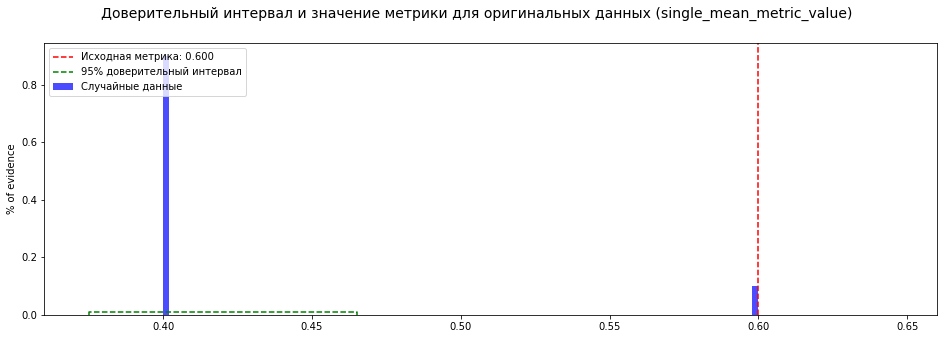

In [139]:
result = valtest_indifferent(sampler=sampler_mmlu,
                             scorer=scorer,
                             model=model,
                             confidence=0.95,
                             n_repeat=10)

In [140]:
result['report']['result_dataframes'][0]

,Значение метрики для исходных данных,Доверительный интервал для сгенерированных данных,Количество наблюдений в датасете,Результат
0,0.6,"(0.375, 0.465)",5,green


Однако нередки ситуации, когда мы не можем воспроизвести пайплайн разработчиков в том же самом месте, где находятся наши тесты, либо мы просто хотим сначала посмотреть на аугментированные данные перед прогоном теста. Тогда нужно использовать функцию `get_augmented_data`, которая вернет DataFrame с запросами, на которых применены аугментации:

In [ ]:
mmlu_aug_results = get_augmented_data(sampler_mmlu,
                                      'test',
                                      n_repeat=2)

mmlu_aug_results.index = mmlu_aug_results.index.astype(str)

Если у нас нет возможности получить предсказания через api, то мы получаем их тем способом, который нам предоставили разработчики, по полученным в аугментациях данным (здесь это `mmlu_aug_results`). При этом колонки DataFrame должны назваться `pred_aug_valtest_indifferent_idx` для каждой колонки с аугментациями `aug_valtest_indifferent_idx` соответственно.

Полученные ответы можно явно передать в тест, также просто добавив их к соответствующему датафрейму в сэмплере по ключу X:

In [ ]:
aug_answers = # получение ответов по mmlu_aug_results
sampler_mmlu.test['X'] = pd.concat([sampler_mmlu.test['X'], aug_answers], axis=1)

И запустить тест аналогично:

In [ ]:
result = valtest_indifferent(sampler=sampler_mmlu,
                             scorer=scorer,
                             confidence=0.95,
                             n_repeat=10)

Примеры запуска теста на других типах данных:

## RuBQ

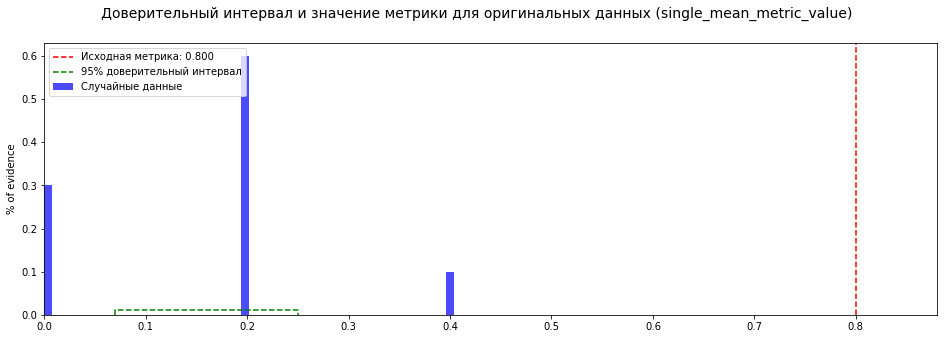

In [141]:
result = valtest_indifferent(sampler=sampler_rubq,
                             scorer=scorer,
                             model=model,
                             confidence=0.95,
                             n_repeat=10)

In [142]:
result['report']['result_dataframes'][0]

,Значение метрики для исходных данных,Доверительный интервал для сгенерированных данных,Количество наблюдений в датасете,Результат
0,0.8,"(0.07, 0.25)",5,green


## Тест 2.5. Влияние стоп-слов, популярных и редких слов на результат работы модели

In [107]:
from llm_val.val_test.model_quality.valtest_stopword_stability import valtest_metric_aug_stability

### MMLU

In [108]:
res = valtest_metric_aug_stability(sampler_mmlu, 
                                   scorer, 
                                   model)

In [109]:
res['report']['result_dataframes'][0]

,Тип преобразования,Исходное значение на test,Значение метрики после аугментации,Абсолютное изменение,Результат теста
0,stop_words,0.6,1.0,-0.4,green
1,rare_words,0.6,0.8,-0.2,green
2,popular_words,0.6,0.6,0.0,green
3,full_words,0.6,0.6,0.0,green
4,Итог,-,-,-,green


### RuBQ

In [110]:
res = valtest_metric_aug_stability(sampler_rubq,
                                   scorer,
                                   model)

In [104]:
res['report']['result_dataframes'][0]

,Тип преобразования,Исходное значение на test,Значение метрики после аугментации,Абсолютное изменение,Результат теста
0,stop_words,0.8,0.4,0.4,red
1,rare_words,0.8,0.0,0.8,red
2,popular_words,0.8,0.4,0.4,red
3,full_words,0.8,0.0,0.8,red
4,Итог,-,-,-,red


## Тест 2.6. Уникальность ответа LLM 

In [21]:
from llm_val.val_test.model_quality.valtest_answer_unique import valtest_answer_unique

### RuBQ

In [26]:
res = valtest_answer_unique(sampler=sampler_rubq, 
                            data_type='test',
                            is_long_answer=True,
                            meteor_threshold=0.9,
                            semaphore_threshold=(0.01, 0.1),
                            sample_size=1.0,
                            seed=42,
                            is_info=False,
                            usr_value=None)

In [27]:
display(res['report']['result_dataframes'][0])

,Наименование критерия на test,Значение критерия,Результат теста
0,Доля уникальных значений (USR),1.0,green


### MMLU

In [32]:
res = valtest_answer_unique(sampler=sampler_mmlu, 
                            data_type='test',
                            is_long_answer=False,
                            meteor_threshold=0.9,
                            semaphore_threshold=(0.01, 0.1),
                            is_info=False,
                            sample_size=1.0,
                            seed=42,
                            usr_value=None)

In [33]:
display(res['report']['result_dataframes'][0])

,Наименование критерия на test,Значение критерия,Результат теста
0,Доля уникальных значений (USR),0.6,green


### LongAnswer

In [34]:
res = valtest_answer_unique(sampler=sampler_la, 
                            data_type='test',
                            is_long_answer=True,
                            meteor_threshold=0.9,
                            semaphore_threshold=(0.01, 0.1),
                            sample_size=1.0,
                            seed=42,
                            is_info=False,
                            usr_value=None)

In [35]:
display(res['report']['result_dataframes'][0])

,Наименование критерия на test,Значение критерия,Результат теста
0,Доля уникальных значений (USR),1.0,green


## Тест 2.7. Качество речи финальных ответов

В тесте на качество речи проводится три проверки: 
- на орфографию (грамотность текста с точки зрения правильного написания и построения слов в предложении), за нее отвечает флаг ```test_literacy```;
- на читаемость (сложность текста для восприятия человеком), за нее отвечает флаг ```test_readability```;
- на лингвистическую приемлемость текста (грамотность построенного предложения, пунктуация и структура предложения), за нее отвечает флаг ```test_spelling```.

Для первого и последнего теста требуются библиотеки ```transformers``` и ```torch```. В примерах для этих тестов используются модели, рассчитанные на русский язык, для английского языка корректное поведение не гарантируется.

Важно! Модель в этом тесте работает только на GPU.

In [13]:
from llm_val.val_test.model_quality.valtest_speech_quality import valtest_speech_quality

### LongAnswer

In [14]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

class LiteracyModelHugWrapper:
    def __init__(self,
                 model_name: str,
                 device: str='cpu'):
        self.model = AutoModelForSequenceClassification.from_pretrained(model_name)
        self.device = device
     
    def generate(self,
                 batch: tp.Any,
                 config: tp.Dict[str, tp.Any]):
        return self.model(torch.tensor(batch['input_ids'], device=self.device),
                          torch.tensor(batch['attention_mask'], device=self.device),
                          **config)
    
    def to_device(self):
        self.model.to(self.device)
        self.model.eval()


class LiteracyTokenizerHugWrapper:
    def __init__(self, model_name: str):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
    
    def encode(self, batch: tp.Any, config: tp.Dict[str, tp.Any]):
        return self.tokenizer(batch, **config)


literacy_model_name = 'RussianNLP/ruRoBERTa-large-rucola'
literacy_model = LiteracyModelHugWrapper(literacy_model_name, device='cuda')
literacy_tokenizer = LiteracyTokenizerHugWrapper(literacy_model_name)
literacy_model_config = {}
literacy_tokenizer_config = {'encode_config': {'max_length': 512,
                                               'padding': 'max_length',
                                               'truncation': True,
                                               'return_token_type_ids': False},
                            'decode_config': {'skip_special_tokens': True}}

In [15]:
sampler_la2.test['X']['question'] = sampler_la2.test['X']['true_answer'].apply(lambda x: x[0])

In [16]:
from llm_val.utils.speech_quality.sage_model.sage_api import SageAPI

Создаем словарь для кеширования результатов API SAGE (в нем будут хранится исправленные тексты как values, а сами тексты как keys):

In [17]:
cache_sage_api = {}
sage_model_api = SageAPI(contour=contour)

В случае потери соединения при работе с моделью и прерывания работы теста нужно перезапустить ячейку с тестом - в словаре с кэшем уже сохранены все предыдущие результаты.

100%|██████████| 50/50 [01:48<00:00,  2.17s/it]


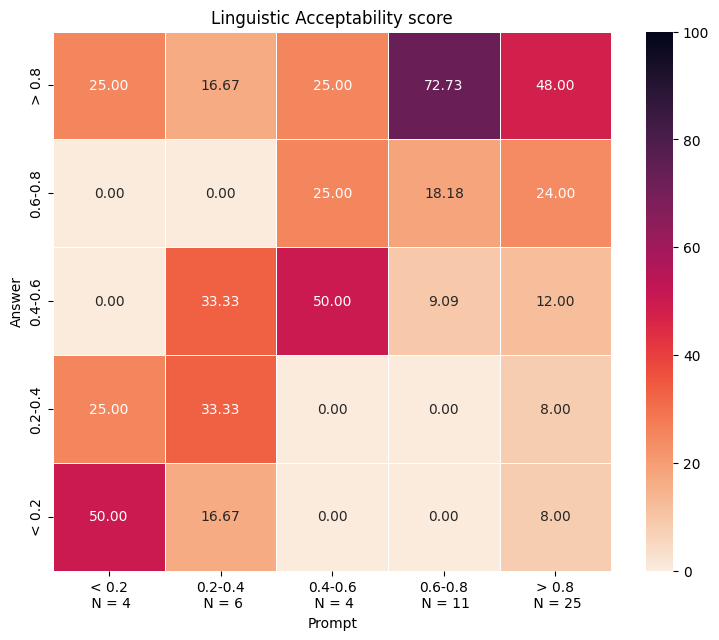

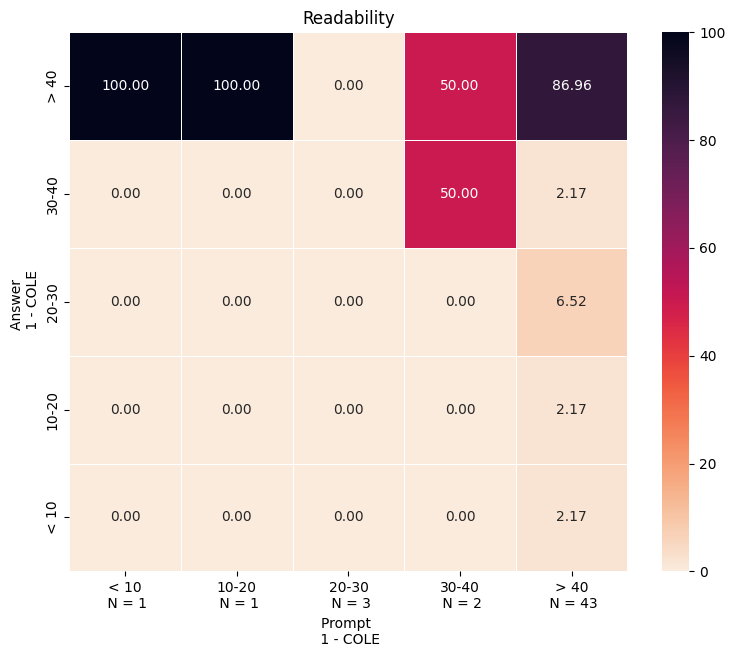

In [18]:
res = valtest_speech_quality(sampler=sampler_la2,
                             literacy_model=literacy_model,
                             literacy_tokenizer=literacy_tokenizer,
                             literacy_model_config=literacy_model_config,
                             literacy_tokenizer_config=literacy_tokenizer_config,
                             spelling_model=sage_model_api,
                             spelling_model_cache=cache_sage_api,
                             test_spelling=True,
                             test_literacy=True,
                             test_readability=True)

In [19]:
display(res['report']['result_dataframes'][0])

,Проверка,Метрика,Значение метрики на test
0,Лингвистическая грамотность,Linguistic Acceptability score,0.681156
1,Читаемость,COLE,65.467156
2,Орфография,WER,0.324415


Содержимое ```precomputed``` можно посмотреть здесь:

In [ ]:
res['precomputed']['spelling_model_cache']

## Тест 2.8 Анализ ключевой метрики при формировании финального ответа на первых n предложениях (словах) ответа LLM

### LongAnswer

In [10]:
from llm_val.val_test.model_quality.valtest_answer_head_quality import valtest_answer_head_quality

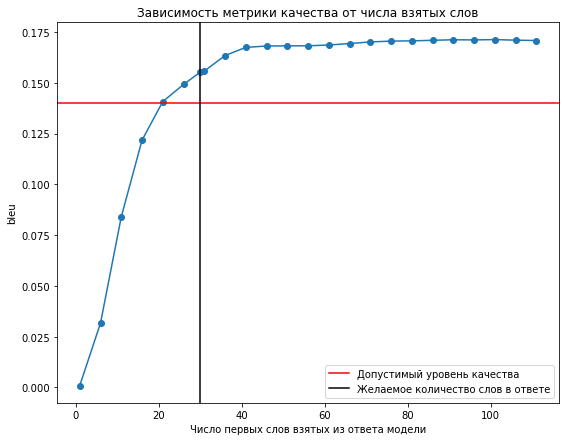

In [11]:
res = valtest_answer_head_quality(sampler=sampler_la2, 
                                  data_type='test', 
                                  metric_name='bleu', 
                                  n_head_elements=30,
                                  use_sentences=False, 
                                  step=5, 
                                  semaphore_threshold=0.14)

In [12]:
display(res['report']['result_dataframes'][0]) 

,Метрика,Значение метрики на первых 30 лексических единицах на test,Результат теста
0,bleu,0.155213,green


## Тест 2.9. Анализ корреляции human eval и автометрик (информативный тест)

### Метрики, доступные для подсчета:
    1. meteor
    2. bleu
    3. rouge
    4. cosine_dist - нужно передать свой embedder, по умолчанию используются TfidfVectorizer
    5. llm_as_judge - нужно передать judge_model с методом predict

В функцию передается список с названиями интересующих метрик. По умолчанию при переданном аргументе judge_model вычисляются первые четыре метрики. 

Пример заполнения: `metrics_to_calc=['meteor', 'bleu', 'rouge', 'cosine_dist']`

In [20]:
from llm_val.val_test.model_quality.valtest_autometrics_correlation import valtest_autometrics_correlation

In [21]:
res = valtest_autometrics_correlation(sampler=sampler_la2, 
                                      corr_threshold=0.2, 
                                      p_value_threshold=0.9)

100%|██████████| 50/50 [00:00<00:00, 549.14it/s]


In [22]:
display(res['report']['result_dataframes'][1])

,Значение корреляции автометрики с критерием 'Все существенные проблемы перечислены в CodeReview?' на test,Результат теста
meteor,-0.053284,Не коррелирующая
bleu,-0.049594,Не коррелирующая
rouge,0.134132,Не коррелирующая
cosine_dist,0.062195,Не коррелирующая


### Как запустить тест с автометрикой "LLM как судья"

Для запуска теста необходимо реализовать объект с методом `predict`, который будет обращаться к LLM и возвращать числовую оценку.  

#### Требования к объекту:
- Должен иметь метод `predict(references, prediction, **kwargs) -> str`
  - `references`: список эталонных ответов (ground truth)
  - `prediction`: ответ модели, который нужно оценить
- Внутри `predict` формируется **промпт**, который объясняет LLM задачу оценки.  
- Ответ модели должен содержать **одно число** без комментариев.  

#### Пример реализации:

In [23]:
from gigachat import GigaChat
from gigachat.models import Chat, Messages, MessagesRole


class GigaChatJudge:
    def __init__(self, model_name: str = "GigaChat-2-Max"):
        self.GIGA_CONFIG = {
            "auth_url": total_auth[contour]['OAUTH_URL'],
            "credentials": AUTH_DATA,
            "model": model_name,
            "scope": "GIGACHAT_API_CORP",
            "verify_ssl_certs": False,
            "profanity_check": False,
        }
        self.client = GigaChat(**self.GIGA_CONFIG)
        self.client.__enter__()

    def predict(self, references, prediction, **kwargs) -> str:
        """
        Отправляет запрос в GigaChat для оценки ответа.
        Формирует промпт внутри.
        """
        prompt = f"""
            Ты являешься экспертом по оценке текстовых ответов.
            Твоя задача — сравнить предсказанный ответ с набором эталонных (reference) ответов.

            Эталонные ответы:
            {chr(10).join(references)}

            Предсказанный ответ:
            {prediction}

            Оцени, насколько предсказание соответствует смыслу эталонных ответов.
            Используй шкалу от 1 до 5, где:
            - 5 = идеальное совпадение,
            - 4 = почти идеально,
            - 3 = частично верно,
            - 2 = почти неверно,
            - 1 = совершенно неверно.

            Возвращай только одно число от 1 до 5, без комментариев.
        """
        for _ in range(10):
            response = self.client.chat(
                Chat(
                    messages=[Messages(role=MessagesRole.USER, content=prompt)],
                    temperature=0.0,
                )
            )
            try:
                score = float(response.choices[0].message.content.strip().split()[0])
                return score
            except ValueError:
                print('Не удалось извлечь числовой score из ответа модели, пробуем снова...')
                response = self.client.chat(
                    Chat(
                        messages=[Messages(role=MessagesRole.USER, content=prompt)],
                        temperature=0.0,
                    )
                )
        return 0.0

In [24]:
giga_judge = GigaChatJudge()

In [25]:
res = valtest_autometrics_correlation(sampler=sampler_la2,
                                      metrics_to_calc=['meteor', 'bleu', 'rouge', 'cosine_dist', 'llm_as_judge'],
                                      corr_threshold=0.2, 
                                      p_value_threshold=0.9, 
                                      judge_model=giga_judge)

100%|██████████| 50/50 [00:16<00:00,  2.95it/s]


In [26]:
display(res['report']['result_dataframes'][1])

,Значение корреляции автометрики с критерием 'Все существенные проблемы перечислены в CodeReview?' на test,Результат теста
meteor,-0.053284,Не коррелирующая
bleu,-0.049594,Не коррелирующая
rouge,0.134132,Не коррелирующая
cosine_dist,0.062195,Не коррелирующая
llm_as_judge,0.201097,Коррелирующая


### Изменение эмбеддера для подсчета косинусного расстояния

По умолчанию в метрике `cosine_distance_score` для построения эмбеддингов используется **TF–IDF Vectorizer**.  
Однако при необходимости можно подставить собственный эмбеддер, который должен удовлетворять требованиям.  

#### Требования к эмбеддеру:
- должен иметь метод `fit_transform(texts: List[str]) -> np.ndarray`  
  **или** метод `__call__(texts: List[str]) -> np.ndarray`;  
- возвращаемая матрица эмбеддингов должна иметь форму `[n_texts, embedding_dim]`;  
- если `embedder=None`, используется стандартный `TfidfVectorizer`.  

#### Пример реализации:

In [27]:
from sentence_transformers import SentenceTransformer
import numpy as np

class SBERTEmbedder:
    def __init__(self, model_name: str = "sentence-transformers/all-MiniLM-L6-v2"):
        self.model = SentenceTransformer(model_name)

    def __call__(self, texts: tp.List[str]) -> np.ndarray:
        """
        Преобразует список строк в эмбеддинги SBERT.
        Parameters:
            texts: список строк
        Return:
            np.ndarray [n_texts, embedding_dim]
        """
        return self.model.encode(texts, convert_to_numpy=True)

In [28]:
embedder = SBERTEmbedder()

In [29]:
res = valtest_autometrics_correlation(sampler=sampler_la2, 
                                      corr_threshold=0.2, 
                                      p_value_threshold=0.9, 
                                      embedder=embedder)

100%|██████████| 50/50 [01:31<00:00,  1.82s/it]


In [30]:
display(res['report']['result_dataframes'][1])

,Значение корреляции автометрики с критерием 'Все существенные проблемы перечислены в CodeReview?' на test,Результат теста
meteor,-0.053284,Не коррелирующая
bleu,-0.049594,Не коррелирующая
rouge,0.134132,Не коррелирующая
cosine_dist,0.028379,Не коррелирующая


## Тест 2.10. Анализ динамики ключевой метрики качества модели в зависимости от длины запроса

In [6]:
from llm_val.val_test.model_quality.valtest_metric_by_answer_size import valtest_metric_by_answer_size

### RuBQ

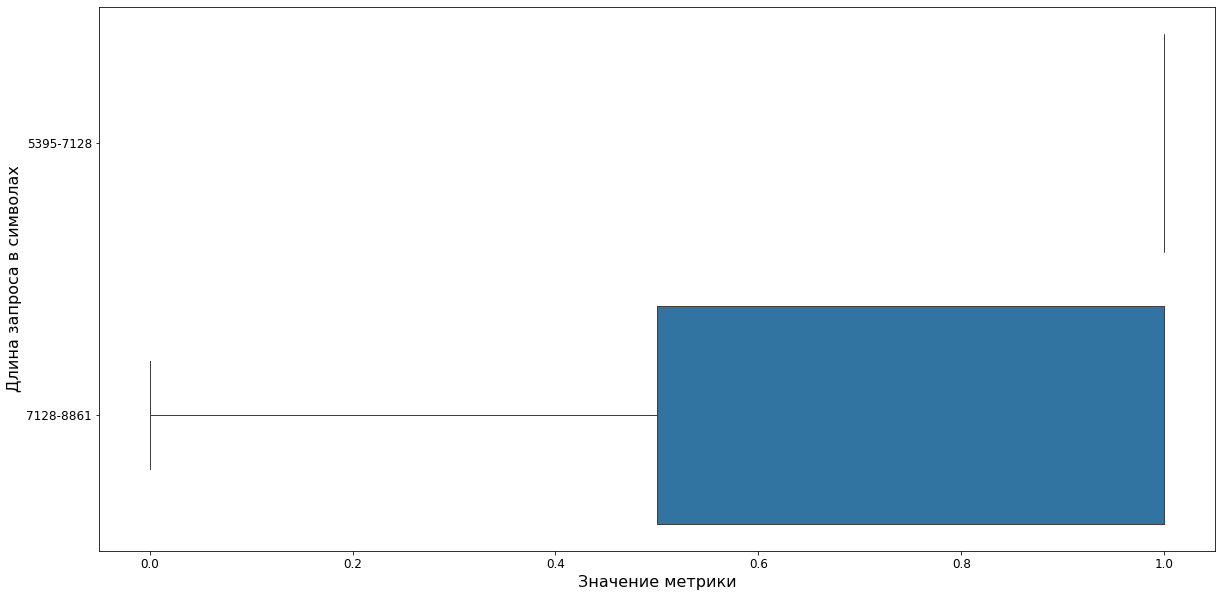

In [9]:
res = valtest_metric_by_answer_size(sampler=sampler_rubq,
                                    scorer=scorer,
                                    data_type='test',
                                    bins='freedman', 
                                    metric_agg='single_mean', 
                                    n_bootstrap=100, 
                                    quantile=0.95, 
                                    random_state=73, 
                                    semaphore_threshold=(0.05, 0.1),
                                    is_info=False)

In [10]:
display(res['report']['result_dataframes'][0])
display(res['report']['result_dataframes'][1])

,Значение критерия на test,p-value на test,Результат теста
metric_value,0.0,1.0,green


,Среднее значение метрики single_mean_metric_value,Доверительный интервал метрики single_mean_metric_value
5395-7128,1.000,[0.342; 1.000]
7128-8861,0.667,[0.208; 0.939]


### MMLU

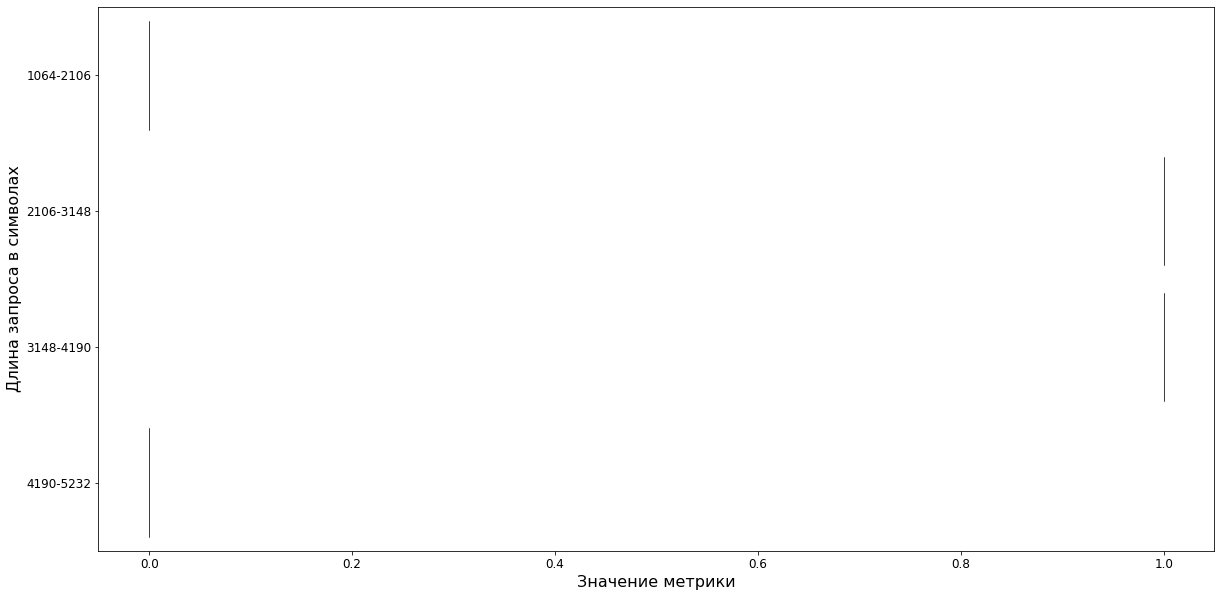

In [11]:
res = valtest_metric_by_answer_size(sampler=sampler_mmlu,
                                    scorer=scorer,
                                    data_type='test',
                                    bins='freedman', 
                                    metric_agg='single_mean', 
                                    n_bootstrap=100, 
                                    quantile=0.95, 
                                    random_state=73, 
                                    semaphore_threshold=(0.05, 0.1),
                                    is_info=False,)

In [12]:
display(res['report']['result_dataframes'][0])
display(res['report']['result_dataframes'][1])

,Значение критерия на test,p-value на test,Результат теста
metric_value,0.0,1.0,green


,Среднее значение метрики single_mean_metric_value,Доверительный интервал метрики single_mean_metric_value
1064-2106,0.000,[0.000; 0.793]
2106-3148,1.000,[0.207; 1.000]
3148-4190,1.000,[0.342; 1.000]
4190-5232,0.000,[0.000; 0.793]


### LongAnswer

/Users/20326876/.local/lib/python3.8/site-packages/scipy/stats/_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
100%|██████████| 100/100 [00:00<00:00, 4132.20it/s]


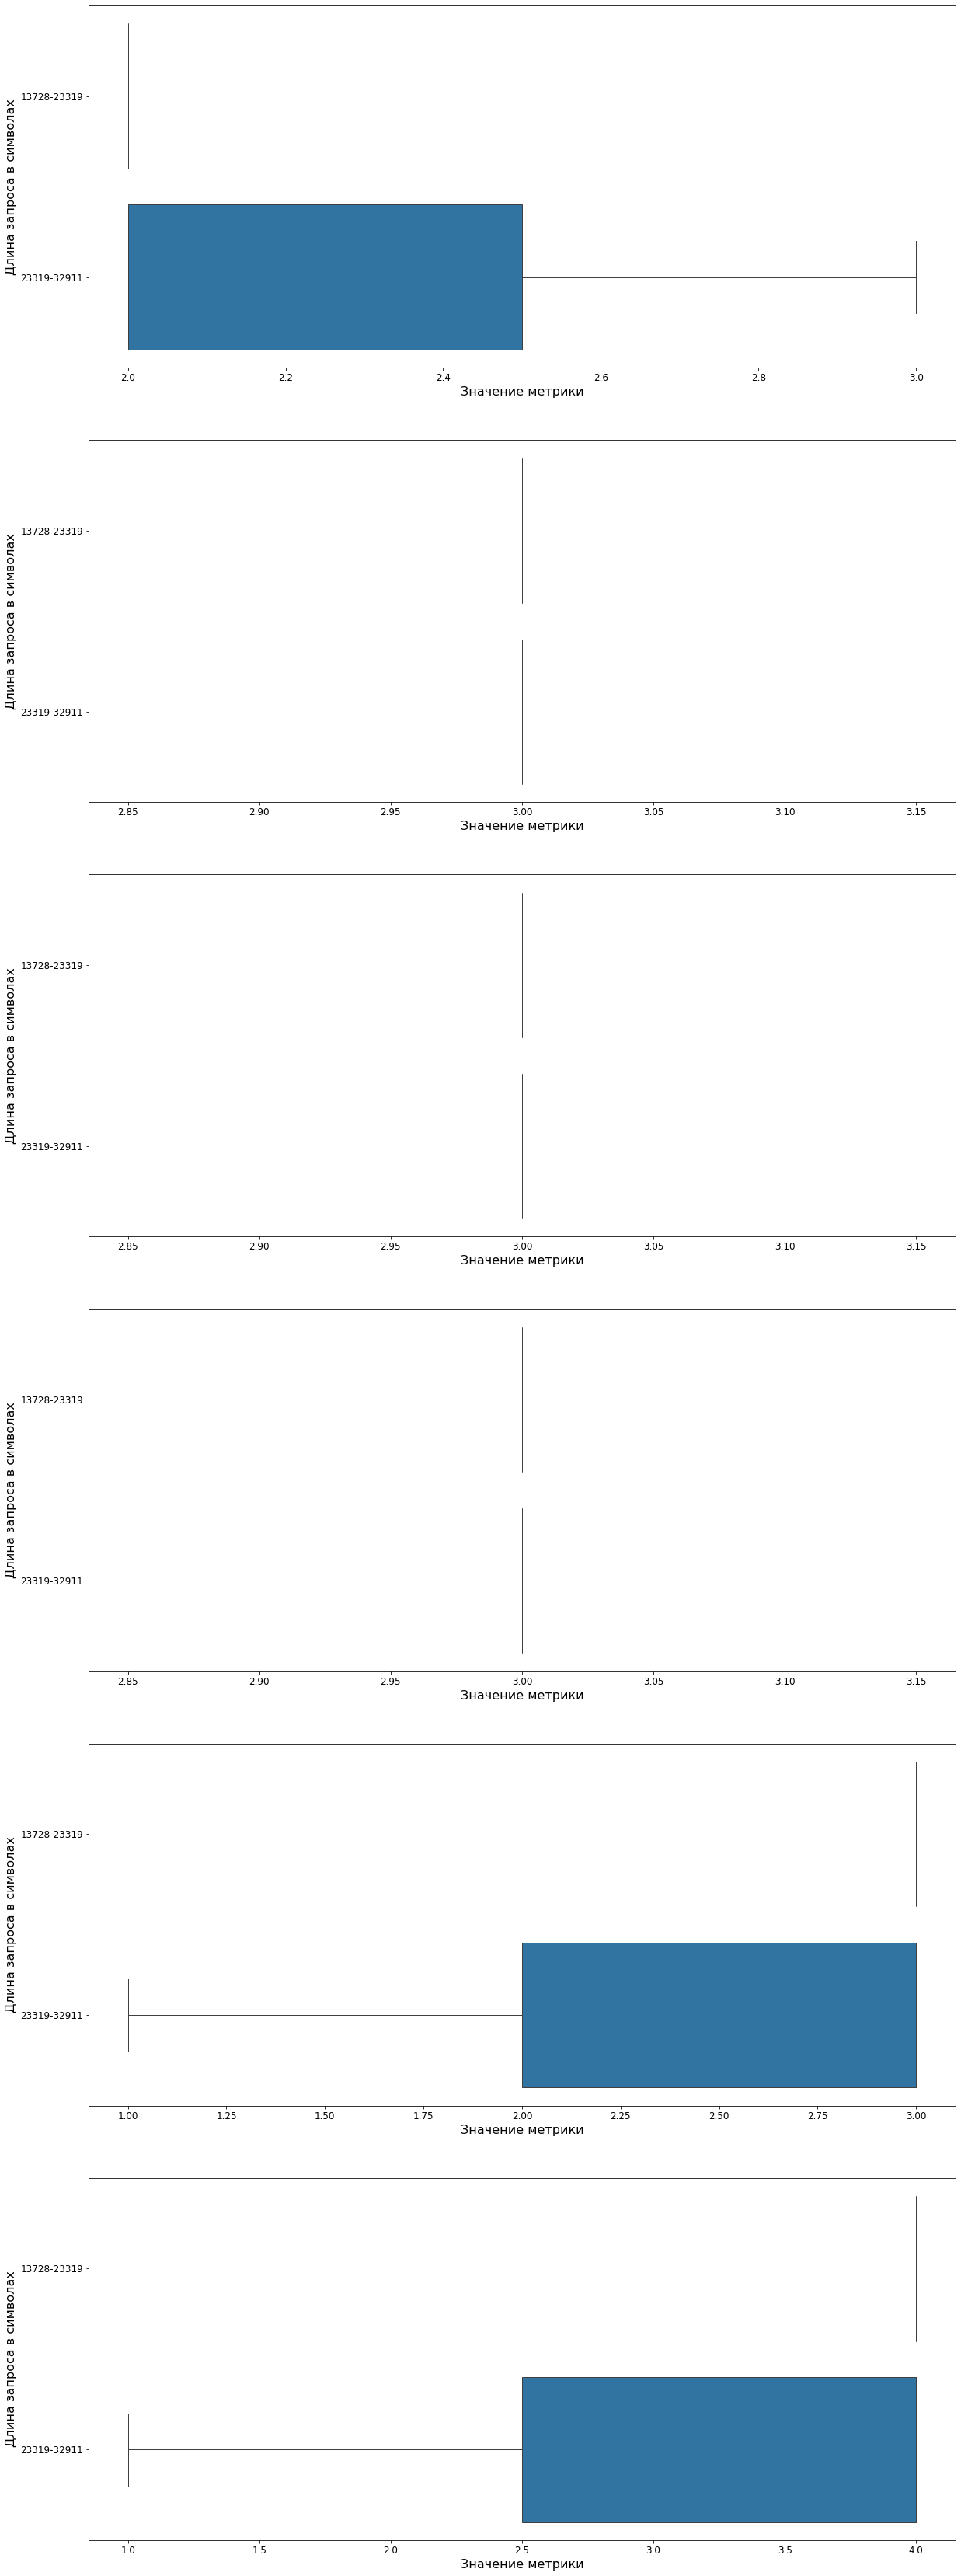

In [13]:
res = valtest_metric_by_answer_size(sampler=sampler_la,
                                    scorer=scorer,
                                    data_type='test',
                                    bins=2, 
                                    metric_agg='single_mean', 
                                    n_bootstrap=100, 
                                    quantile=0.95,
                                    random_state=73, 
                                    semaphore_threshold=(0.05, 0.1), 
                                    is_info=False,)

In [14]:
display(res['report']['result_dataframes'][0])
display(res['report']['result_dataframes'][1])
display(res['report']['result_dataframes'][2])
display(res['report']['result_dataframes'][3])
display(res['report']['result_dataframes'][4])
display(res['report']['result_dataframes'][5])
display(res['report']['result_dataframes'][6])

,Значение критерия на test,p-value на test,Результат теста
"Вы согласны с замечаниями и проблемами, описанными в CodeReview?",0.544107,0.343111,red
Все существенные проблемы перечислены в CodeReview?,NaN,NaN,gray
"CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?",NaN,NaN,gray
Ответ лаконичен и по существу?,NaN,NaN,gray
"Ответ структурирован, все параметры раскрыты?",-0.544107,0.343111,red
Как вы оцениваете качество CodeReview?,-0.544107,0.343111,red


,"Среднее значение метрики single_mean_Вы согласны с замечаниями и проблемами, описанными в CodeReview?","Доверительный интервал метрики single_mean_Вы согласны с замечаниями и проблемами, описанными в CodeReview?"
13728-23319,2.000,[2.000; 2.000]
23319-32911,2.333,[2.000; 3.000]


,Среднее значение метрики single_mean_Все существенные проблемы перечислены в CodeReview?,Доверительный интервал метрики single_mean_Все существенные проблемы перечислены в CodeReview?
13728-23319,3.000,[3.000; 3.000]
23319-32911,3.000,[3.000; 3.000]


,"Среднее значение метрики single_mean_CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?","Доверительный интервал метрики single_mean_CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?"
13728-23319,3.000,[3.000; 3.000]
23319-32911,3.000,[3.000; 3.000]


,Среднее значение метрики single_mean_Ответ лаконичен и по существу?,Доверительный интервал метрики single_mean_Ответ лаконичен и по существу?
13728-23319,3.000,[3.000; 3.000]
23319-32911,3.000,[3.000; 3.000]


,"Среднее значение метрики single_mean_Ответ структурирован, все параметры раскрыты?","Доверительный интервал метрики single_mean_Ответ структурирован, все параметры раскрыты?"
13728-23319,3.000,[3.000; 3.000]
23319-32911,2.333,[1.000; 3.000]


,Среднее значение метрики single_mean_Как вы оцениваете качество CodeReview?,Доверительный интервал метрики single_mean_Как вы оцениваете качество CodeReview?
13728-23319,4.000,[4.000; 4.000]
23319-32911,3.000,[1.000; 4.000]


## Тест 2.11. Анализ уверенности LLM в ошибочных ответах (Информативный тест)

In [146]:
from llm_val.val_test.model_quality.valtest_confidence_in_incorrect_answers import valtest_confidence_in_incorrect_answers

Создадим пример фунции получения эмбеддингов:
 - Функция emb_fast позволяет получать эмбеддинги для списка текстовых данных, используя многопоточность. 

 - Функция принимает на вход список текстовых данных (data) и количество потоков (pool_num) и возвращает список эмбеддингов.




In [147]:
from tqdm import tqdm
from multiprocess import Pool
from langchain_community.embeddings import GigaChatEmbeddings

embeddings_gc_func = GigaChatEmbeddings(verify_ssl_certs=False, 
                                        scope='GIGACHAT_API_CORP',
                                        credentials='INSERT_YOUR_CLIENT_SECRET_HERE',
                                        auth_url='https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',
                                        base_url='https://gigachat.devices.sberbank.ru/api/v1')

def emb_fast(data, 
             pool_num=5):
    answers = []
    with Pool(pool_num) as p:
        for res in tqdm(p.imap(embeddings_gc_func.embed_query, data)):
            answers.append(res)
    return answers

Создадим обертку модели, в которую можно подавать температуру:

 - Класс ConfidWrapper — это обертка для модели, которая позволяет изменять температуру при генерации ответов. 
 
 - Метод predict принимает температуру и вопрос и возвращает ответ модели.

In [148]:
class ConfidWrapper:
    def __init__(self):
        self.model = BaseGigaModel(rquid=RQUID,
                                   auth_data=AUTH_DATA,
                                   oauth_url=total_auth[contour]['OAUTH_URL'],
                                   api_url=total_auth[contour]['API_URL'],
                                   token=total_auth[contour]['TOKEN'],
                                   temperature=0.7,
                                   profanity_check=False,
                                   model='GigaChat-Pro')

    def predict(self, 
                temp, 
                question):
        self.model.temperature = temp
        return self.model.predict([question])[0]          

In [149]:
model_Config = ConfidWrapper()

### RuBQ

1it [00:00,  1.34it/s]
1it [00:00,  1.52it/s]
1it [00:00,  1.42it/s]
1it [00:00,  1.35it/s]
1it [00:00,  1.44it/s]
1it [00:00,  1.18it/s]
1it [00:00,  1.05it/s]
1it [00:00,  1.40it/s]
1it [00:00,  1.34it/s]
1it [00:00,  1.50it/s]
1it [00:00,  1.18it/s]
1it [00:00,  1.47it/s]
1it [00:00,  1.33it/s]
1it [00:00,  1.36it/s]
1it [00:00,  1.18it/s]
1it [00:00,  1.49it/s]
1it [00:00,  1.35it/s]
1it [00:00,  1.51it/s]
1it [00:00,  1.51it/s]
1it [00:00,  1.35it/s]


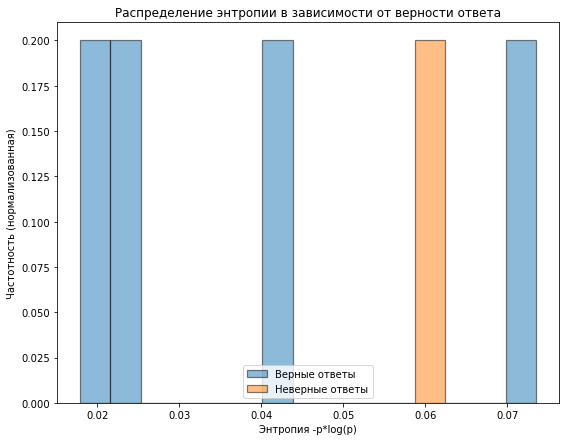

In [150]:
res = valtest_confidence_in_incorrect_answers(sampler=sampler_rubq,
                                              model=model_Config,
                                              get_embed_func=emb_fast,
                                              data_type='test',
                                              repeat_num=3,
                                              high_temp=1.5)

При тестировании теста на MMLU датасетах даже при увеличении температуры не удалось получить увеличение энтропии. Это может быть связано с тем, что на тестовых вопросах уверенность GigaChat очень высока.

### MMLU

1it [00:00,  1.36it/s]
1it [00:00,  1.47it/s]
1it [00:00,  1.44it/s]
1it [00:00,  1.45it/s]
1it [00:00,  1.45it/s]


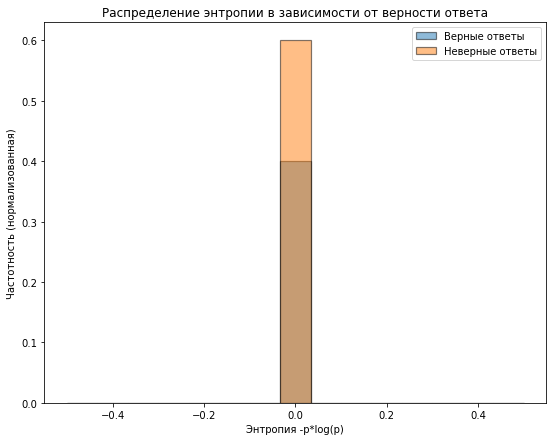

In [151]:
res = valtest_confidence_in_incorrect_answers(sampler=sampler_mmlu,
                                              model=model_Config,
                                              data_type='test',
                                              repeat_num=2,
                                              high_temp=1.5,
                                              get_embed_func=emb_fast)

# Раздел 3. Качество RAG

Для тестов раздела о качестве RAG-систем была создана новая, наравне с `Sampler` и `Scorer`, сущность - `RAGExecutor`. В реализации этой сущности должна происходить обработка текстов, их нарезка и укладка в векторную базу данных, которая должна позволять осуществлять поиск близких пассажей. Также внутри `RAGExecutor` необходимо иметь возможность вызывать получение эмбеддингов. Инициализация `RAGExecutor`'а осуществляется для всех тестов раздела.

`RAGExecutor` должен включать в себя следующие обязательные функции и методы:

* `get_parameters()` - метод, который должен возвращать основные параметры работы `RAGExecutor`'а;
* `embed_text(text)` - метод, который должен возвращать эмбеддинг для текста с использованием инициализированного внутри `RAGExecutor`'а эмбеддера. На вход получает текст, который обрабатывает и токенизирует согласно `text_process_config` и `encode_config`, а затем выдает эмбеддинг обработанного текста;
* `get_passages_with_embeddings(baseline, chunk_size, chunk_overlap)` - метод, который должен по ключу, формирующемуся из трех параметров входа, возвращать набор пассажей с их эмбеддингами. Должна быть реализована возможность обращения к `baseline` нарезке из векторной базы данных (при `baseline=True`) и к новым нарезкам из векторной базы данных (`baseline=False`, `chunk_size=N`, `chunk_overlap=M`, где `N` и `M` - размер пассажа и величина перекрытия соответственно);
* `get_topK_passages(baseline, questions, topK, chunk_size, chunk_overlap)` - метод, который должен возвращать `topK` релевантных к каждому элементу `questions` пассажей. Должна быть реализована возможность обращения к `baseline` нарезке из векторной базы данных (при `baseline=True`) и к новым нарезкам из векторной базы данных (`baseline=False`, `chunk_size=N`, `chunk_overlap=M`, где `N` и `M` - размер пассажа и величина перекрытия соответственно).
* `get_llm_answers(baseline, questions, systems, topK, chunk_size, chunk_overlap)` - метод, который должен возвращать словарь с ответами LLM и их эмбеддингами к каждому элементу `questions` под ключами `llm_answer` и `llm_answer_embedding` соответственно. Должна быть реализована возможность обращения к `baseline` нарезке из векторной базы данных (при `baseline=True`) и к новым нарезкам из векторной базы данных (`baseline=False`, `chunk_size=N`, `chunk_overlap=M`, где `N` и `M` - размер пассажа и величина перекрытия соответственно).


В библиотеке есть пример реализации сущности RAGExecutor под таким же названием. Обратите внимание, что в нем (на данный момент) поддерживается использование только pdf и txt файлов.

Для использования имеющегося `RAGExecutor`'а и дальнейшего проведения тестов раздела о качестве RAG-систем необходимо наличие локального репозитория с эмбеддером `e5-large`. Ссылки для скачивания: 

Sigma: https://sberosc.sigma.sbrf.ru/repo/hosted//hosted/ModelsDS/1abdf830-56e5-4b4a-96cf-2d32010abf2f/intfloat_multilingual-e5-large.zip

Alpha: https://sberosc.ca.sbrf.ru/repo/hosted//hosted/ModelsDS/1abdf830-56e5-4b4a-96cf-2d32010abf2f/intfloat_multilingual-e5-large.zip

### Инициализируем сущность `RAGExecutor`'а

In [16]:
from llm_val.ragexecutor.RAGExecutor import RAGExecutor

Для инициализации `RAGExecutor` необходимо указать следующие параметры и конфиги:

`embed_model_path` - путь до локальной модели-эмбеддера, в ячейке ниже записан в переменную `e5_path`

`encode_config` - параметры токенизации модели-эмбеддера, в ячейке ниже записан в переменную `e5_encode`

`text_process_config` - параметры предобработки текста перед векторизацией, в ячейке ниже записан в переменную `text_process_config`

`documents_paths` - путь или список путей до документов для построения векторной базы данных, записан в одноименную переменную

`vectorstore_path` - путь до директории, где будет располагаться векторная база данных, записан в одноименную переменную

In [117]:
e5_path = '../src/llm_val/model/Embedder/multilingual-e5-large'
e5_encode = {
    'max_length': 512,
    'padding': True,
    'truncation': True,
    'return_tensors': 'pt'
}
text_process_config = {
    'use_text_cleaner': True,
    'use_lemmatization': True,
    'language': 'russian',
    'stopwords_path': 'data/brainstorm/ru_stop_words.txt'
}
documents_paths = 'data/sample_text_rag.txt'
vectorstore_path = 'data/rag_vectorstore'

Для проведения всех тестов используется один инстанс `RAGExecutor`.  

#### Инициализируем модель для `RAGExecutor`:

In [ ]:
from langchain.chat_models import GigaChat

In [ ]:
chat_model = GigaChat(auth_url='https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',
                      credentials=AUTH_DATA,
                      verify_ssl_certs=False,
                      scope='GIGACHAT_API_CORP')

`RAGExecutor` должен принимать в себя параметры, подходящие для каждого из тестов раздела "3. Качество RAG", посколько он используется во всех этих тестах:

In [18]:
executor_rag = RAGExecutor(embed_model_path=e5_path,
                           encode_config=e5_encode,
                           text_process_config=text_process_config,
                           documents_paths=documents_paths,
                           vectorstore_path=vectorstore_path,
                           topK=3,
                           chunk_size=800,
                           chunk_overlap=200,
                           topK_list=[0,1,2,3,4,5],
                           chunk_size_list=[600,800,1000],
                           chunk_overlap_list=[50,100,150],
                           chat_model=chat_model)

Creating an Extended Vectorstore: 100%|██████████| 12/12 [04:36<00:00, 23.06s/it]


## Тест 3.1. Ключевая метрика качества RAG

In [312]:
from llm_val.val_test.rag_quality.valtest_rag_quality import valtest_rag_quality

In [313]:
res = valtest_rag_quality(sampler=sampler_rag,
                          topk=3,
                          key_metric='HitRate@k',
                          metric_list=['HitRate@k',
                                       'nDCG@k',
                                       'Recall@k', 
                                       'MAP@k', 
                                       'MP@k', 
                                       'AUC@k', 
                                       'ERR@k', 
                                       'MRR@k'])

In [314]:
display(res['report']['result_dataframes'][0])

,Название метрики,Значение метрики,Доверительный интервал,Результат теста
0,HitRate@k,0.800000,0.376 - 0.964,green
1,nDCG@k,0.726186,0.318 - 0.938,gray
2,Recall@k,0.800000,0.376 - 0.964,gray
3,MAP@k,0.700000,0.299 - 0.927,gray
4,MP@k,0.333333,0.087 - 0.725,gray
5,AUC@k,0.900000,0.463 - 0.989,gray
6,ERR@k,0.400000,0.118 - 0.769,gray
7,MRR@k,0.700000,0.299 - 0.927,gray


## Тест 3.2. Качество прогноза модели по ключевой метрике качества в разрезе релевантности поиска пассажа (в разрезе качества работы RAG)

In [524]:
from llm_val.val_test.rag_quality.valtest_rag_search_quality import valtest_rag_search_quality

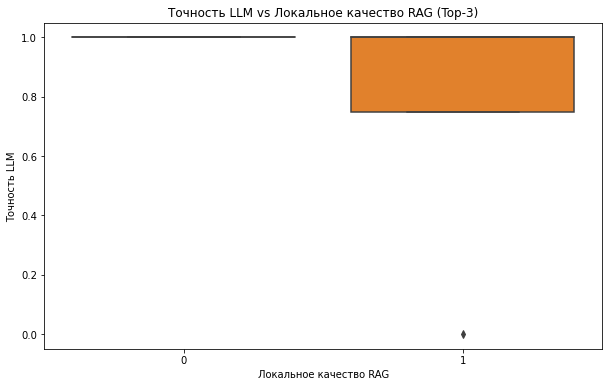

In [525]:
res = valtest_rag_search_quality(sampler_rag,
                                 topk=3)

In [526]:
display(res['report']['result_dataframes'][0])

,Наименование метрики,Корреляция
0,HitRate@3,-0.250000
1,HitRate@2,-0.250000
2,HitRate@1,-0.408248


## Тест 3.3 Анализ динамики ключевой метрики качества при увеличении размера ТОПа найденных документов

In [127]:
from llm_val.val_test.rag_quality.valtest_rag_quality_by_k_passages import valtest_rag_quality_by_k_passages

Итерирование по top-K пассажам: 100%|██████████| 5/5 [01:06<00:00, 13.26s/it]


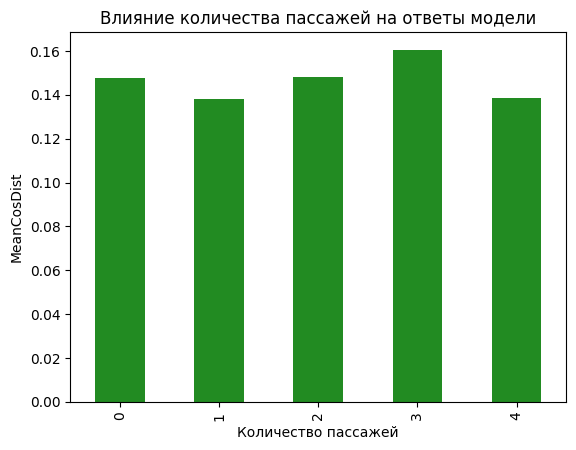

In [129]:
res = valtest_rag_quality_by_k_passages(sampler=sampler_rag,
                                        executor=executor_rag)

In [130]:
res['report']['result_dataframes'][0]

,num_passages,metrics
0,0,0.147829
1,1,0.138054
2,2,0.148280
3,3,0.160496
4,4,0.138645


## Тест 3.4. Unsupervised оценка качества построения эмбеддингов

In [123]:
from llm_val.val_test.rag_quality.valtest_unsupervised_rag_quality import valtest_unsupervised_rag_quality

Для корректной работы теста необходимо задать промпты для модели генерации вопроса и для модели, оценивающей релевантность опроса чанку. Выход из модели генерации вопроса ОБЯЗАТЕЛЬНО должен содержать поля Вопрос и Ответ -- на это опирается парсер выхода из модели. Выход из модели-критика должен обязательно содержать поле Оценка.

Несмотря на заданный формат выхода, нужно быть внимательным с генерацией вопросов, поскольку GC может ошибаться с форматом и генерировать некорректные вопросы.

In [124]:
question_generation_prompt = '''
Твоя задача - написать фактологический вопрос и ответ с учетом контекста.
На твой фактологический вопрос следует ответить конкретной, краткой фактической информацией из контекста.
Твой фактологический вопрос должен быть сформулирован в том же стиле, что и вопросы, которые пользователи могли бы задавать в поисковой системе.
Старайся использовать более простую речь, чем в предоставленных контекстах. Формулируй свои вопросы будто ты обычный пользователь средних лет из России.
Используй простые и просторечные формулировки.
В вашем фактологическом вопросе НЕ ДОЛЖНО упоминаться что-то вроде "согласно отрывку" или "контекст".

Свой ответ оформляй следующим образом:

Output:::
Вопрос: (сгенерированный фактологический вопрос)
Ответ: (Твой ответ на сгенерированный вопрос)

Твой ответ ДОЛЖЕН содержать поля 'Вопрос' и 'Ответ'. Верни только ОДИН вопрос.
'''

critic_prompt = '''
Тебе будут даны вопрос и некоторый контекст.
Твоя задача - оценить, насколько подробно и однозначно можно ответить на вопрос при помощи данного контекста.
Дай ответ по шкале от 1 до 5, где 1 означает абсолютное отсутствие возможности ответить на вопрос при помощи контекста, а 5 означает, что контекст дает возможность подробно и однозначно полкостью ответить на вопрос.

Свой ответ оформляй следующим образом:

Answer:::
Обоснование: (Твое обоснование, почему ты даешь такую оценку)
Оценка: (твоя оценка, число от 1 до 5)

Твой ответ ДОЛЖЕН содержать поля 'Обоснование' и 'Оценка'.

'''

In [125]:
question_generation_model = MultiThreadGigaModel(n_jobs=8,
                                                 rquid=RQUID,
                                                 auth_data=AUTH_DATA,
                                                 oauth_url=total_auth[contour]['OAUTH_URL'],
                                                 api_url=total_auth[contour]['API_URL'],
                                                 token=total_auth[contour]['TOKEN'],
                                                 sys_promt=question_generation_prompt)

critic_model = MultiThreadGigaModel(n_jobs=8,
                                    rquid=RQUID,
                                    auth_data=AUTH_DATA,
                                    oauth_url=total_auth[contour]['OAUTH_URL'],
                                    api_url=total_auth[contour]['API_URL'],
                                    token=total_auth[contour]['TOKEN'],
                                    sys_promt=critic_prompt)

In [126]:
res = valtest_unsupervised_rag_quality(executor=executor_rag,
                                       question_generation_model=question_generation_model,
                                       critic_model=critic_model,
                                       hit_rate_relevance_threshold=2)

In [127]:
display(res['report']['result_dataframes'][0])

,Метрика,Значение,Светофор
0,hit_rate_1,0.80,green
1,hit_rate_5,0.96,green
2,average_place,1.40,gray


## Тест 3.5. Анализ динамики ключевой метрики качества модели при изменении размера пассажа и величины перекрытия

In [20]:
from llm_val.val_test.rag_quality.valtest_rag_quality_by_length import valtest_rag_quality_by_length

В тесте реализовано два варианта оценки качества RAG-системы:
1. Оценка качества на основе близости top-K релевантных вопросу пассажей к правильному ответу (при наличии) на этот вопрос (`use_llm=False`)
2. Оценка качества на основе близости сгенерированного LLM ответа на вопрос с учетом top-K релевантных вопросу пассажей к правильному ответу (при наличии) на этот вопрос (`use_llm=True`)

Iterating Through Chunks Size & Chunks Overlap: 100%|██████████| 9/9 [00:20<00:00,  2.25s/it]


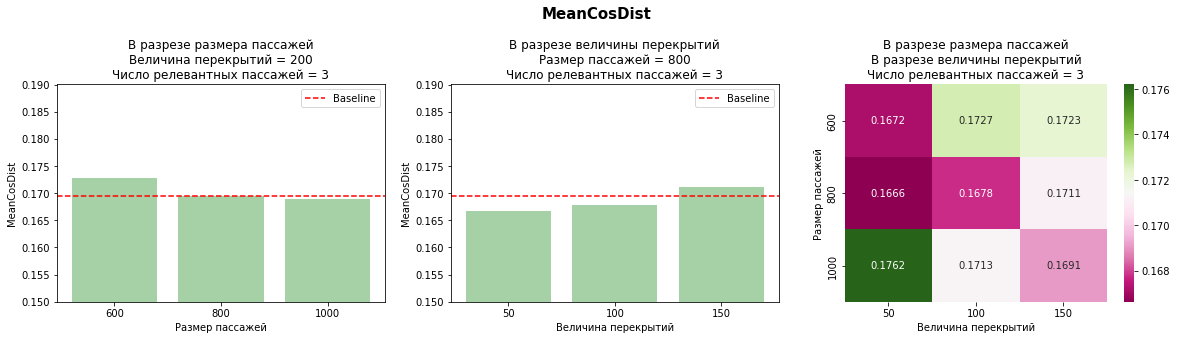

In [21]:
report = valtest_rag_quality_by_length(sampler=sampler_rag,
                                       executor=executor_rag,
                                       data_type='test',
                                       test_by='true_answer',
                                       use_llm=True,
                                       eval_metric='MeanCosDist',
                                       cos_dist_threshold=0.25)

In [22]:
report['report']['result_dataframes'][0]

,Медианный размер пассажей,2.5%-й квантиль размера пассажей,97.5%-й квантиль размера пассажей,Величина перекрытий,Число релевантных пассажей,MeanCosDist
Размер пассажей,,,,,,
600,560.0,456.05,597.0,200,3,0.17277
800,753.0,498.0,783.25,200,3,0.16948
1000,929.0,704.025,988.6,200,3,0.168864


In [23]:
report['report']['result_dataframes'][1]

,Медианный размер пассажей,2.5%-й квантиль размера пассажей,97.5%-й квантиль размера пассажей,Размер пассажей,Число релевантных пассажей,MeanCosDist
Величина перекрытий,,,,,,
50,759.0,120.875,792.55,800,3,0.166636
100,753.0,258.0,789.0,800,3,0.167771
150,753.0,258.0,789.0,800,3,0.171129


In [24]:
report['report']['result_dataframes'][2]

Величина перекрытий                    
                                     50        100       150
Размер пассажей 600             0.167189  0.172732  0.172329
                800             0.166636  0.167771  0.171129
                1000            0.176205  0.171284  0.169077

# Раздел 4. Спецификация NER

## Тест 4.1. Подсчет метрик качества NER-моделей при различных критериях оценки

In [7]:
from llm_val.val_test.model_quality.valtest_metric import valtest_metric

In [8]:
res = valtest_metric(sampler=sampler_ner,
                     scorer=scorer_ner,
                     main_metric='micro_f1',
                     data_type='test',
                     metric_agg='ner_exact_match_micro_f1',
                     semaphore_threshold={'default': (0.4, 0.6)},
                     main_semaphore_threshold=(0.4, 0.6),
                     red_freq_threshold=0.2,
                     yellow_freq_threshold=0.2,
                     greater_is_better=True,
                     is_info=False,
                     metric_value=None)

In [9]:
display(res['report']['result_dataframes'][0])

,"Значение ключевой метрики ""micro_f1"" на test",Результат теста
0,0.754037,yellow


In [10]:
display(res['report']['result_dataframes'][1])

,Значение метрики на test,Результат теста
Drugname_f1,0.902027,green
Drugclass_f1,0.910053,green
Drugform_f1,0.936255,green
DI_f1,0.669091,green
ADR_f1,0.565421,yellow
Finding_f1,0.299213,red


## Тест 4.2. Анализ соответствия выхода модели фиксированному формату

In [11]:
from llm_val.val_test.specification_ner.valtest_format_compliance import valtest_format_compliance

In [12]:
res = valtest_format_compliance(sampler=sampler_ner)

In [13]:
display(res['report']['result_dataframes'][0])

,Проверка,Значение на test
0,Доля искажений текста сущности (извлеченные),0.0156
1,Доля искажений текста сущности (размеченные),0.0145
2,Доля несоответствий предсказаний заданному фор...,0.0000


## Тест 4.3. Анализ качества модели в разрезе конфликтующих предсказаний (Информативный тест)

In [14]:
from llm_val.val_test.specification_ner.valtest_conflicting_predictions_analysis import valtest_conflicting_predictions_analysis

In [15]:
res = valtest_conflicting_predictions_analysis(sampler=sampler_ner)

In [16]:
display(res['report']['result_dataframes'][0])

,Проверка,Значение на test
0,Доля текстов с конфликтующими предсказаниями с...,0.005544
1,Средняя разность между предсказанным количеств...,-1.166667
2,"Средняя доля строк, признанных конфликтующим п...",0.059524
3,"Среднее количество вхождений строк, признанных...",1.875000


## Тест 4.4. Анализ качества модели при распознавании всех типов сущностей/сущностей по отдельности за один запрос (Информативный тест)  

In [19]:
from llm_val.val_test.specification_ner.valtest_metric_by_request_type import valtest_metric_by_request_type

In [20]:
res = valtest_metric_by_request_type(sampler=sampler_ner, main_metric='macro_f1')

In [21]:
display(res['report']['result_dataframes'][0])

,Тип запроса,Значение метрики macro_f1 на test
0,Все классы,0.713676
1,По одному классу,0.713676


## Тест 4.5. Анализ качества NER-модели при варьировании детализации описания распознаваемых сущностей.

In [22]:
from llm_val.val_test.specification_ner.valtest_entity_description_quality_analysis import valtest_entity_description_quality_analysis

In [23]:
res = valtest_entity_description_quality_analysis(sampler=sampler_ner)

In [24]:
display(res['report']['result_dataframes'][0])

,Вариант описания,Значение метрики macro_f1 на test,Абсолютный прирост,Результат теста
0,Исходное описание,0.713676,0.000000,green
1,Детализированное описание,0.713676,0.000000,green
2,Добавление примеров,0.713676,0.000000,green
3,Детализированное описание с примерами,1.000000,0.286324,red


## Тест 4.6 Анализ распределения ошибок предсказаний NER-модели в разрезе классов распознаваемых сущностей (Информативный тест)

In [25]:
from llm_val.val_test.specification_ner.valtest_error_distribution_analysis import valtest_error_distribution_analysis

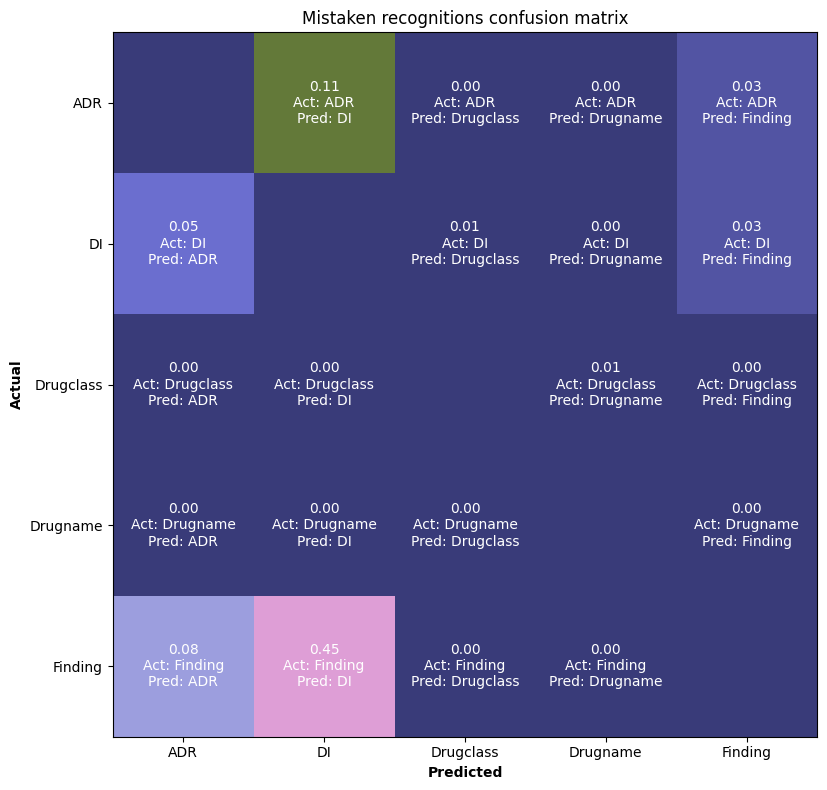

In [26]:
res = valtest_error_distribution_analysis(sampler=sampler_ner)

In [27]:
display(res['report']['result_dataframes'][0])

,Класс,Максимальная доля ошибок на test,Результат теста
0,Finding,0.452055,yellow
1,DI,0.047281,green
2,ADR,0.105485,green
3,Drugclass,0.010417,green


# Раздел 5. Спецификация QA&KD

## 5.1.	 Анализ качества на ClosedQA (MMLU-like) датасете, сгенерированного на основе OpenQA (RBQ-like)

Для проведения теста необходима модель для генерации неправильных ответов и промпт для этой модели.

Подобранный промпт в реализации теста может давать разный результат при изменении версии модели. По умолчанию в этом примере 
используется GigaChat-Max. Если у вас уже есть данные в формате MMLU для проведения теста, то достаточно передать их в параметр теста `data_mmlu_test`.

Для достижения наилучшего результата при генерации неправильных вариантов ответа важно учитывать несколько ключевых требований к `generate_prompt`:



- Укажите, что модель должна возвращать только список неправильных ответов без дополнительных пояснений.
- Если возможно, добавьте примеры того, как должны выглядеть неправильные ответы. Это поможет модели лучше понять, что от нее ожидается.
- Укажите, что при генерации неправильных вариантов ответа разделительный символ должен быть '\n'. Это можно сделать, например, фразой: "Перечисляй варианты не через запятые, а обязательно через символ '\n'"
- Промпт должен четко описывать задачу и формат ответа.
- `'question'`, `'correct_answer'` и `'num_incorrect_options'` обязательно должны быть в промпте: (см.пример)



* `'question'` - Вопрос, на который необходимо сгенерировать неправильные варианты ответов.
* `'correct_answer'` - Правильный вариант ответа
* `'num_incorrect_options'` - Количество неправильных вариантов, которые нужно сгенерировать.

In [120]:
generate_prompt = f"""
        Тебе дан вопрос: 'question'. На основании правильного ответа: 'correct_answer', предложи 'num_incorrect_options' варианта измененных неправильных ответов.
        Важно! Верни ТОЛЬКО список неправильных ответов! 
        ВАЖНО! Перечисляй варианты обязательно через символ '\n'
        """

In [121]:
model_max = MultiThreadGigaModel(n_jobs=1,
                                 rquid=RQUID,
                                 temperature=0.2,
                                 auth_data=AUTH_DATA,
                                 oauth_url=total_auth[contour]['OAUTH_URL'],
                                 api_url=total_auth[contour]['API_URL'],
                                 token=total_auth[contour]['TOKEN'],
                                 profanity_check=False,
                                 model='GigaChat-Max')

In [122]:
from llm_val.val_test.specification_qa_kd.valtest_rubq2mmlu import valtest_rubq2mmlu

In [123]:
result = valtest_rubq2mmlu(sampler_rubq,
                           scorer=scorer, 
                           model=model_max, 
                           model_incorrect_gen=model,
                           generate_prompt=generate_prompt)

In [124]:
result['report']['result_dataframes'][0]

,Наименование ключевой метрики,Прирост ключевой метрики (КМ) качества,Результат теста
0,single_mean_metric_value,0.00%,yellow


## Тест 5.2. Анализ качества на RBQ-like (1-hop) датасете, сгенерированном на основе ClosedQA

In [10]:
from llm_val.val_test.specification_qa_kd.valtest_rubq_from_mmlu_metric import valtest_rubq_from_mmlu_metric

In [11]:
def rewrite_question(question_list):
    question_list = [x for x in question_list]
    return question_list

### MMLU

In [12]:
res = valtest_rubq_from_mmlu_metric(sampler=sampler_mmlu,
                                    scorer=scorer,
                                    model=model,
                                    rewrite_question=rewrite_question,
                                    data_type='test',
                                    metric_name='single_mean',
                                    metric_value_rubq_from_mmlu=None)

In [10]:
display(res['report']['result_dataframes'][0])

,Значение метрики
single_mean_metric_value,0.2


# Раздел 6. Спецификация Chat

## Тест 6.1 Анализ распознавания сгенерированных текстов (Информативный тест) 

In [5]:
from llm_val.val_test.specification_chat.valtest_generated_recognition_analysis import valtest_generated_recognition_analysis

100%|██████████| 200/200 [03:16<00:00,  1.02it/s]


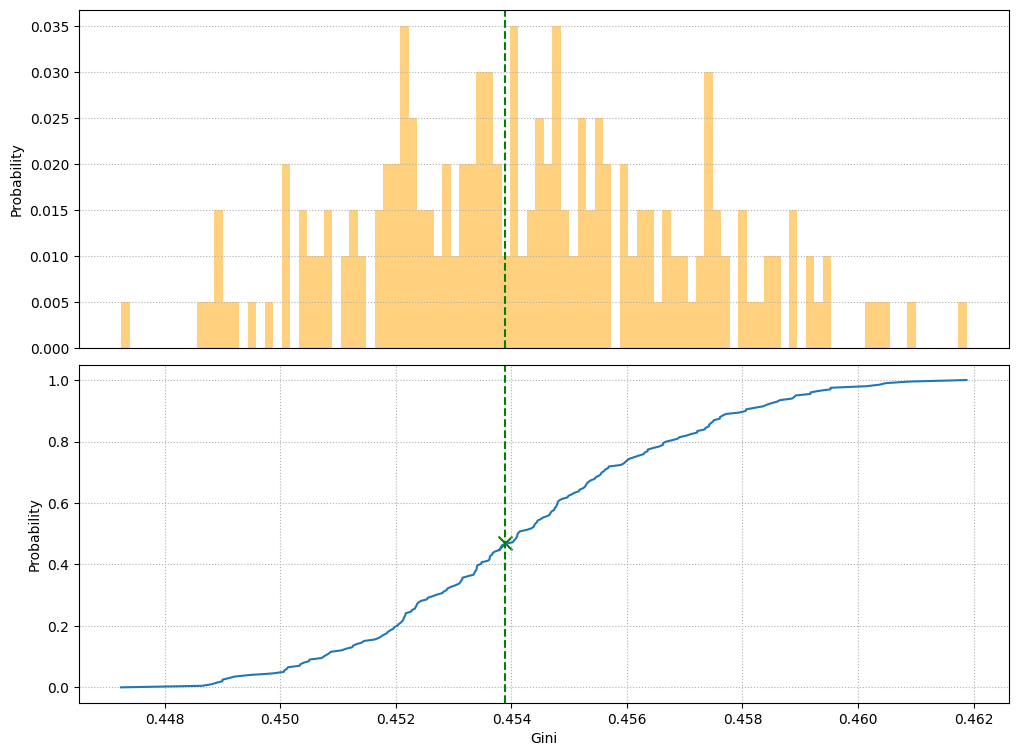

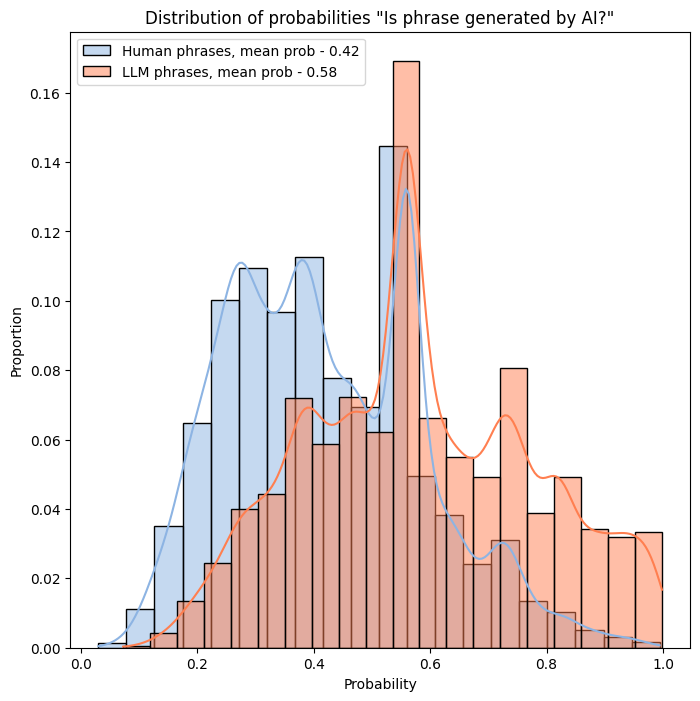

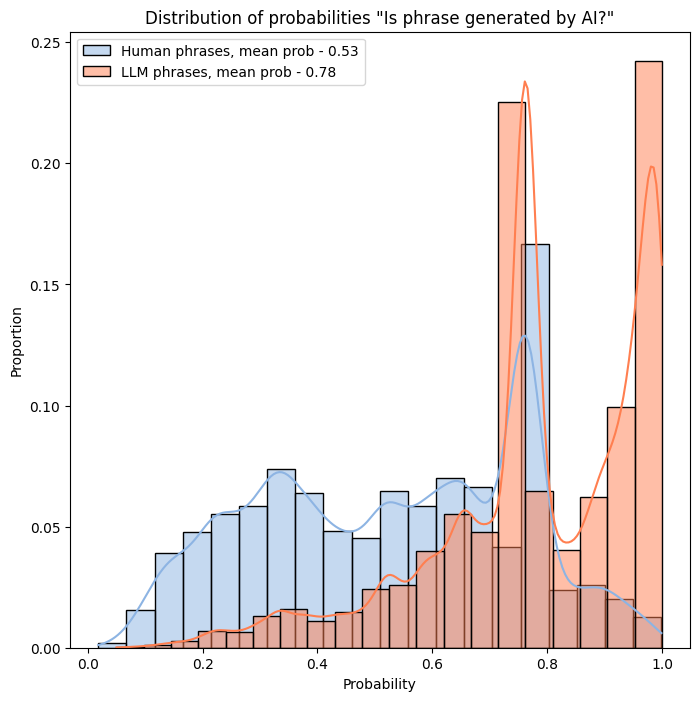

In [6]:
res = valtest_generated_recognition_analysis(sampler=sampler_dialogue,
                                             data_type='test',
                                             vectorizer_min_df=0.005,
                                             vectorizer_max_df=0.99,
                                             n_iter=200,
                                             seed=42,
                                             toloka_size=0.75,
                                             test_size=0.4,
                                             statistics=None)

In [8]:
display(res['report']['result_dataframes'][0])

,Проверка,Данные,Фактический gini,Квантиль
0,Распознавание сгенерированных текстов,LLM,0.453897,0.345
1,Сравнение диалога между человека с LLM и челов...,Toloka Persona Chat + LLM,0.617119,0.470
2,Сравнение фраз людей и LLM из RuATD,RuATD,0.458120,0.275


## Тест 6.2 Оценка связности диалога (Информативный тест)

In [6]:
from llm_val.val_test.specification_chat.valtest_text_coherence import valtest_text_coherence

В тесте вы можете использовать нужную вам модель для получения эмбеддингов, для которой нужно реализовать обёртку, у которой есть метод encode. Ниже представлен пример реализации обёртки:

In [7]:
import torch
import numpy as np
from transformers import AutoModel, AutoTokenizer

class SentenceEmbModel:
    '''
    Обёртка для модели получения эмбеддингов предложений
    '''
    @staticmethod
    def mean_pooling(model_output, 
                     attention_mask):
        token_embeddings = model_output[0] 
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)


    def __init__(self, 
                 model_path: str='sentence_transformers/paraphrase-multilingual-MiniLM-L12-v2',
                 device: str='cuda'):
        '''
        model_path: Путь к модели
        device: Устройство для вычислений: CUDA или CPU
        '''
        self.model = AutoModel.from_pretrained(model_path)
        self.tokenizer = AutoTokenizer.from_pretrained(model_path)
        self.device = device
        self.model.to(self.device)


    def encode(self, 
               sentences: tp.List[str]) -> np.array:
        encoded_input = self.tokenizer(sentences, padding=True, truncation=True, return_tensors='pt')
        with torch.no_grad():
            output = self.model(**encoded_input.to(self.device))
        sentence_embeddings = self.mean_pooling(output, encoded_input['attention_mask'])
        return sentence_embeddings.cpu().numpy()

In [12]:
model = SentenceEmbModel()

Подсчет эмбеддингов работает ***медленно***, поэтому можно предпосчитать эмбеддинги для датасета Toloka, сохранить их в датафрейме в поле ***'embeddings'***, сохранить датафрейм в pickle и передать в тест как параметр ```toloka_embeddings```. Пример того, как должны быть сохранены эмбеддинги:

In [8]:
pd.read_pickle('./data/toloka_embeddings_example.pkl')

,persona_1_profile,persona_2_profile,dialogue,parsed_dialogue,embeddings
0,<span class=participant_1>У меня любимая работ...,<span class=participant_2>Ищу принца.<br />Вед...,<span class=participant_2>Пользователь 2: Прив...,"[Привет расскажи о себе, Привет под вкусный ко...","[[0.36243403, 0.097491786, 0.060486924, 0.1581..."
1,<span class=participant_1>Я работаю учителем<b...,<span class=participant_2>Я бизнесмен<br />У м...,<span class=participant_1>Пользователь 1: Прив...,"[Привет, ПриветКак жизнь, Отлично Солнышко све...","[[0.14159161, 0.1650015, 0.18058893, 0.1014960..."
2,<span class=participant_1>Я купила дом<br />Я ...,<span class=participant_2>Я пою в караоке<br /...,<span class=participant_1>Пользователь 1: Прив...,"[Привет, Как дела , Добрый день, Хорошо чем у...","[[0.14159158, 0.1650015, 0.18058899, 0.1014960..."
3,<span class=participant_1>я врач и женат<br />...,<span class=participant_2>Я мальчик<br />Я учу...,<span class=participant_2>Пользователь 2: Здра...,"[Здравствуйте, Я Леша, Здравствуйте, Я Егор, Я...","[[0.18261881, 0.17128102, 0.22912194, 0.123748..."
4,<span class=participant_1>Я школьница.<br />Я ...,<span class=participant_2>Я простоват.<br />Лю...,<span class=participant_1>Пользователь 1: Прив...,"[Привет, Привет, Как твои дела, Нормально гото...","[[0.14159161, 0.1650015, 0.18058893, 0.1014960..."


Также можно использовать эмбеддинги, хранящиеся в сэмплере; для этого нужно в параметрах теста указать ```use_precomputed_emb=True```:

100%|██████████| 10013/10013 [01:37<00:00, 102.49it/s]


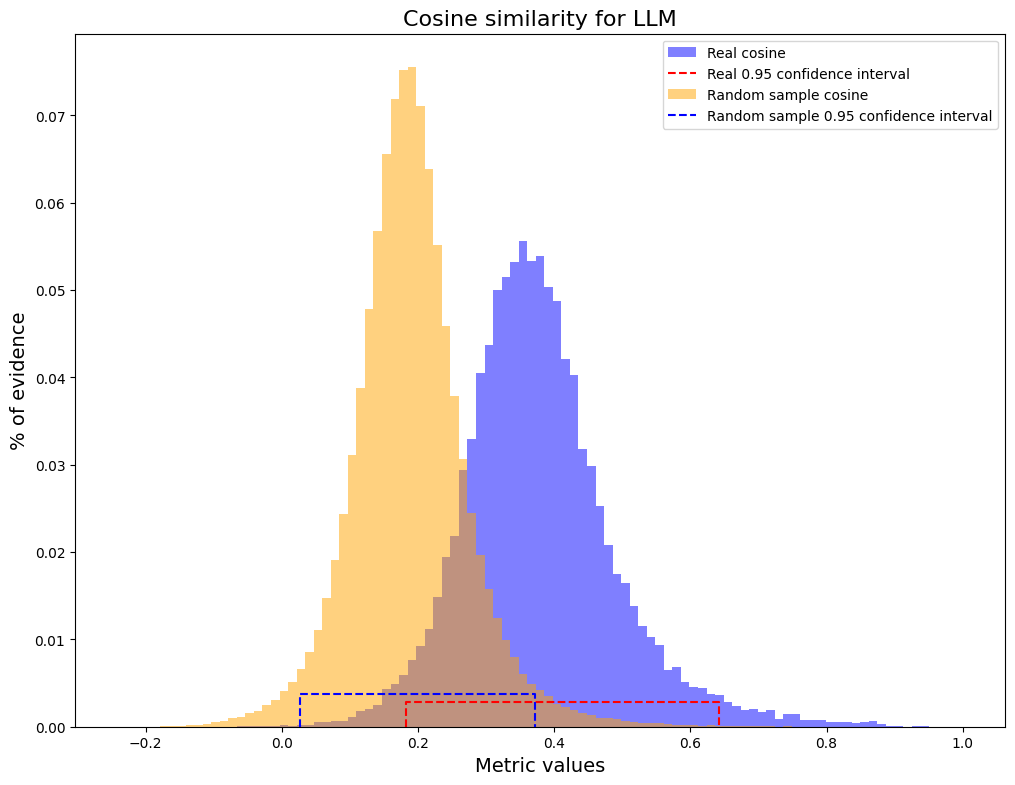

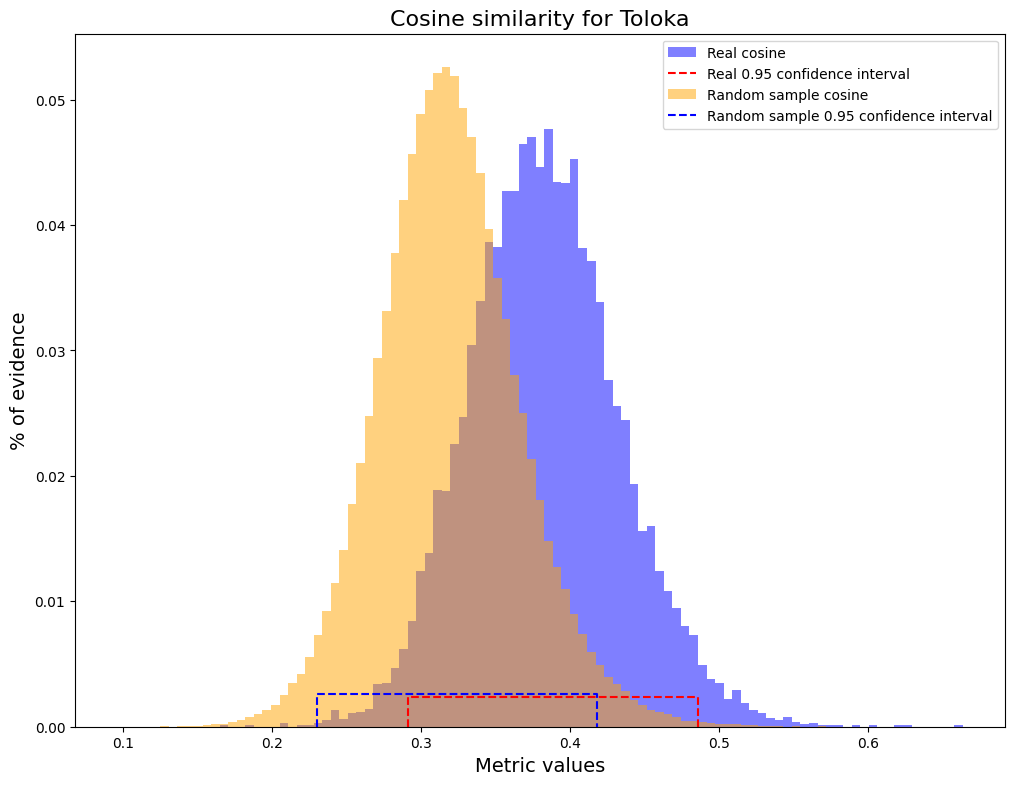

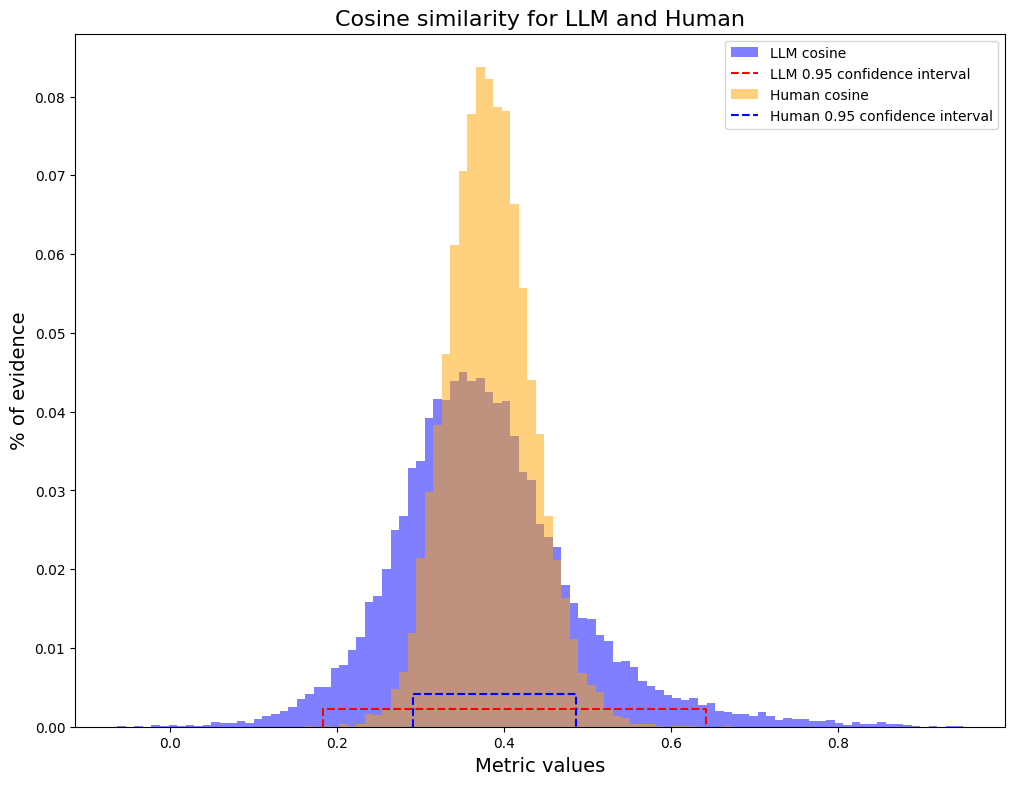

In [21]:
res = valtest_text_coherence(sampler=sampler_dialogue,
                             data_type='test',
                             quantile=0.95,
                             n_samples=25,
                             seed=42,
                             use_precomputed_emb=False,
                             model=model,
                             toloka_embeddings=None,
                             statistics=None)

In [22]:
display(res['report']['result_dataframes'][0])

,Наименование датасета,Среднее значение cosine sim,Доверительный интервал,Количество наблюдений (диалогов)
0,Диалоги человека с LLM,0.377940,"[-0.0632166862487793, 0.9492157697677612]",18477
1,Случайные фразы из диалогов человека с LLM,0.188964,"[-0.24152497947216034, 0.9999995231628418]",461925
2,Toloka Persona Chat Rus,0.383234,"[0.1676967740058899, 0.6638438701629639]",10013
3,Случайные фразы из Toloka,0.319319,"[0.09619859606027603, 0.6354198455810547]",250325


## 6.3 Оценка качества решения задачи NSP в диалоге (Информативный тест)

In [5]:
from llm_val.val_test.specification_chat.valtest_nsp_quality import valtest_nsp_quality

В тесте вы можете использовать нужную вам модель для получения эмбеддингов, для которой нужно реализовать обёртку, у которой есть метод encode. Ниже представлен пример реализации обёртки:

In [7]:
import torch
import numpy as np
from transformers import AutoModel, AutoTokenizer

class SentenceEmbModel:
    '''
    Обёртка для модели получения эмбеддингов предложений
    '''
    @staticmethod
    def mean_pooling(model_output, 
                     attention_mask):
        token_embeddings = model_output[0] 
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)


    def __init__(self, 
                 model_path: str='sentence_transformers/paraphrase-multilingual-MiniLM-L12-v2',
                 device: str='cuda'):
        '''
        model_path: Путь к модели
        device: Устройство для вычислений: CUDA или CPU
        '''
        self.model = AutoModel.from_pretrained(model_path)
        self.tokenizer = AutoTokenizer.from_pretrained(model_path)
        self.device = device
        self.model.to(self.device)


    def encode(self, 
               sentences: tp.List[str]) -> np.array:
        encoded_input = self.tokenizer(sentences, padding=True, truncation=True, return_tensors='pt')
        with torch.no_grad():
            output = self.model(**encoded_input.to(self.device))
        sentence_embeddings = self.mean_pooling(output, encoded_input['attention_mask'])
        return sentence_embeddings.cpu().numpy()

In [10]:
model = SentenceEmbModel()

100%|██████████| 10013/10013 [01:38<00:00, 101.39it/s]


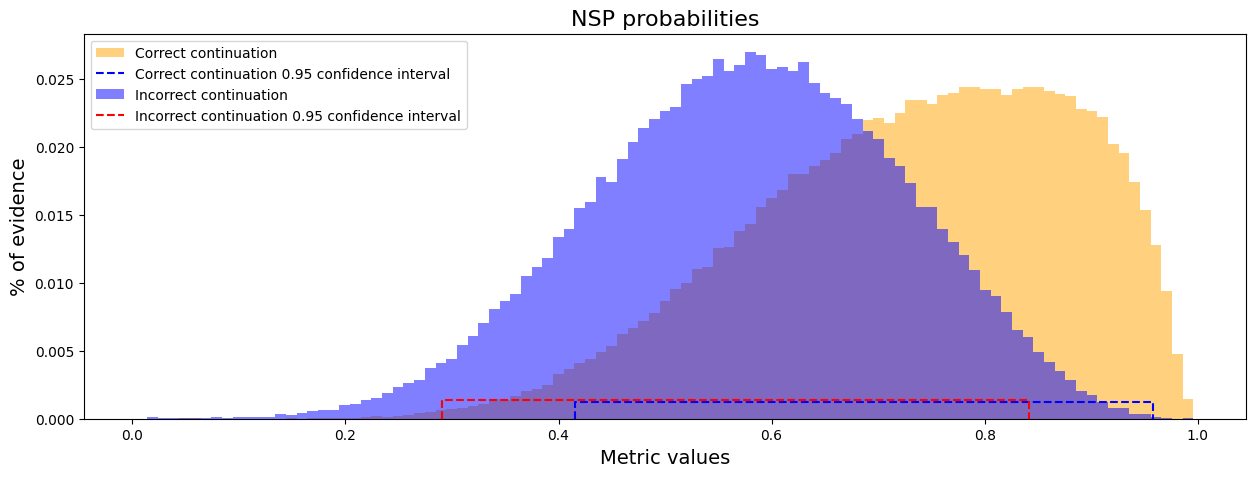

In [11]:
res = valtest_nsp_quality(sampler=sampler_dialogue,
                          data_type='test',
                          seed=42,
                          quantile=0.95,
                          use_precomputed_emb=False,
                          model=model,
                          toloka_emb=None,
                          statistics=None)

In [12]:
display(res['report']['result_dataframes'][0])

,Наименование класса,Среднее значение вероятности NSP,Доверительный интервал
0,Правильная следующая фраза,0.732172,[0.41588775041944925; 0.9581679105639843]
1,Неправильная следующая фраза,0.577237,[0.2904250818036292; 0.841968681766039]


## Тест 6.4 Оценка продолжительности самодиалога (Информативный тест)

In [4]:
from llm_val.val_test.specification_chat.valtest_length_self_chat import valtest_length_self_chat

На вход модели нужно подать системный промпт, в котором находится few-shot с тем, как нужно генерировать новые фразы. Для корректной работы теста фразы в диалоге должны начинаться символом ```'-'```, а заканчиваться символом переноса строки: ```'\n'```. Ниже представлен пример системного промпта:

In [5]:
SYS_PROMPT = '''Тебе на вход приходят фразы из диалога между двумя людьми. 
Тебе необходимо их продолжить ОДНОЙ фразой. Пример: -Привет, как дела?\n
'''

In [10]:
chat_model = MultiThreadGigaModel(n_jobs=8,
                                  rquid=RQUID,
                                  sys_promt=SYS_PROMPT,
                                  auth_data=AUTH_DATA,
                                  oauth_url=total_auth[contour]['OAUTH_URL'],
                                  api_url=total_auth[contour]['API_URL'],
                                  token=total_auth[contour]['TOKEN'])

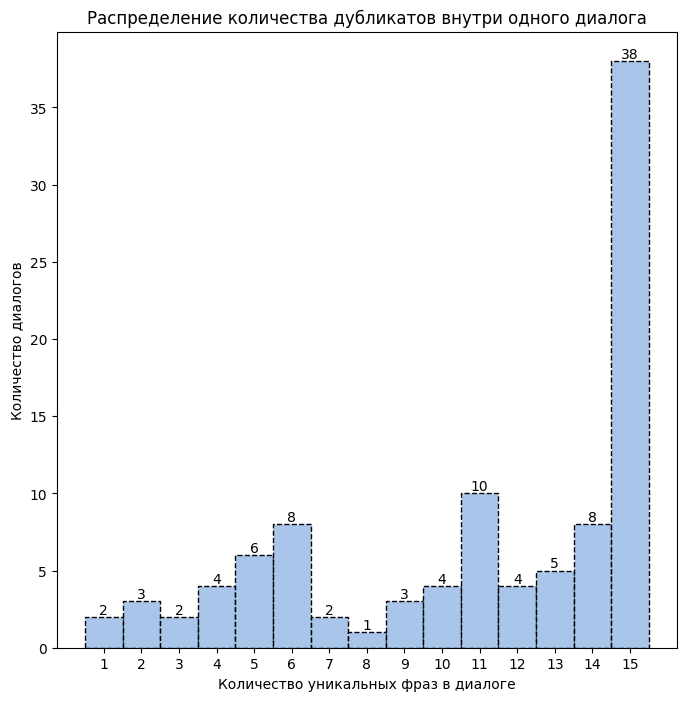

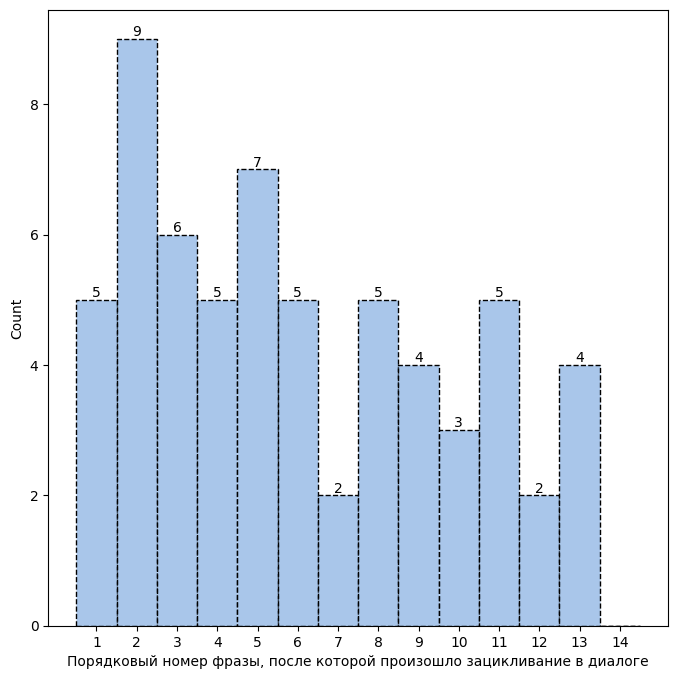

In [13]:
res = valtest_length_self_chat(model=chat_model,
                               generated_length=15,
                               context=3,
                               n_samples=100,
                               seed=42,
                               time_step=5,
                               computed=None)

In [14]:
display(res['report']['result_dataframes'][0])

,Общее количество диалогов,Диалоги с зацикливанием,Общее число фраз в диалогах,Средняя длина диалога,Среднее количество повторений
0,100,62,1800,14.02,3.98


## Тест 6.5 Оценка эмпатии LLM (Информативный тест)

In [8]:
from llm_val.val_test.specification_chat.valtest_empathy_assessment import valtest_empathy_assessment

In [9]:
import torch
from transformers import BertForSequenceClassification, AutoTokenizer

class DetectEmotionModelHugWrapper:
    def __init__(self,
                 tokenizer_name: str,
                 model_name: str,
                 tokenizer_config: tp.Dict[str, tp.Any],
                 model_config: tp.Dict[str, tp.Any],
                 labels: tp.List[str],
                 device: str='cpu'):
        self.tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)
        self.model = BertForSequenceClassification.from_pretrained(model_name, 
                                                                   **model_config)
        self.labels = labels
        self.device = device
        self.tokenizer_config = tokenizer_config
     
    def predict(self,
                sentences: tp.List[str]):
        tokenized_sentences = self.tokenizer(sentences,
                                             **self.tokenizer_config)
        with torch.no_grad():
            logits = self.model(**tokenized_sentences).logits
        indices = logits.argmax(axis=1).tolist()
        preds = list(map(lambda x: self.labels[x], indices))
        return preds
     
    def to_device(self):
        self.model.to(self.device)
        self.model.eval()
 
detect_emotion_model_config = {'num_labels': 6,
                               'problem_type': 'multi_label_classification'}
detect_emotion_tokenizer_config = {'padding': True,
                                   'return_tensors': 'pt'}
emotion_labels = ['no_emotion', 'joy', 'sadness', 'surprise', 'fear', 'anger']

emotion_model = 'cointegrated/rubert-tiny2-cedr-emotion-detection'
detect_emotion_model = DetectEmotionModelHugWrapper(emotion_model,
                                                    emotion_model,
                                                    detect_emotion_tokenizer_config,
                                                    detect_emotion_model_config,
                                                    emotion_labels)

/home/user/conda/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/user/conda/lib/python3.9/site-packages/huggingface_hub/file_download.py:795: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [15]:
res = valtest_empathy_assessment(sampler=sampler_dialogue_30,
                                 model=detect_emotion_model,
                                 labels=emotion_labels)

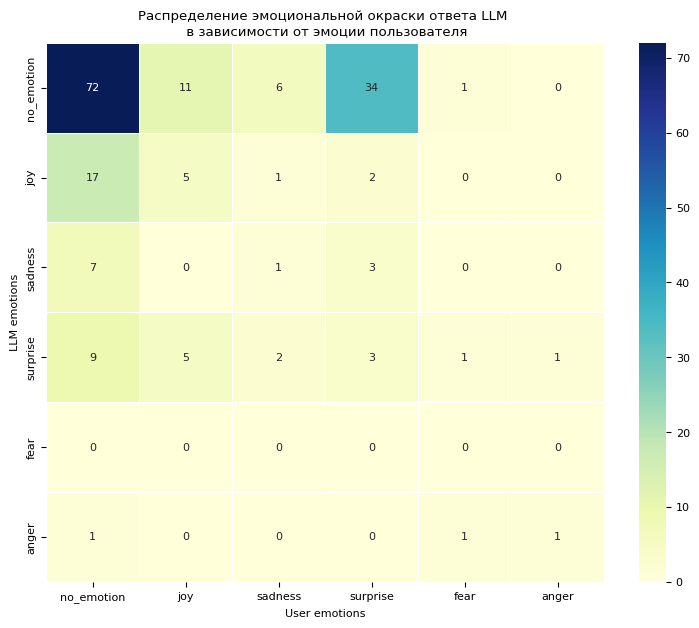

In [17]:
res['report']['result_plots'][0]

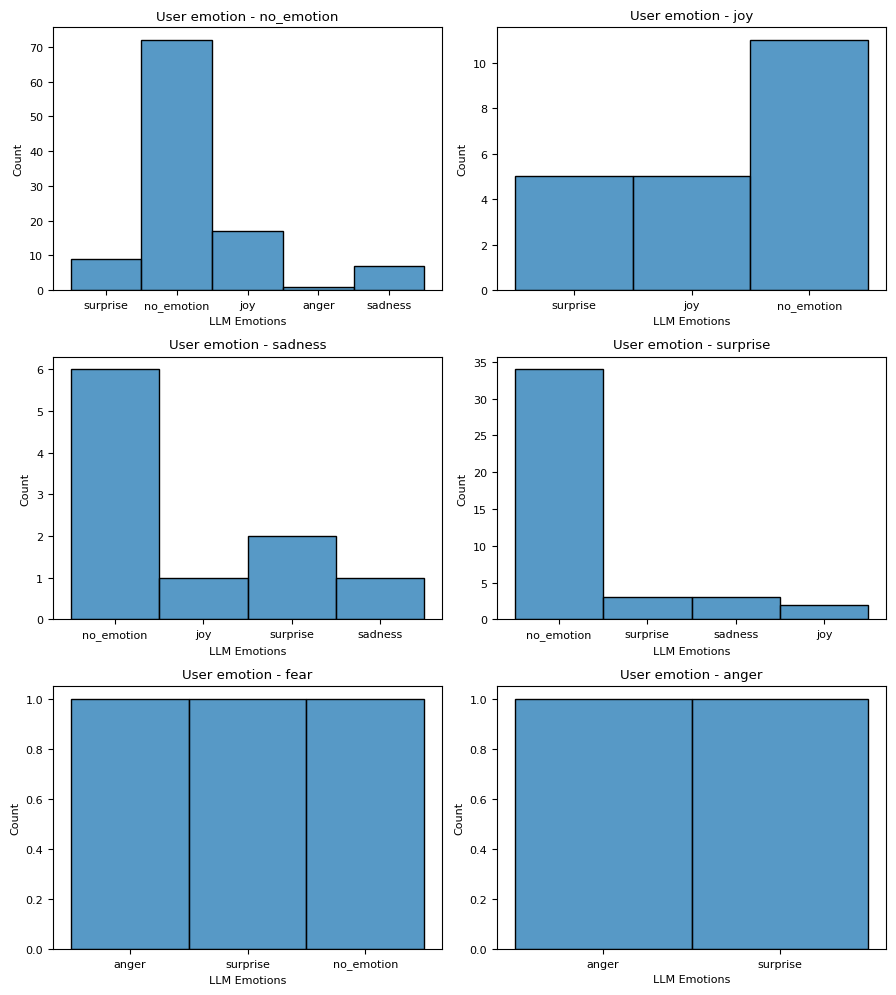

In [18]:
res['report']['result_plots'][1]

## Тест 6.6 Устойчивость модели к adversarial атакам (Информативный тест)

In [7]:
from llm_val.val_test.specification_chat.valtest_adversarial_stability import valtest_adversarial_stability

В тесте вы можете использовать необходимую вам модель перефразирования, для которой нужно реализовать обёртку, у котрой есть метод paraphrase. Ниже представлен пример обёртки:

In [8]:
from transformers import T5ForConditionalGeneration, T5Tokenizer

class Paraphraser:
    '''
    Обёртка для модели перефразирования
    '''
    def __init__(self, 
                 paraphraser_path: str,
                 paraphraser_param: tp.Dict[str, tp.Any], 
                 tokenizer_param: tp.Dict[str, tp.Any],
                 device: str='cuda'):
        '''
        paraphraser_path: Путь до модели
        paraphraser_param: Словарь с параметрами модели
        tokenizer_param: Словарь с параметрами токенизатора
        device: CPU или CUDA
        '''
        self.tokenizer = T5Tokenizer.from_pretrained(paraphraser_path)
        self.model = T5ForConditionalGeneration.from_pretrained(paraphraser_path)
        self.params = {'model': paraphraser_param,
                       'tokenizer': tokenizer_param}
        self.model.to(device)
        self.model.eval()

    
    def paraphrase(self, 
                   sentence: str) -> str:
        '''
        Функция для перефразирования
        Parameters:
            sentence: Предложение
        Return:
            Перефразированное предложение
        '''
        model_input = self.tokenizer(sentence, **self.params['tokenizer']).to(self.model.device)
        max_size = int(model_input.input_ids.shape[1] * 1.5 + 10)
        self.params['model']['max_length'] = max_size
        output = self.model.generate(**model_input, **self.params['model'])
        output_decoded = self.tokenizer.decode(output[0], skip_special_tokens=True)
        return output_decoded
    
paraphraser_params = {'num_beams': 10,
                        'encoder_no_repeat_ngram_size': 4,
                        'do_sample': True}
tokenizer_params = {'return_tensors': 'pt',
                    'padding': True}

paraphraser = Paraphraser(paraphraser_path='cointegrated/rut5-base-paraphraser',
                          paraphraser_param=paraphraser_params,
                          tokenizer_param=tokenizer_params)

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


Также для теста нужна модель, у которой должен быть отключен цензор:

In [10]:
model_opponent = BaseGigaModel(rquid=RQUID,
                               auth_data=AUTH_DATA,
                               oauth_url=total_auth[contour]['OAUTH_URL'],
                               api_url=total_auth[contour]['API_URL'],
                               token=total_auth[contour]['TOKEN'],
                               profanity_check=False)

In [11]:
model = BaseGigaModel(rquid=RQUID,
                      auth_data=AUTH_DATA,
                      oauth_url=total_auth[contour]['OAUTH_URL'],
                      api_url=total_auth[contour]['API_URL'],
                      token=total_auth[contour]['TOKEN'])

Для теста необходимо иметь список стоп фраз модели в pickle-файле. Пример:

In [12]:
stop_phrases = joblib.load('./data/stop_phrases_ex.pkl')
stop_phrases[:5]

['Извините, но ваш запрос не содержит понятного текста для обработки. Могу ли я чем-то помочь?',
 'Похоже, что вы случайно набрали случайный набор символов. Если у вас есть конкретный вопрос или тема для обсуждения, я с радостью помогу!',
 'Похоже, вы использовали транслит (перевод кириллицы на латиницу). Если у вас есть текст на русском языке, который вы хотите перевести на английский или наоборот, я могу помочь с этим. Также могу перевести его на другие языки, если нужно. Пожалуйста, предоставьте оригинальный текст.',
 'Похоже, что вы написали слово "шлёпать" задом наперёд. Попробуйте ещё раз!',
 'Похоже, вы ввели текст на незнакомом языке. Могу ли я чем-то помочь? Может быть, перевести этот текст на русский или английский язык?']

В тесте можно использовать различные аугментации текста, для этого нужно передать в ```augments``` список с нужными аугментациями. Ниже представлен пример списка с аугментациями:

In [13]:
from nlpaug.augmenter.char.random import RandomCharAug
from nlpaug.augmenter.char.keyboard import KeyboardAug

augments = [KeyboardAug(lang='ru', 
                        aug_char_p=0.2, 
                        aug_word_p=0.2, 
                        aug_char_max=2, 
                        aug_word_max=2),
            RandomCharAug(action='delete', 
                          aug_char_p=0.2, 
                          aug_word_p=0.2, 
                          aug_char_max=2, 
                          aug_word_max=2, 
                          name='RandomCharDelete_Aug'),
            RandomCharAug(action='swap', 
                          aug_char_p=0.2, 
                          aug_word_p=0.2, 
                          aug_char_max=2, 
                          aug_word_max=2, 
                          name='RandomCharSwap_Aug')]

In [19]:
res = valtest_adversarial_stability(sampler=sampler_dialogue,
                                    model=model,
                                    model_opponent=model_opponent,
                                    stop_phrases_path='./data/stop_phrases_ex.pkl',
                                    paraphraser=paraphraser,
                                    augments=augments,
                                    data_type='test',
                                    epsilon=0.3,
                                    gamma=0.99,
                                    bound=(1, 5),
                                    max_iter=5,
                                    threshold=0.08,
                                    seed=42,
                                    time_step=5,
                                    precomputed=None)

100%|██████████| 5/5 [03:12<00:00, 38.55s/it]


В качестве результата выводится DataFrame с возможными ошибками. В отчете о валидации необходимо привести ошибки их с количеством. Ошибки нужно искать вручную:

In [20]:
res['report']['result_dataframes'][0]

,Тип ошибки
0,Фактическая ошибка
1,Зацикливание
2,Повторение запроса пользователя
3,Повторяющиеся междометия в разных ответах
4,Повторение своего запроса
5,Непонимание
6,Неправомочный ответ
7,Опечатка
8,Тавтология
9,Синтаксическая ошибка


В precomputed находится словарь с ключами ```'1'```, ```'2'``` и ```'draw'```. По этим ключам можно получить свод статистик по диалогам, где был "выигрыш" валидируемой модели, модели-оппонента или ничья соответственно:

In [21]:
res['precomputed']['draw'][0][1]['states'][-1]

['какого цвета Огни Святого Эльма?',
 'Огни Святого Эльма (или огни Элдриджа) — это электрические разряды, которые могут возникать на остриях высоких объектов во время грозы или перед ней. Они часто ассоциируются с мистикой и легендами, так как считались знамением приближающейся бури.\n\nЧто касается их цвета, то обычно они имеют голубовато-фиолетовый оттенок. Этот цвет обусловлен процессами, происходящими при электрических разрядах в атмосфере.',
 'Огни Святого Эльма (или Эльмова искра) — это электрические разряды, которые могут возникать на остриях и краях предметов во время грозы или перед ней. Они часто ассоциируются с легендами и мифами о святых, включая Святого Эльма. Цвет этих огней может варьироваться от голубовато - фиолетового до сине - белого в зависимости от условий окружающей среды и состава воздуха. В основном они ииеют фркий голубой или фиолетовый оттенок.',
 'Огни Святого Эльма (или огни Элдриджа) — это электрические разряды, которые могут возникать на остриях высоких о

## Тест 6.7 Средняя длина диалога

In [5]:
from llm_val.val_test.specification_chat.valtest_dialogue_length import valtest_dialogue_length

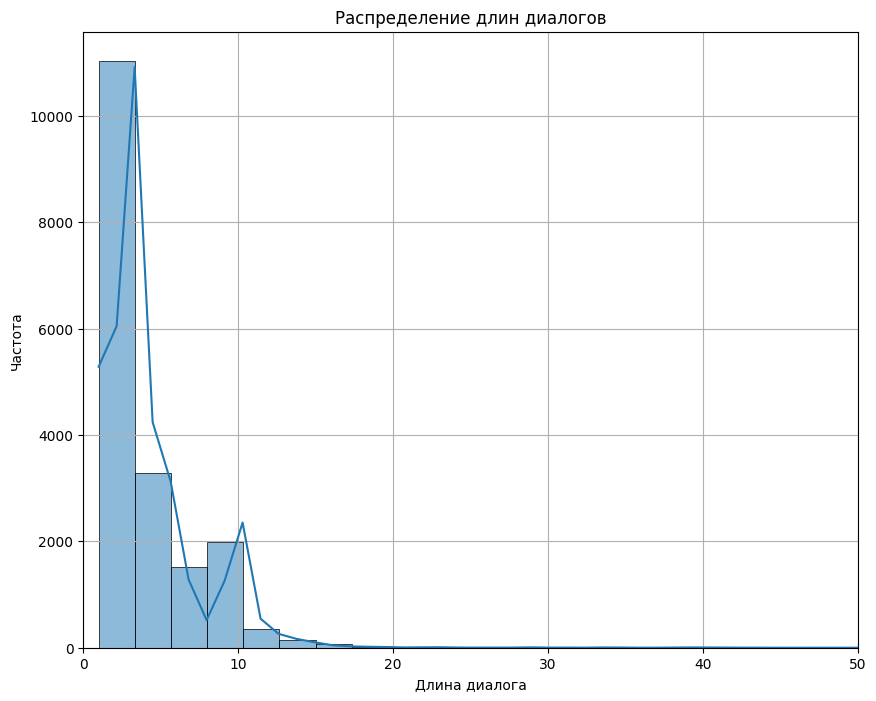

In [6]:
res = valtest_dialogue_length(sampler_dialogue,
                              data_type='test',
                              semaphore_threshold_converse=(3, 5),
                              semaphore_threshold_answer=(3, 5),
                              conversational=True,
                              is_info=False,
                              precomputed=None)

In [7]:
display(res['report']['result_dataframes'][0])

,Метрика,Значение,Результат теста
0,Средняя длина диалога,4.307463,yellow


# Раздел 7. Спецификация Extract

## Тест 7.1 «Иголка в стоге сена» (Информативный тест)
Для теста необходим вопрос и правильный ответ на него. в тесте используются данные типа LongAnswer. В примере датасета типа LongAnswer, который есть в библиотеке, нет правильных ответов в колонке `true_answer`, поэтому сейчас для тестирования запишем в колонку `true_answer` содержимое колонки `model_answer`.

In [ ]:
from copy import deepcopy
sampler_la_needle = deepcopy(sampler_la)
sampler_la_needle.test["X"]["true_answer"] = sampler_la_needle.test["X"]["model_answer"]

In [ ]:
from llm_val.val_test.specification_extract.valtest_needle_test import valtest_needle_test

Цель теста - определить, насколько хорошо LLM ищет ответ на вопрос в большом контексте (ищет "иголку" в стоге "сена"). \
В тесте рассчитывается метрика близости между реальным ответом и предсказанием модели в разрезе длин передаваемых контекстов и глубины, на которой расположена иголка относительно 100% контекста. \
Можно задать системный промпт для модели с инструкциями под этот тест, передав его в параметр теста `system`. Этот параметр перезапишет в тесте системный промпт валидируемой модели.\
Для расчета метрики по умолчанию используется метрика chrF (https://huggingface.co/spaces/evaluate-metric/chrf), которая равна нулю, если слов из true_answer вообще нет в ответе. \
Также можно использовать метрику ExactMatch, установив параметр `test_scorer='EM'`, или прописать свой класс с методом evaluate_response, принимающим response и reference на вход и передать его как параметр `test_scorer`. \
Здесь response - ответ модели, reference - правильный ответ на вопрос. 

Примеры реализации классов для параметра `test_scorer` можно посмотреть в директории src/llm_val/val_test/src/llm_val/utils/extract_evaluators .\
В качестве "сена" в тесте используется российская литература (https://www.kaggle.com/datasets/d0rj3228/russian-literature). Эти тексты находятся в директории src/llm_val/resources/haystack_for_detecthaystack_for_detect .\
Также можно использовать свои контексты в качестве "сена", передав в параметр `haystack_dir` директорию с текстами "сена". Самое главное условие: "сено" (контексты) не должны быть по смыслу связаны с "иголкой" (вопросом). 

Test 7.1: NIH: 100%|██████████| 5/5 [01:34<00:00, 19.00s/it]


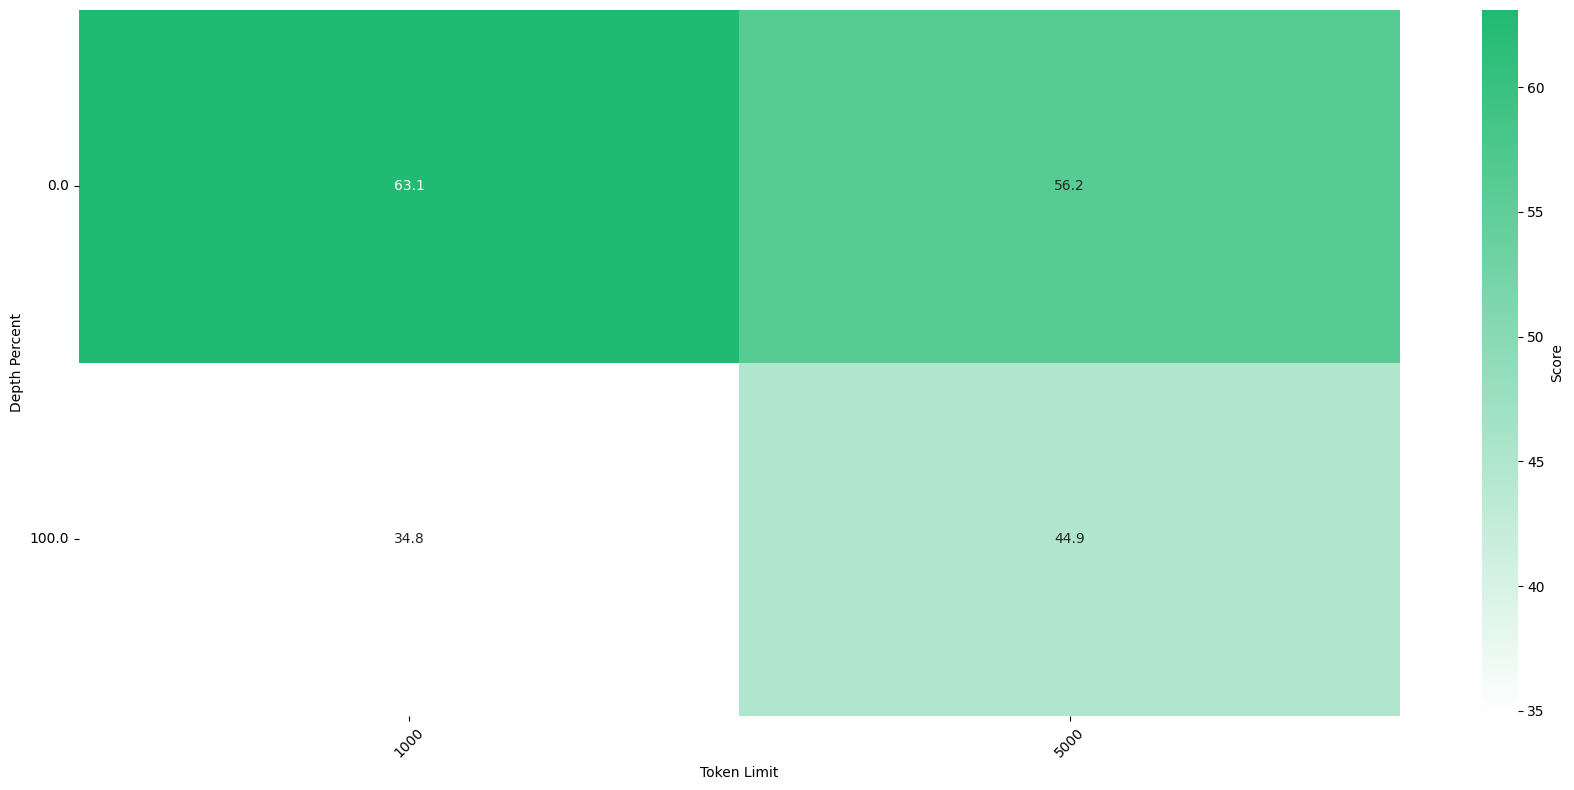

In [17]:
system = 'Ты — полезный ИИ бот, который отвечает на вопросы пользователя. Отвечай кратко и по теме. Не выдавай информацию за пределами документа и не повторяй свои выводы.'
res = valtest_needle_test(sampler=sampler_la_needle,
                          model=model,
                          data_type='test',
                          context_lengths_max=5000,
                          depth_greed=2,
                          lens_greed=2,
                          system=system,
                          print_ongoing_status=False)

In [19]:
res['report']['result_dataframes'][0]

Context Length,1000,5000
Document Depth,,
0.0,63.096696,56.154869
100.0,34.792926,44.941565


# Раздел 8. Спецификация Brainstorm

## Тест 8.1. Оценка качества генерации идей (brainstorm) с помощью автоматической метрики (Информативный тест)

In [2]:
from llm_val.utils.Embedder.E5Embedder import E5Embedder as e5e
from llm_val.utils.TokenizerWrapper import TokenizerWrapper as towr
from llm_val.sampler.BrainStormSampler import BrainStormSampler as bss
from llm_val.utils.Embedder.SBERTEmbedder import SBERTEmbedder as sberte
from llm_val.val_test.brainstorm.valtest_brainstorm_quality import valtest_brainstorm_quality

In [3]:
e5_path = '/home/datalab/nfs/models/multilingual_e5_large'
sbert_path = '/home/datalab/nfs/models/sbert_large_mt_nlu_ru'

# Подробное описание конфигов приведено в data/brainstorm/info.md

global_config_path ='data/brainstorm/configs/global_config.json'
task_config_path = 'data/brainstorm/configs/demo_task_config.json'

In [4]:
e5_encode = {
    'max_length': 512,
    'padding': True,
    'truncation': True,
    'return_tensors': 'pt'
}

sbert_encode = {
    'padding': True,
    'truncation': True,
    'max_length': 512,
    'return_tensors': 'pt'
}

__Загрузка данных через json__

In [5]:
bss_ = bss(global_config_path=global_config_path,
           json_path='data/brainstorm/datasets/demo_full_ds.json')

e5e_ = e5e(e5_path, e5_encode)
sberte_ = sberte(sbert_path, sbert_encode)

towr_e5 = towr(e5_path)
towr_sbert = towr(sbert_path)
input_models = {'e5': {'model': e5e_,
                       'tokenizer': towr_e5},
                'sbert': {'model': sberte_,
                          'tokenizer': towr_sbert}}

Для ограничения размера вывода итогов теста необходимо поднять флаг _get_top_k_ и задать параметр _top_k_,<br> обозначающий количество лучших пайплайнов, которые будут включены в отчет

In [8]:
brainstorm_quality = valtest_brainstorm_quality(bss_,
                                                global_config_path,
                                                task_config_path,
                                                model_storage=input_models,
                                                sort_table=True,
                                                get_top_k=True,
                                                top_k=10)

__10 лучших пайплайнов__

In [9]:
brainstorm_quality['report']['result_dataframes']

,index,abs_error_median,abs_error_mean,embedder_name,task_idea_sim,idea_idea_sim,is_text_cleaned,emb_norm_used,use_lemmatization,status
0,47,0.243435,0.284135,sbert,cos_sim,peak_distance_idea_idea,True,False,False,OK
1,46,0.271601,0.301580,sbert,dot_sim,peak_distance_idea_idea,True,False,False,OK
2,33,0.290935,0.322396,sbert,cos_sim,peak_distance_idea_idea,False,False,False,OK
3,53,0.285909,0.322819,sbert,inverted_craft_sim_task_idea,peak_distance_idea_idea,True,False,False,OK
4,54,0.284252,0.324536,sbert,inverted_craft_sim_task_idea,craft_sim_idea_idea,True,False,False,OK
5,15,0.257009,0.326995,e5,cos_sim,craft_sim_idea_idea,False,False,False,OK
6,50,0.283441,0.328361,sbert,craft_sim_task_idea,peak_distance_idea_idea,True,False,False,OK
7,1,0.294614,0.328441,e5,cos_sim,craft_sim_idea_idea,True,False,False,OK
8,32,0.285545,0.333425,sbert,dot_sim,peak_distance_idea_idea,False,False,False,OK
9,51,0.290398,0.334622,sbert,cos_sim,cos_sim,True,False,False,OK


__Распределение брейнштормов для top-1 пайплайна__ 

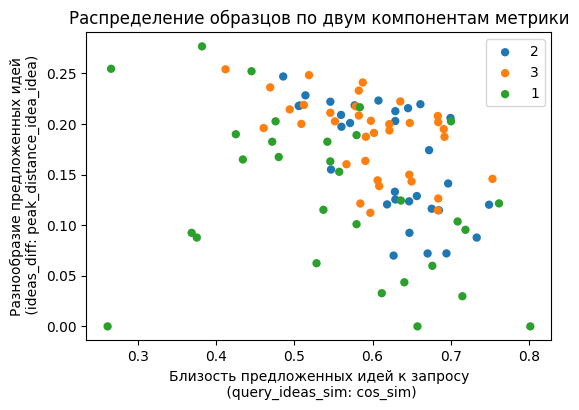

In [11]:
brainstorm_quality['report']['result_plots'][0][0]

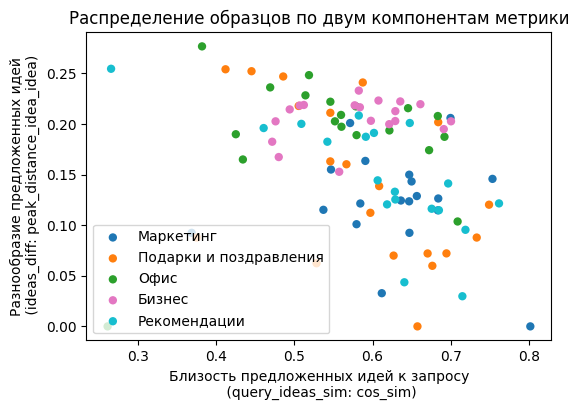

In [12]:
brainstorm_quality['report']['result_plots'][0][1]

__Загрузка данных через словарь__

In [13]:
dict_data_config = 'data/brainstorm/configs/demo_task_config.json'
data_df = pd.read_json('data/brainstorm/datasets/demo_full_ds.json')
formatted_dict = data_df.to_dict(orient='list') 

test = {'X': dict(), 'y': dict()}
test['X']['task'] = formatted_dict['task']
test['X']['ideas'] = formatted_dict['ideas']
test['X']['score'] = formatted_dict['score']
test['X']['theme'] = formatted_dict['theme']

In [14]:
bss_ = bss(global_config_path=global_config_path,
           test=test)

In [15]:
e5e_ = e5e(e5_path, e5_encode)
sberte_ = sberte(sbert_path, sbert_encode)

towr_e5 = towr(e5_path)
towr_sbert = towr(sbert_path)

input_models = {'e5': {'model': e5e_,
                       'tokenizer': towr_e5},
                'sbert': {'model': sberte_,
                          'tokenizer': towr_sbert}}

In [16]:
brainstorm_quality = valtest_brainstorm_quality(bss_,
                                                global_config_path,
                                                task_config_path,
                                                model_storage=input_models,
                                                sort_table=True,
                                                get_top_k=True,
                                                top_k=10)

In [17]:
brainstorm_quality['report']['result_dataframes']

,index,abs_error_median,abs_error_mean,embedder_name,task_idea_sim,idea_idea_sim,is_text_cleaned,emb_norm_used,use_lemmatization,status
0,47,0.243435,0.284135,sbert,cos_sim,peak_distance_idea_idea,True,False,False,OK
1,46,0.271601,0.301580,sbert,dot_sim,peak_distance_idea_idea,True,False,False,OK
2,33,0.290935,0.322396,sbert,cos_sim,peak_distance_idea_idea,False,False,False,OK
3,53,0.285909,0.322819,sbert,inverted_craft_sim_task_idea,peak_distance_idea_idea,True,False,False,OK
4,54,0.284252,0.324536,sbert,inverted_craft_sim_task_idea,craft_sim_idea_idea,True,False,False,OK
5,15,0.257009,0.326995,e5,cos_sim,craft_sim_idea_idea,False,False,False,OK
6,50,0.283441,0.328361,sbert,craft_sim_task_idea,peak_distance_idea_idea,True,False,False,OK
7,1,0.294614,0.328441,e5,cos_sim,craft_sim_idea_idea,True,False,False,OK
8,32,0.285545,0.333425,sbert,dot_sim,peak_distance_idea_idea,False,False,False,OK
9,51,0.290398,0.334622,sbert,cos_sim,cos_sim,True,False,False,OK


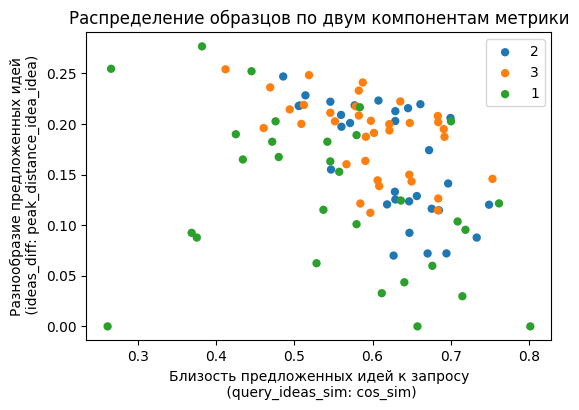

In [18]:
brainstorm_quality['report']['result_plots'][0][0]

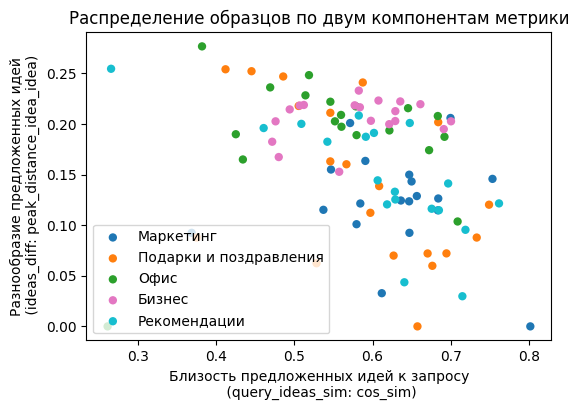

In [19]:
brainstorm_quality['report']['result_plots'][0][1]

## Тест 8.2. Оценка стабильности качества генерации идей (brainstorm) в зависимости от их требуемого количества (информативный тест)

### Инициализируем эмбеддеры


In [3]:
from llm_val.utils.Embedder.E5Embedder import E5Embedder
from llm_val.utils.TokenizerWrapper import TokenizerWrapper
from llm_val.utils.Embedder.SBERTEmbedder import SBERTEmbedder

e5_path = '/home/datalab/nfs/models/multilingual_e5_large'
sbert_path = '/home/datalab/nfs/models/sbert_large_mt_nlu_ru_'

e5_encode_params = {
    'max_length': 512,
    'padding': True,
    'truncation': True,
    'return_tensors': 'pt',
}

sbert_encode_params = {
    'padding': True,
    'truncation': True,
    'max_length': 512,
    'return_tensors': 'pt',
}

model_storage = {
    'e5': {
        'model': E5Embedder(e5_path, e5_encode_params),
        'tokenizer': TokenizerWrapper(e5_path),
    },
    'sbert': {
        'model': SBERTEmbedder(sbert_path, sbert_encode_params),
        'tokenizer': TokenizerWrapper(sbert_path),
    },
}

### Подгружаем датасет из .json'a, разделяем на обучающую и тестовую выборки, подаем их в сэмплер.


Обучающая выборка используется сугубо для калибровки пороговых значений для биннинга значений мер близости и построения дискретных отображений в синтетическую асессорскую оценку.



In [4]:
from llm_val.sampler.BrainStormSampler import BrainStormSamplerUpgraded

data_df = pd.read_json('../examples/data/brainstorm/datasets/ds_quality_stability_by_n_ideas.json')
shuffled_df = data_df.sample(frac=1, random_state=42)
train_prop = 0.6
train_df = shuffled_df[:int(train_prop * len(shuffled_df))]
test_df = shuffled_df[int(train_prop * len(shuffled_df)):]

bs_sampler = BrainStormSamplerUpgraded(train=train_df, test=test_df)

Указываем путь к конфигурационному файлу для запуска.

Сам конфигурационный файл представляет из себя `.json`, имеющий структуру словаря со следующими ключами:

- `runs` - список заданий, выполняемых в рамках запуска. Каждое задание - это словарь, содержащий следующую информацию:
  - `embedder` - словарь со значениями:
    - `name` - строка с наименованием эмбеддера, выступающим ключом в `model_storage`
    - `use_text_cleaner` - строка, использующаяся как флаг для очистки текста от стоп-слов и символов пунктуации (активируется только при `True`)
    - `normalize` - строка, использующаяся как флаг для нормализации эмбеддингов (активируется только при `True`)
    - `use_lemmatization` - строка, использующаяся как флаг для активации лемматизации слов в предобработке (активируется только при `True`)
  - `distances` - список из строк со названиями мер близости (на текущий момент реализованы `cosine` и `euclidean`)
- `stopwords_path` - строка, содержащая путь до стоп-слов
- `seed` - целочисленное значение сида для генератора случайных чисел

In [5]:
task_config_path = '../examples/data/brainstorm/configs/cfg_quality_stability_by_n_ideas.json'

In [6]:
from llm_val.val_test.brainstorm.valtest_bstorm_best_ideas_nb import valtest_bstorm_best_ideas_nb

bs_quality_per_idea_results = valtest_bstorm_best_ideas_nb(sampler=bs_sampler,
                                                           task_config_path=task_config_path,
                                                           model_storage=model_storage,
                                                           max_ideas=6,
                                                           nb_of_scores=3,
                                                           seed=42)

100%|██████████| 39/39 [00:08<00:00,  4.50it/s]


In [7]:
bs_quality_per_idea_results['report']['result_dataframes'][0]

1 idea(s)  2 idea(s)  \
run_setup               distance  metric                                 
e5 cleaned              cosine    distance-based   0.933414   0.979503   
                                  discrete score   2.000000   2.743590   
                        euclidean distance-based   0.743707   0.889628   
                                  discrete score   2.000000   2.692308   
weighted manual mean gt -         discrete score   1.102564   1.500000   

                                                  3 idea(s)  4 idea(s)  \
run_setup               distance  metric                                 
e5 cleaned              cosine    distance-based   1.017847   1.053863   
                                  discrete score   3.256410   3.724359   
                        euclidean distance-based   1.022671   1.147758   
                                  discrete score   3.213675   3.724359   
weighted manual mean gt -         discrete score   1.829060   2.019231   

                                                  5 idea(s)  6 idea(s)  
run_setup               distance  metric                                
e5 cleaned              cosine    distance-based   1.089228   1.119783  
                                  discrete score   4.312821   4.717949  
                        euclidean distance-based   1.270663   1.374644  
                                  discrete score   4.194872   4.547009  
weighted manual mean gt -         discrete score   2.338462   2.649573

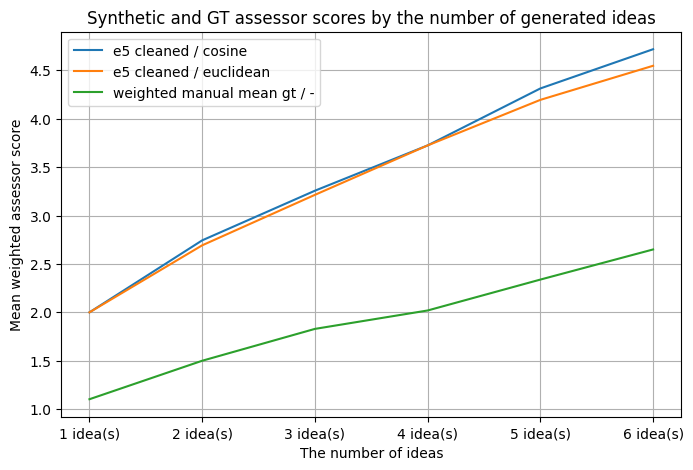

In [8]:
bs_quality_per_idea_results['report']['result_plots'][0][0]


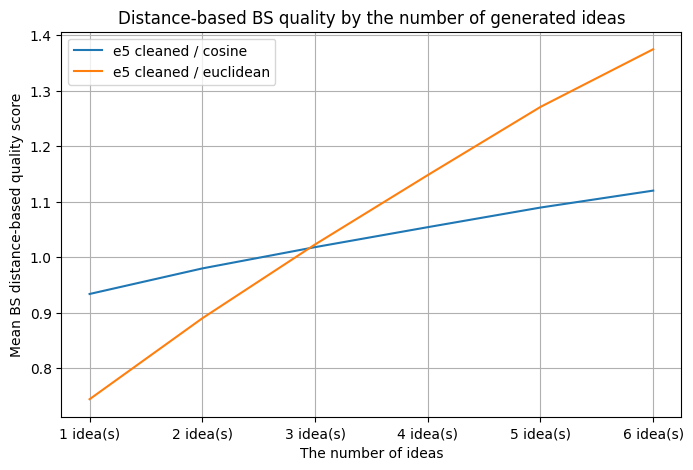

In [9]:
bs_quality_per_idea_results['report']['result_plots'][0][1]

# Раздел 9. Спецификация Rewrite

## Тест 9.1. Оценка баланса между сохранением смысла исходного текста и степенью его перефразированности (информативный тест)

In [12]:
embedding_model = GigaChatAPI(contour=None,
                              rquid=RQUID,
                              auth_data=AUTH_DATA,
                              oauth_url=total_auth[contour]['OAUTH_URL'],
                              api_url=total_auth[contour]['API_URL'],
                              token=total_auth[contour]['TOKEN'])

In [46]:
from llm_val.val_test.specification_rewrite.valtest_autoeval_rewriting_quality import valtest_autoeval_rewriting_quality

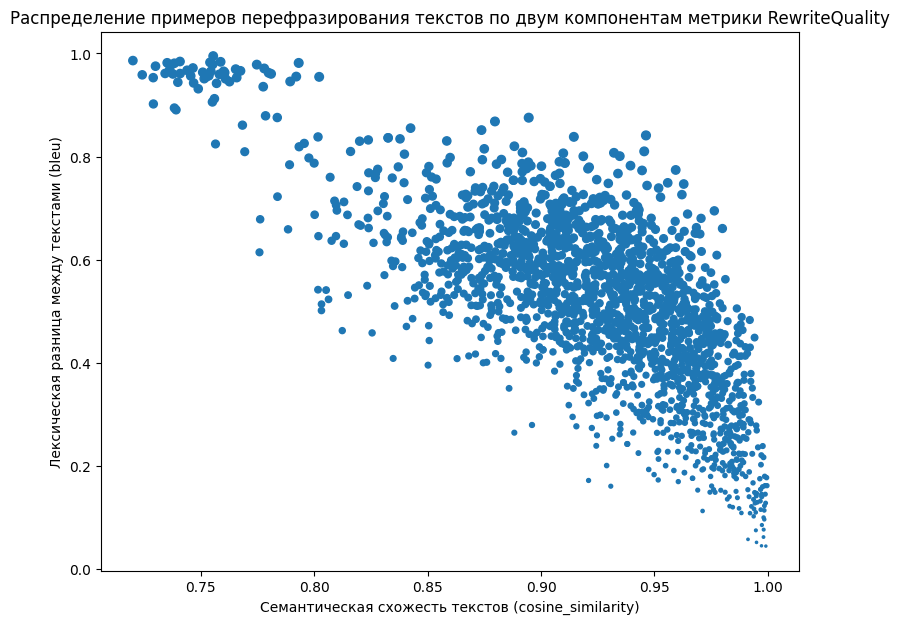

In [47]:
res = valtest_autoeval_rewriting_quality(sampler=sampler_paraphrase,
                                         embedding_model=embedding_model,
                                         semantic_sim_func='cosine_similarity',
                                         lexical_diff_func='bleu',
                                         data_type='test')

In [44]:
display(res['report']['result_dataframes'][0])

,Семантическая близость,Лексическая разница,Качество перефразирования
0,0.030473,0.836066,0.025477
1,0.502819,0.724638,0.364362
2,0.449993,0.792453,0.356598
3,0.439279,0.833333,0.366065
4,0.087709,0.852941,0.074811
...,...,...,...
1919,0.707262,0.857143,0.606225
1920,0.691956,0.342857,0.237242
1921,0.411393,0.606061,0.249329
1922,0.347497,0.865672,0.300818


## Тест 9.2. Ключевая метрика качества при решении обратной задачи

In [24]:
embedding_model = GigaChatAPI(contour=None,
                              rquid=RQUID,
                              auth_data=AUTH_DATA,
                              oauth_url=total_auth[contour]['OAUTH_URL'],
                              api_url=total_auth[contour]['API_URL'],
                              token=total_auth[contour]['TOKEN'])

#### Ниже представлены промпты для решения прямой и обратной задач на примере перевода с одного языка на другой
К этим промптам предъявляются следующие требования:
 * Они должны содержать инструкцию того, как следует переписывать текст при решении прямой/обратной задачи;
 * Они должны обязательно содержать подстроку '{source_text}', в которую впоследствии (при запуске теста) будут подставлены тексты для переписывания.

In [25]:
forward_problem_prompt = '''
Тебе будет дан текст на языке хинди. Тебе необходимо перевести его на русский язык. Не пиши ничего, кроме переведённого текста.
Текст на хинди: {source_text}
'''

In [26]:
reverse_problem_prompt = '''
Тебе будет дан текст на русском языке. Тебе необходимо перевести его на хинди. Не пиши ничего, кроме переведённого текста.
Текст на русском: {source_text}
'''

In [27]:
from llm_val.val_test.specification_rewrite.valtest_metric_reverse_problem import valtest_metric_reverse_problem

In [28]:
res = valtest_metric_reverse_problem(sampler=sampler_rewrite,
                                     model=model,
                                     main_metric=None,
                                     use_cosine_similarity=True,
                                     embedding_model=embedding_model,
                                     data_type='test',
                                     semaphore_threshold=(40, 60),
                                     greater_is_better=True,
                                     forward_problem_system_prompt=forward_problem_prompt,
                                     reverse_problem_system_prompt=reverse_problem_prompt,
                                     is_info=False)

In [29]:
display(res['report']['result_dataframes'][0])

,Метрика,Значение ключевой метрики при решении прямой задачи,Значение ключевой метрики при решении обратной задачи,"Относительное изменение метрики, %",Результат теста
0,cosine_similarity,0.947047,0.908719,4.047096,green


# Раздел 10. Стабильность

## Тест 10.1. Стабильность прогноза модели в зависимости от аугментаций на уровне символов

In [17]:
from llm_val.val_test.stability.valtest_metric_aug_stability import valtest_metric_aug_stability

In [12]:
res = valtest_metric_aug_stability(sampler=sampler_mmlu,
                                   scorer=scorer,
                                   model=model,
                                   p_augmented=0.1,
                                   augmentations_list=['symbol_swap',
                                                       'butter_finger',
                                                       'human_level_augmentations'])

In [13]:
display(res['report']['result_dataframes'][0])

,Исходное значение на test,Тип преобразования,Значение single_mean,"Абсолютное изменение, % single_mean","Относительное изменение, % single_mean",Результат теста
0,0.4,symbol_swap,0.4,0.0,0.0,green
1,0.4,butter_finger,0.4,0.0,0.0,green
2,0.4,human_level_augmentations,0.4,0.0,0.0,green
3,0.4,Итог,-,-,-,green


## Тест 10.2. Стабильность прогноза модели в зависимости от аугментаций на уровне слов

In [11]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

class ParaphraseModelHugWrapper:
    def __init__(self,
                 model_name: str,
                 device: str='cpu'):
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
        self.device = device
     
    def generate(self,
                 batch: tp.Any,
                 config: tp.Dict[str, tp.Any]):
        return self.model.generate(**batch, **config)
     
    def to_device(self):
        self.model.to(self.device)
        self.model.eval()


class ParaphraseTokenizerHugWrapper:
    def __init__(self,
                 model_name: str,
                 device: str='cpu'):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=False)
        self.device = device
     
    def decode(self,
               batch: tp.Any,
               config: tp.Dict[str, tp.Any]):
        return self.tokenizer.decode(batch.cpu().tolist(), **config)
                                                                                 
    def encode(self,
               batch: tp.List[str],
               config: tp.Dict[str, tp.Any]):
        return self.tokenizer(batch, **config)

 
paraphrase_model_config = {'num_beams': 1,
                           'encoder_no_repeat_ngram_size': 3,
                           'do_sample': False}

paraphrase_tokenizer_config = {'decode_config': {'skip_special_tokens': True},
                               'encode_config': {'padding': True,
                                                 'return_tensors': 'pt'}}

paraphrase_model = ParaphraseModelHugWrapper('cointegrated/rut5-base-paraphraser')
paraphrase_tokenizer = ParaphraseTokenizerHugWrapper('cointegrated/rut5-base-paraphraser')

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


In [14]:
res = valtest_metric_aug_stability(sampler=sampler_mmlu,
                                   scorer=scorer,
                                   model=model,
                                   p_augmented=0.1,
                                   paraphrase_model=paraphrase_model,
                                   paraphrase_model_config=paraphrase_model_config,
                                   paraphrase_tokenizer=paraphrase_tokenizer,
                                   paraphrase_tokenizer_config=paraphrase_tokenizer_config,
                                   augmentations_list=['word_swap', 
                                                       'paraphrase'])

100%|██████████| 1/1 [00:16<00:00, 16.42s/it]


In [15]:
display(res['report']['result_dataframes'][0])

,Исходное значение на test,Тип преобразования,Значение single_mean,"Абсолютное изменение, % single_mean","Относительное изменение, % single_mean",Результат теста
0,0.4,word_swap,0.4,0.0,0.0,green
1,0.4,paraphrase,0.6,-0.2,-50.0,green
2,0.4,Итог,-,-,-,green


Иногда в бизнес процессе может использоваться ASR перед передачей текста в модель. При этом переданные данные могут быть чистыми, не пропущенными через ASR. В таком случае может быть полезно использовать ASR-аугментации, которые можно использовать с этим тестом, добавив в список augmentations_list 'asr_augmentations'. ASR-аугментации в данном случае включают в себя нормализацию слов, удаление случайных коротких слов, изменение пунктуации исходного текста.

In [36]:
res = valtest_metric_aug_stability(sampler=sampler_mmlu,
                                   scorer=scorer,
                                   model=model,
                                   main_metric='single_mean_metric_value',
                                   p_augmented=0.1,
                                   augmentations_list=['asr_augmentations'])

In [37]:
display(res['report']['result_dataframes'][0])

,Исходное значение на test,Тип преобразования,Значение single_mean_metric_value,Абсолютное изменение single_mean_metric_value,"Относительное изменение, % single_mean_metric_value",Результат теста
0,0.4,asr_augmentations,0.4,0.0,0.0,green
1,0.4,Итог,-,-,-,green


## Тест 10.3 Анализ динамики ключевой метрики качества при перемешивании вариантов ответов

In [65]:
data_mmlu_long = joblib.load('data/data_mmlu_long.pkl')[:30]

In [66]:
sampler_mmlu_long = MMLUSampler(data_mmlu_long)

In [67]:
from llm_val.val_test.stability.valtest_mix_answers_stability import valtest_mix_answers_stability

### MMLU

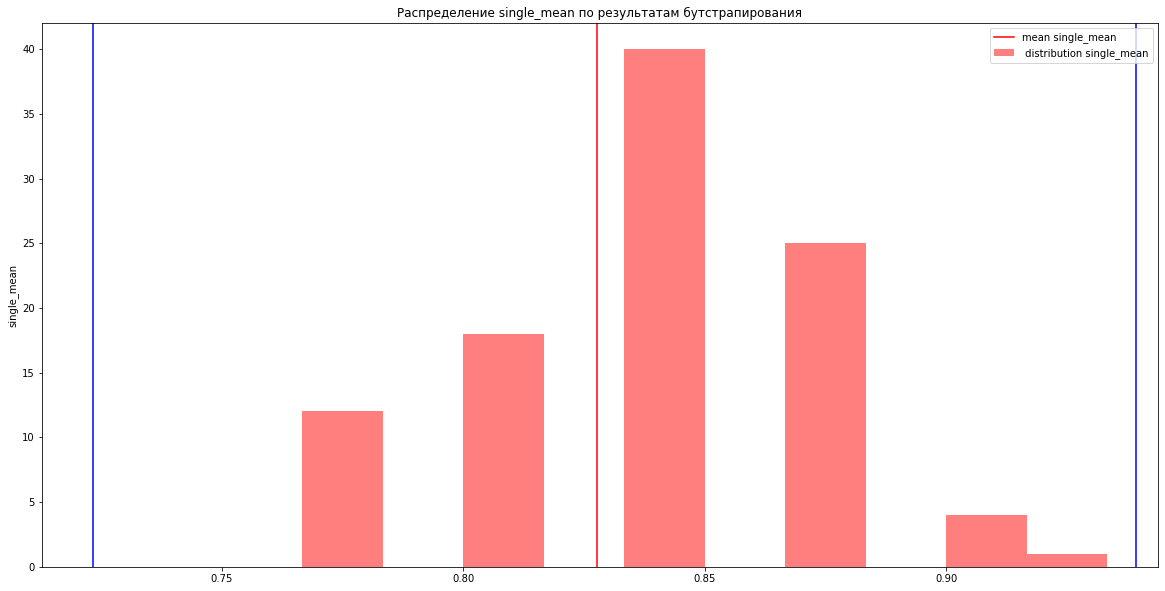

In [68]:
res = valtest_mix_answers_stability(sampler=sampler_mmlu_long,
                                    scorer=scorer,
                                    model=model,
                                    data_types='test',
                                    bootstrap_iter=100)

In [69]:
display(res['report']['result_dataframes'][0])

,Значение single_mean на test,Стандартное отклонение single_mean,Доверительный интервал single_mean
0,0.827778,0.035845,[0.7233; 0.9394]


## Тест 10.4 PSI ответов модели на MMLU-like

### MMLU

In [49]:
data_mmlu_long = joblib.load('data/data_mmlu_long.pkl')[:300]

In [50]:
sampler_mmlu_long = MMLUSampler(data_mmlu_long)

In [51]:
from llm_val.val_test.stability.valtest_psi_mmlu_answers import valtest_psi_mmlu_answers
res = valtest_psi_mmlu_answers(sampler=sampler_mmlu_long,
                               data_type='test',
                               semaphore_threshold=0.2,
                               is_info=False)

In [52]:
display(res['report']['result_dataframes'][0])

,answer,psi_value
0,A,0.000000
1,B,0.027826
2,C,0.016362
3,D,0.000000
4,SUM,0.044188


In [53]:
print(res['report']['semaphore'])

green


## Тест 10.5. Стабильность прогноза модели при изменении порядка примеров и вариантов ответов в системном промпте при использовании few-shot

### MMLU 

In [70]:
from llm_val.val_test.stability.valtest_mix_fewshot_stability import valtest_mix_fewshot_stability

In [71]:
model_fewshot = MultiThreadGigaModel(n_jobs=8,
                                     rquid=RQUID,
                                     auth_data=AUTH_DATA,
                                     oauth_url=total_auth[contour]['OAUTH_URL'],
                                     api_url=total_auth[contour]['API_URL'],
                                     token=total_auth[contour]['TOKEN'],
                                     sys_promt=data_mmlu_few_shot['system'].iloc[0])

При использовании теста для MMLU и необходимости перемешивать варианты ответов необходимо написать парсер для запроса, который будет вытягивать из него вопрос и варианты ответа в обязательном порядке, а также опционально некоторые другие аспекты. Требования к струкутре входа/выхода, а также подробное описание полей есть в докстринге к тесту.

In [72]:
import re
def query_parser(query: str) -> tp.Dict[str, tp.Any]:
    question_start = query.find('Вопрос:') + len('Вопрос:')
    question_end = query.find('Варианты ответов:')
    question = query[question_start: question_end]
    answer_options = re.findall(r'\[([A-Z])\](.+)', query)
    return {'question': question,
            'answer_options': answer_options,
            'question_prefix': 'Вопрос:',
            'answer_options_prefix': 'Варианты ответов:'}

In [77]:
res = valtest_mix_fewshot_stability(sampler_mmlu_few_shot, 
                                    scorer, 
                                    model_fewshot, 
                                    main_metric='single_mean_metric_value',
                                    task_type='mmlu',
                                    metric_agg='single_mean',
                                    query_parser=query_parser,
                                    permute_answer_options=True,
                                    shot_permut_count=2,
                                    answers_permut_per_shot=2,
                                    verbose=True)

  0%|          | 0/10 [00:00<?, ?it/s]

In [78]:
res['report']['result_dataframes'][0]

,Относительное изменение метрики,Светофор
0,0.035714,red


## Тест 10.6. Динамика ключевой метрики качества модели на out-of-sample и out-of-time выборках

In [70]:
from llm_val.val_test.stability.valtest_metric_stability import valtest_metric_stability

### RuBQ

In [74]:
res = valtest_metric_stability(sampler=sampler_rubq,
                               scorer=scorer,
                               main_metric='single_mean_metric_value',
                               data_types=['test', 'test'])

In [75]:
display(res['report']['result_dataframes'][0])

,Значение метрики на test,Абсолютная разница,"Относительная разница, %",Результат теста
single_mean_metric_value,0.8,-0.0,-0.0,green


### MMLU

In [76]:
res = valtest_metric_stability(sampler=sampler_mmlu,
                               scorer=scorer,
                               main_metric='single_mean_metric_value',
                               data_types=['test', 'test'])

In [77]:
display(res['report']['result_dataframes'][0])

,Значение метрики на test,Абсолютная разница,"Относительная разница, %",Результат теста
single_mean_metric_value,0.6,-0.0,-0.0,green


### LongAnswer

In [79]:
res = valtest_metric_stability(sampler=sampler_la,
                               scorer=scorer,
                               main_metric='single_mean_Как вы оцениваете качество CodeReview?',
                               metric_agg='single_mean',
                               data_types=['test', 'test'])

In [81]:
display(res['report']['result_dataframes'][0])

,Значение метрики на test,Абсолютная разница,"Относительная разница, %",Результат теста
single_mean_Как вы оцениваете качество CodeReview?,3.38,-0.0,-0.0,green


In [80]:
display(res['report']['result_dataframes'][1])

,Значение метрики на test,Абсолютная разница,"Относительная разница, %",Результат теста
"single_mean_Вы согласны с замечаниями и проблемами, описанными в CodeReview?",2.88,-0.0,-0.0,green
single_mean_Все существенные проблемы перечислены в CodeReview?,2.88,-0.0,-0.0,green
"single_mean_CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?",2.8,-0.0,-0.0,green
single_mean_Ответ лаконичен и по существу?,3.06,-0.0,-0.0,green
"single_mean_Ответ структурирован, все параметры раскрыты?",2.8,-0.0,-0.0,green


# Раздел 11. Стабильность без таргета

## Тест 11.1: Анализ динамики стандартных статистик для запроса и ответа LLM

In [10]:
from llm_val.val_test.stability_without_target.valtest_statistics_dynamics import valtest_statistics_dynamics

### MMLU 

In [11]:
import numpy as np
from copy import deepcopy
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sentence_transformers import SentenceTransformer

In [12]:
data_mmlu_dgr_ = deepcopy(data_mmlu_dgr)
sampler_mmlu_dgr_ = DGR_MMLUSampler(data_mmlu_dgr_)
sampler_mmlu_dgr_.test['X']['model_answer'] = np.random.choice(['A', 'B', 'C', 'D'], sampler_mmlu_dgr_.test['X'].shape)
sampler_mmlu_dgr_.test['y'] = (sampler_mmlu_dgr_.test['X']['model_answer'] == sampler_mmlu_dgr_.test['X']['true_answer']) * 1.0

X_train, X_test, y_train, y_test = train_test_split(sampler_mmlu_dgr_.test['X'],
                                                    sampler_mmlu_dgr_.test['y'],
                                                    test_size=0.5,
                                                    random_state=42)
sampler_mmlu_dgr_.train = {'X': X_train, 'y': y_train}
sampler_mmlu_dgr_.test = {'X': X_test, 'y': y_test}

X_test, X_val, y_test, y_val = train_test_split(sampler_mmlu_dgr_.test['X'],
                                                sampler_mmlu_dgr_.test['y'],
                                                test_size=0.5,
                                                random_state=42)
sampler_mmlu_dgr_.test = {'X': X_test, 'y': y_test}
sampler_mmlu_dgr_.val = {'X': X_val, 'y': y_val}

In [13]:
rubert = SentenceTransformer('cointegrated/rubert-tiny')

No sentence-transformers model found with name cointegrated/rubert-tiny. Creating a new one with mean pooling.
/home/user/conda/lib/python3.9/site-packages/transformers/tokenization_utils_base.py:1617: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be deprecated in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


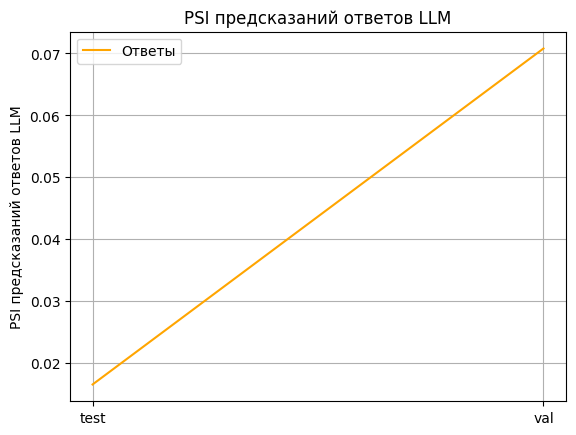

In [14]:
res = valtest_statistics_dynamics(sampler=sampler_mmlu_dgr_,
                                  tokenizer=rubert,
                                  stop_words_list=stopwords.words('russian'),
                                  data_types=('train', 'test', 'val'),
                                  is_discrete=True)


In [15]:
display(res['report']['result_dataframes'][0])

,PSI запросов на test,PSI ответов на test,PSI запросов на val,PSI ответов на val,Светофор по запросам,Светофор по ответам
Доля стоп-слов,0.422699,0.000000,0.293824,0.000000,green,green
Частота токенов,0.143589,0.016518,0.232733,0.070811,green,green
Число токенов,0.330439,0.000000,0.244587,0.000000,green,green
Доля новых токенов,NaN,0.000000,NaN,0.000000,green,green
PSI предсказаний ответов LLM,NaN,0.016518,NaN,0.070811,green,green


### LongAnswer

In [16]:
sampler_la_ = deepcopy(sampler_la2)
sampler_la_.test['X']['question'] = data_la2['question']
sampler_la_.test['y'] = pd.DataFrame({'metric_value': (sampler_la_.test['y'].sum(1) > 15) * 1})
sampler_la_.train = {'X': [], 'y': []}

X_train, X_test, y_train, y_test = train_test_split(sampler_la_.test['X'],
                                                    sampler_la_.test['y'],
                                                    test_size=0.5,
                                                    random_state=42)
sampler_la_.train = {'X': X_train, 'y': y_train}
sampler_la_.test = {'X': X_test, 'y': y_test}

X_test, X_val, y_test, y_val = train_test_split(sampler_la_.test['X'],
                                                sampler_la_.test['y'],
                                                test_size=0.5,
                                                random_state=42)
sampler_la_.test = {'X': X_test, 'y': y_test}
sampler_la_.val = {'X': X_val, 'y': y_val}

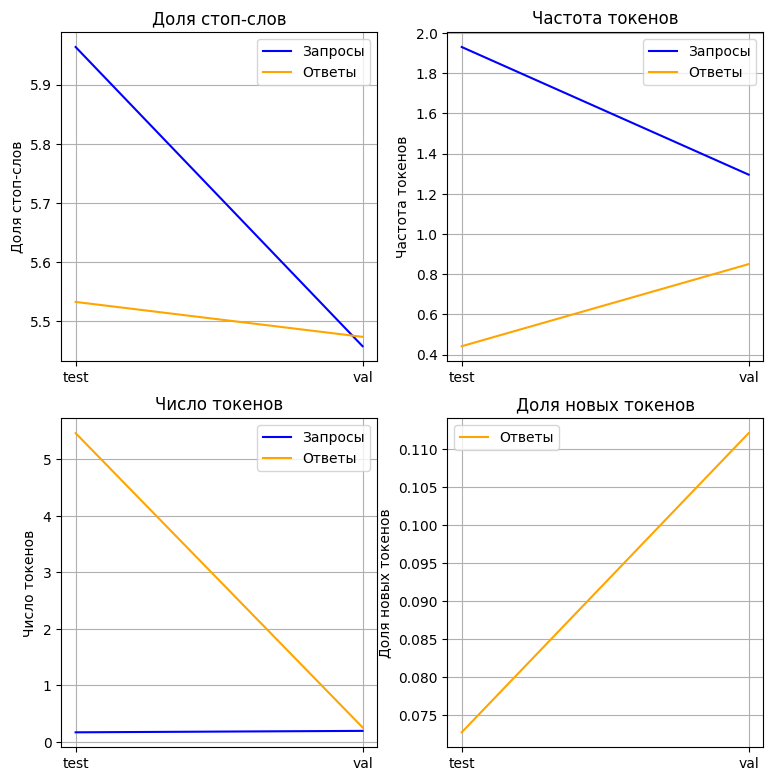

In [17]:
res = valtest_statistics_dynamics(sampler=sampler_la_,
                                  tokenizer=rubert,
                                  stop_words_list=stopwords.words('russian'),
                                  data_types=('train', 'test', 'val'),
                                  is_discrete=False)

In [18]:
display(res['report']['result_dataframes'][0])

,Корреляция с ключевой метрикой качества на train,PSI запросов на test,PSI ответов на test,Корреляция с ключевой метрикой качества на test,PSI запросов на val,PSI ответов на val,Корреляция с ключевой метрикой качества на val,Светофор по запросам,Светофор по ответам
Доля стоп-слов,-0.210182,5.963813,5.532232,0.389331,5.457267,5.473111,0.195718,yellow,yellow
Число токенов,0.234729,0.168950,5.461791,0.000000,0.194479,0.256442,-0.487950,green,green
Частота токенов,NaN,1.929855,0.441655,NaN,1.295017,0.849926,NaN,red,yellow
Доля новых токенов,NaN,NaN,0.072727,NaN,NaN,0.112069,NaN,green,red


In [80]:
display(res['report']['result_dataframes'][1])

,Значение метрики на test,Абсолютная разница,"Относительная разница, %",Результат теста
"single_mean_Вы согласны с замечаниями и проблемами, описанными в CodeReview?",2.88,-0.0,-0.0,green
single_mean_Все существенные проблемы перечислены в CodeReview?,2.88,-0.0,-0.0,green
"single_mean_CodeReview не содержит токсичных комментариев (ненормативная лексика, оскорбительные высказывания или намеки)?",2.8,-0.0,-0.0,green
single_mean_Ответ лаконичен и по существу?,3.06,-0.0,-0.0,green
"single_mean_Ответ структурирован, все параметры раскрыты?",2.8,-0.0,-0.0,green


## Тест 11.2 Разделение выборок out-of-sample и out-of-time посредством стандартной модели

In [12]:
data_mmlu_long = joblib.load('data/data_mmlu_long.pkl')[:100]

In [13]:
sampler_mmlu = OOTMMLUSampler(test=data_mmlu_long[:50], oot=data_mmlu_long[50:])

In [14]:
from llm_val.val_test.stability_without_target.valtest_adversarial_text import valtest_adversarial_text

In [15]:
res = valtest_adversarial_text(sampler_mmlu, 
                               iterations=20,
                               learning_rate=0.1,
                               depth=3,
                               random_state=17)

In [16]:
res['report']['result_dataframes'][0]

,Значение Джини,Светофор
0,0.717653,yellow


## Тест 11.3. Стабильность выбранного ТОП-а при RAG в зависимости от аугментаций текстов на уровне символов или слов.


Для работы этого теста вам понадобится сущность RAGExecutor. Подробнее о ней можно узнать в разделе 3. Качество RAG

In [72]:
from llm_val.val_test.stability_without_target.valtest_rag_top_stability import valtest_rag_top_stability

Запуск теста без аугментаций с парафразированием:

In [96]:
res = valtest_rag_top_stability(sampler_rag, 
                                executor=executor_rag,
                                augmentations_list=['symbol_swap',
                                                    'butter_finger',
                                                    'human_level_augmentations',
                                                    'insert',
                                                    'deletion',
                                                    'word_swap'])

In [97]:
display(res['report']['result_dataframes'][0])

,Размер топа,Строгая стратегия,Мягкая стратегия,Результат теста
0,1,0.600000,0.600000,gray
1,2,0.433333,0.733333,gray
2,3,0.233333,0.711111,yellow


Запуск теста с аугментациями с парафразированием:

In [98]:
import typing as tp
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

class ParaphraseModelHugWrapper:
    def __init__(self, model_name: str, device: str = 'cpu'):
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
        self.device = device
        self.to_device()

    def generate(self, batch: tp.Any, config: tp.Dict[str, tp.Any]):
        return self.model.generate(**batch, **config)

    def to_device(self):
        self.model.to(self.device)
        self.model.eval()

class ParaphraseTokenizerHugWrapper:
    def __init__(self, model_name: str, device: str = 'cpu'):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=False)
        self.device = device

    def decode(self, batch: tp.Any, config: tp.Dict[str, tp.Any]):
        return self.tokenizer.decode(batch.cpu().tolist(), **config)

    def encode(self, batch: tp.List[str], config: tp.Dict[str, tp.Any]):
        return self.tokenizer(batch, **config)

paraphrase_model_config = {'num_beams': 1,
                           'encoder_no_repeat_ngram_size': 3,
                           'do_sample': False}

paraphrase_tokenizer_config = {'decode_config': {'skip_special_tokens': True},
                               'encode_config': {'padding': True, 'return_tensors': 'pt'}}

paraphrase_model = ParaphraseModelHugWrapper('cointegrated/rut5-base-paraphraser')
paraphrase_tokenizer = ParaphraseTokenizerHugWrapper('cointegrated/rut5-base-paraphraser')

In [99]:
result = valtest_rag_top_stability(sampler_rag,
                                   executor=executor_rag,
                                   paraphrase_model=paraphrase_model,
                                   paraphrase_tokenizer=paraphrase_tokenizer,
                                   paraphrase_model_config=paraphrase_model_config,
                                   paraphrase_tokenizer_config=paraphrase_tokenizer_config)

100%|██████████| 1/1 [00:01<00:00,  1.36s/it]


In [100]:
display(result['report']['result_dataframes'][0])


,Размер топа,Строгая стратегия,Мягкая стратегия,Результат теста
0,1,0.657143,0.657143,gray
1,2,0.485714,0.757143,gray
2,3,0.314286,0.742857,yellow


## Тест 11.4. Стабильность воспроизведения ответа 

In [ ]:
from llm_val.val_test.stability_without_target.valtest_answer_reproducibility import valtest_answer_reproducibility, get_augmented_data, get_predictions_for_df

### MMLU

In [ ]:
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

class SemanticModelHugWrapper:
    def __init__(self,
                 model_name: str,
                 device: str='cpu'):
        self.model = SentenceTransformer(model_name)
        self.device = device
     
    def encode(self,
               batch):
        return self.model.encode(batch)

    def get_similarity_matrix(self,
                              embedding,
                              config):
        return self.model.similarity(embedding, embedding)
    
    def to_device(self):
        self.model.to(self.device)
        self.model.eval()


class ParaphraseModelHugWrapper:
    def __init__(self,
                 model_name: str,
                 device: str='cpu'):
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
        self.device = device
     
    def generate(self,
                 batch: tp.Any,
                 config: tp.Dict[str, tp.Any]):
        return self.model.generate(**batch, **config)
     
    def to_device(self):
        self.model.to(self.device)
        self.model.eval()


class ParaphraseTokenizerHugWrapper:
    def __init__(self,
                 model_name: str,
                 device: str='cpu'):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=False)
        self.device = device
     
    def decode(self,
               batch: tp.Any,
               config: tp.Dict[str, tp.Any]):
        return self.tokenizer.decode(batch.cpu().tolist(), **config)
                                                                                 
    def encode(self,
               batch: tp.List[str],
               config: tp.Dict[str, tp.Any]):
        return self.tokenizer(batch, **config)

 
paraphrase_model_config = {'num_beams': 1,
                           'encoder_no_repeat_ngram_size': 3,
                           'do_sample': False}

paraphrase_tokenizer_config = {'decode_config': {'skip_special_tokens': True},
                               'encode_config': {'padding': True,
                                                 'return_tensors': 'pt'}}

paraphrase_model = ParaphraseModelHugWrapper('cointegrated/rut5-base-paraphraser', device='cuda')
paraphrase_tokenizer = ParaphraseTokenizerHugWrapper('cointegrated/rut5-base-paraphraser')

semantic_model_config = {'encode_config':{}}
semantic_model = SemanticModelHugWrapper('cointegrated/rubert-tiny2', device='cuda')

# Количество повторений запросов к LLM в тестах
n_columns = 10

Пусть у нас есть возможность воспроизвести валидируемый пайплайн на нашей стороне c помощью функции `.predict()` передаваемой в тест обертки `model`. Тогда можно использовать тест в следующем формате:

100%|██████████| 1/1 [00:00<00:00,  3.80it/s]


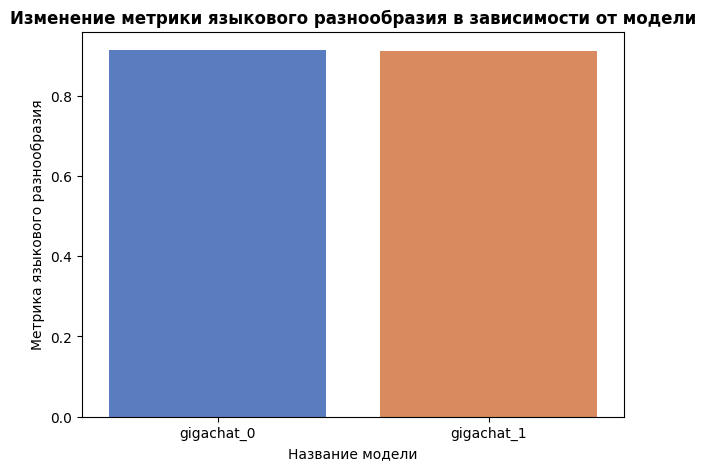

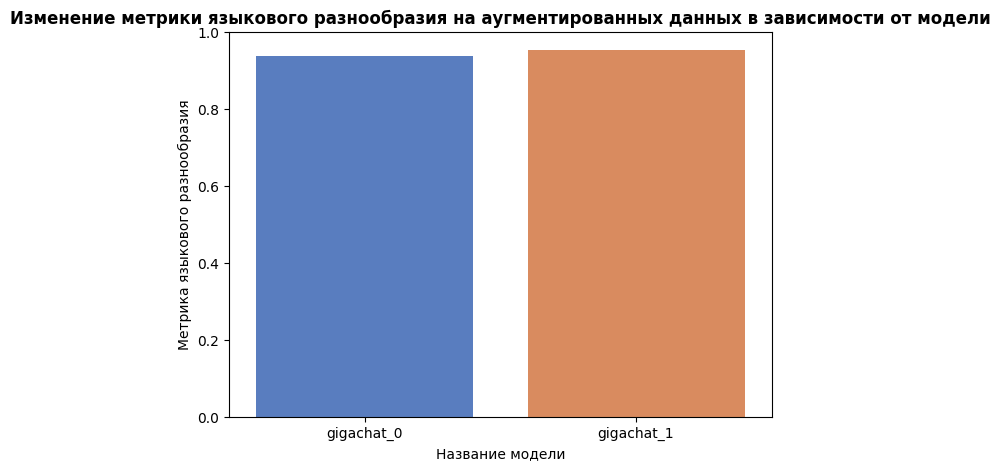

In [ ]:
res = valtest_answer_reproducibility(sampler=sampler_mmlu,
                                     data_type='test',
                                     models_list=[model, model],
                                     is_semantic_diversity=False,
                                     use_augmentations=True,
                                     augmentations_list=['paraphrase', 'use_special_symbol', 'use_translit_symbol'],
                                     n_generated_answers=n_columns, 
                                     p_augmented=0.2,
                                     models_names=['gigachat_0', 'gigachat_1'],
                                     main_model='gigachat_0',
                                     paraphrase_model=paraphrase_model,
                                     paraphrase_model_config=paraphrase_model_config,
                                     paraphrase_tokenizer=paraphrase_tokenizer,
                                     paraphrase_tokenizer_config=paraphrase_tokenizer_config)

In [ ]:
display(res['report']['result_dataframes'][0])

,Метрика языкового разнообразия,Результат теста
Разнообразие на исходных данных,0.913712,red
Разнообразие на аугментированных данных,0.937051,red


Однако нередки ситуации, когда мы не можем воспроизвести пайплайн разработчиков в том же самом месте, где находятся наши тесты, либо мы просто хотим сначала посмотреть на аугментированные данные перед прогоном теста. Тогда нужно использовать функцию `get_augmented_data`, которая вернет DataFrame с запросами, на которых применены аугментации:

In [ ]:
mmlu_aug_results = get_augmented_data(sampler_mmlu,
                                      'test',
                                      ['paraphrase','word_swap', 'use_special_symbol', 'use_translit_symbol'],
                                      p_augmented=0.05,
                                      n_columns=n_columns,
                                      paraphrase_model=paraphrase_model,
                                      paraphrase_model_config=paraphrase_model_config,
                                      paraphrase_tokenizer=paraphrase_tokenizer,
                                      paraphrase_tokenizer_config=paraphrase_tokenizer_config)

mmlu_aug_results.index = mmlu_aug_results.index.astype(str)

0it [00:00, ?it/s]


В итоге мы получаем DataFrame, столбцы которого содержат одинаковые аугментации одного и того же запроса, что можно будет использовать в дальнейшем.

In [ ]:
mmlu_aug_results

,aug_valtest_answer_reproductibility_0,aug_valtest_answer_reproductibility_1,aug_valtest_answer_reproductibility_2,aug_valtest_answer_reproductibility_3,aug_valtest_answer_reproductibility_4,aug_valtest_answer_reproductibility_5,aug_valtest_answer_reproductibility_6,aug_valtest_answer_reproductibility_7,aug_valtest_answer_reproductibility_8,aug_valtest_answer_reproductibility_9
0,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...,Какин объепктьi недвижимости можон приобрпести...
1,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...,Какой сртк минтимальный кредит адоступен при о...
2,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?,chем апартаменты отличаются от квартир ?
3,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...,Какой минимаьлный первоначальоый необходим зно...
4,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...,требования kакие к заещикам предусмотрены для ...


Пусть теперь мы хотим использовать полученные ранее аугментации в тесте, то есть передать их извне. Для этого добавляем данные аугментации в Samlper в DataFrame `X`.

In [ ]:
sampler_mmlu.test['X'] = pd.concat([sampler_mmlu.test['X'], mmlu_aug_results], axis=1)

Далее вызываем тест точно также:

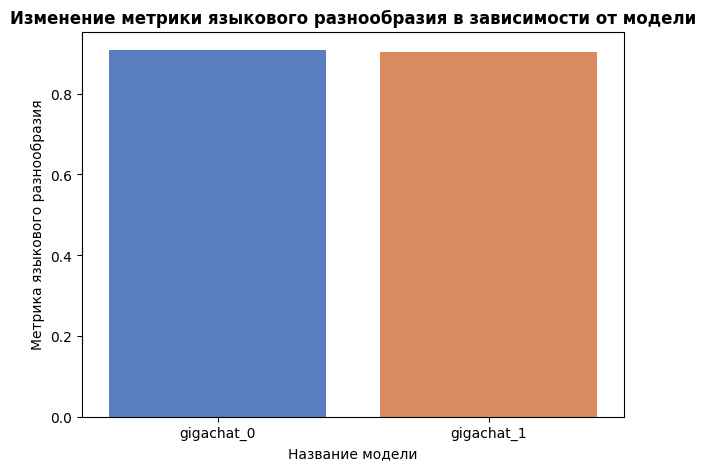

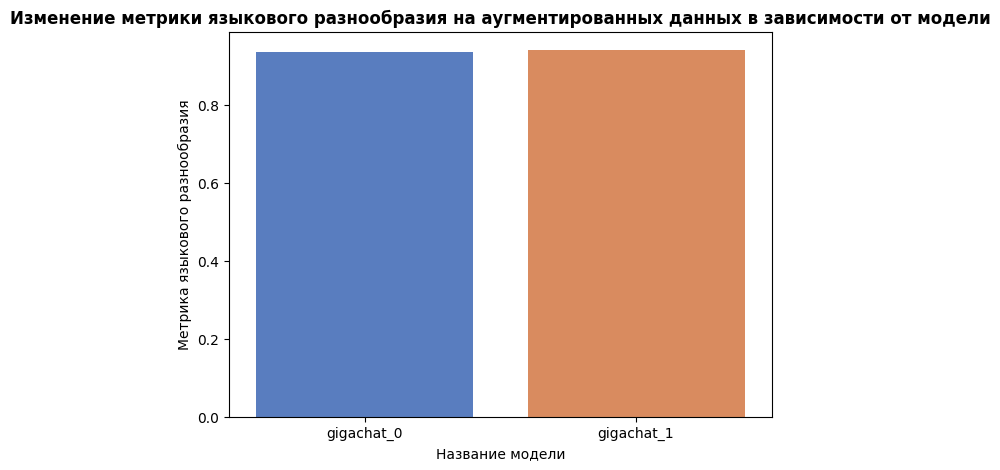

In [ ]:
res = valtest_answer_reproducibility(sampler=sampler_mmlu,
                                     data_type='test',
                                     models_list=[model, model],
                                     is_semantic_diversity=False,
                                     use_augmentations=True,
                                     augmentations_list=['paraphrase','word_swap', 'use_special_symbol', 'use_translit_symbol'],
                                     n_generated_answers=n_columns, 
                                     p_augmented=0.2,
                                     models_names=['gigachat_0', 'gigachat_1'],
                                     main_model='gigachat_0',
                                     paraphrase_model=paraphrase_model,
                                     paraphrase_model_config=paraphrase_model_config,
                                     paraphrase_tokenizer=paraphrase_tokenizer,
                                     paraphrase_tokenizer_config=paraphrase_tokenizer_config)

In [ ]:
display(res['report']['result_dataframes'][0])

,Метрика языкового разнообразия,Результат теста
Разнообразие на исходных данных,0.908239,red
Разнообразие на аугментированных данных,0.935394,red


Если у нас нет возможности получить предсказания через api, то мы получаем их тем способом, который нам предоставили разработчики, по полученным в аугментациях данным. При этом колонки DataFrame должны назваться соответственно `pred_aug_valtest_answer_reproducibility_idx_modelname` для колонок с аугментациями, либо `pred_valtest_answer_reproducibility_idx_modelname` для проверки на воспроизводимость без аугментаций, где `modelname` - имя соответствующей модели, передающееся в тест.

In [ ]:
# Получение самих предсказаний (в реальном процессе - получение любым другим доступным способом)
# В данном случае используется функция get_predictions_for_df - которая генерирует предсказания целиком по DataFrame
# Если в DataFrame один столбец - размножает до нужного числа и получает предикты

# Несколько прогонов базовых запросов
answers = get_predictions_for_df(model, sampler_mmlu.test['X'][['question']], n_columns)
answers.columns = [f"pred_valtest_answer_reproducibility_{idx}_gigachat_0" for idx in range(n_columns)]

# Аугментации
aug_answers = get_predictions_for_df(model, mmlu_aug_results, n_columns)
aug_answers.columns = aug_answers.columns.to_series().apply(lambda x: 'pred_' + x + "_gigachat_0")

In [ ]:
aug_answers

,pred_aug_valtest_answer_reproductibility_0_gigachat_0,pred_aug_valtest_answer_reproductibility_1_gigachat_0,pred_aug_valtest_answer_reproductibility_2_gigachat_0,pred_aug_valtest_answer_reproductibility_3_gigachat_0,pred_aug_valtest_answer_reproductibility_4_gigachat_0,pred_aug_valtest_answer_reproductibility_5_gigachat_0,pred_aug_valtest_answer_reproductibility_6_gigachat_0,pred_aug_valtest_answer_reproductibility_7_gigachat_0,pred_aug_valtest_answer_reproductibility_8_gigachat_0,pred_aug_valtest_answer_reproductibility_9_gigachat_0
0,По программам ипотеки на строящееся жильё чаще...,По программам ипотечного кредитования на строя...,По программам ипотечного кредитования на строя...,По программам ипотеки на строящееся жильё чаще...,По программам ипотечного кредитования на строя...,По программам ипотечного кредитования на строя...,По программам ипотечного кредитования на строя...,По программам ипотеки на строящееся жильё чаще...,По программам ипотеки на строящееся жилье чаще...,По программам ипотеки на строящееся жильё чаще...
1,Минимальный первоначальный взнос по ипотеке об...,Минимальный первоначальный взнос обычно состав...,Минимальный первоначальный взнос по ипотеке за...,Минимально возможный первоначальный взнос по и...,Минимальный первоначальный взнос по ипотеке за...,Минимальный первоначальный взнос по ипотеке об...,Минимальный первоначальный взнос по ипотеке об...,Минимальный первоначальный взнос по ипотеке за...,Минимально допустимый первоначальный взнос по ...,Минимально возможный первоначальный взнос по и...
2,"Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, но юриди...","Апартаменты отличаются от квартиры юридически,...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, но юриди...","Апартаменты отличаются от квартиры юридически,...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, но юриди..."
3,Минимальный первоначальный взнос по кредиту на...,Минимальных официальных требований по первонач...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос по кредиту на...,Минимальных официальных требований по первонач...,Минимальный первоначальный взнос зависит от ба...,Минимальный первоначальный взнос зависит от ба...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос зависит от ус...
4,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...,Требования к участникам программы поддержки ко...


In [ ]:
answers

,pred_valtest_answer_reproducibility_0_gigachat_0,pred_valtest_answer_reproducibility_1_gigachat_0,pred_valtest_answer_reproducibility_2_gigachat_0,pred_valtest_answer_reproducibility_3_gigachat_0,pred_valtest_answer_reproducibility_4_gigachat_0,pred_valtest_answer_reproducibility_5_gigachat_0,pred_valtest_answer_reproducibility_6_gigachat_0,pred_valtest_answer_reproducibility_7_gigachat_0,pred_valtest_answer_reproducibility_8_gigachat_0,pred_valtest_answer_reproducibility_9_gigachat_0
0,По программам ипотечного кредитования на приоб...,По программам ипотечного кредитования на приоб...,По программам ипотечного кредитования на строя...,По программам ипотечного кредитования на строя...,По программам ипотечного кредитования на приоб...,По программам ипотечного кредитования на строя...,По программам ипотечного кредитования на строя...,По программам ипотечного кредитования на приоб...,Приобретение жилья по ипотеке программы «строй...,По программам ипотечного кредитования на строя...
1,Минимальный срок ипотечного кредита обычно сос...,Минимальный срок ипотечного кредита обычно сос...,Минимальный срок ипотечного кредита обычно сос...,Минимальный срок ипотечного кредита обычно сос...,Минимальный срок ипотечного кредита обычно сос...,Минимальный срок ипотечного кредита обычно сос...,Минимальный срок ипотечного кредита обычно сос...,Минимальный срок ипотечного кредита обычно сос...,Минимальный стандартный срок ипотечного кредит...,Минимальный срок ипотечного кредита обычно сос...
2,"Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю...","Апартаменты и квартиры внешне похожи, однако ю..."
3,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос для оформлени...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос для оформлени...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос по кредиту на...,Минимальный первоначальный взнос по кредиту на...
4,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...,Требования к заемщикам по программе кредитован...


Полученные ответы можно явно передать в тест, также просто добавив их к соответствующему датафрейму в сэмплере по ключу `X`:

In [ ]:
answers.index = answers.index.astype(dtype='str')
aug_answers.index = aug_answers.index.astype(dtype='str')
sampler_mmlu.test['X'] = pd.concat([sampler_mmlu.test['X'], answers], axis=1)
sampler_mmlu.test['X'] = pd.concat([sampler_mmlu.test['X'], aug_answers], axis=1)

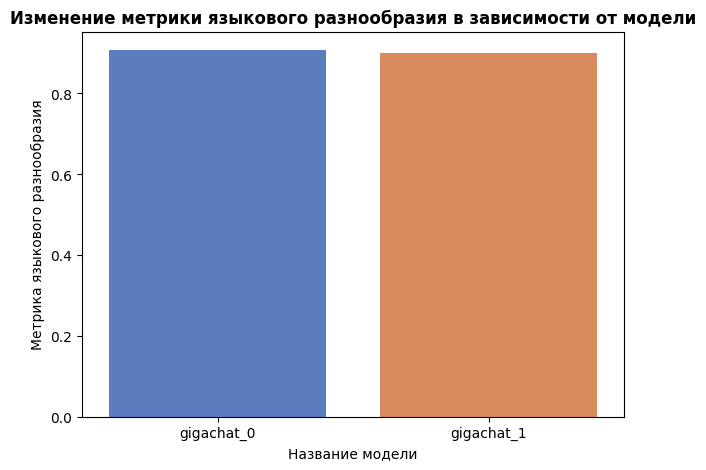

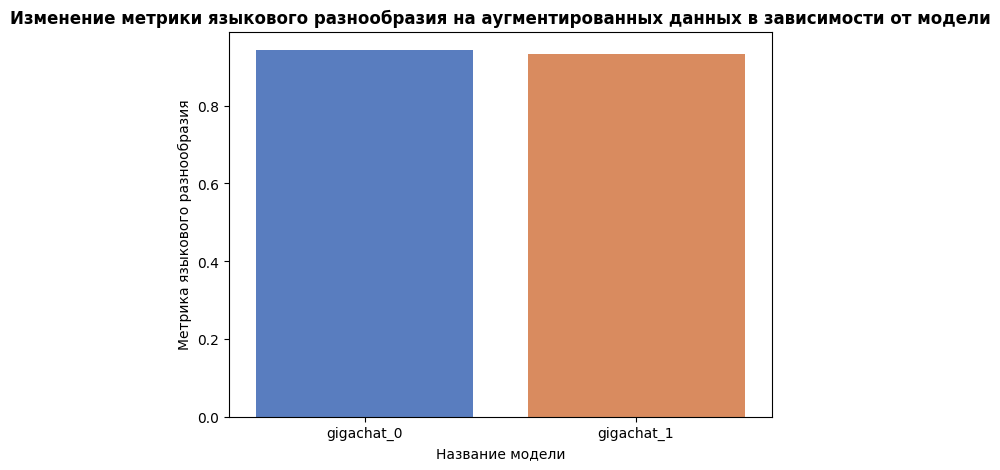

In [ ]:
res = valtest_answer_reproducibility(sampler=sampler_mmlu,
                                     data_type='test',
                                     models_list=[model, model],
                                     is_semantic_diversity=False,
                                     use_augmentations=True,
                                     augmentations_list=['paraphrase', 'use_special_symbol', 'use_translit_symbol'],
                                     n_generated_answers=n_columns, 
                                     p_augmented=0.2,
                                     models_names=['gigachat_0', 'gigachat_1'],
                                     main_model='gigachat_0',
                                     paraphrase_model=paraphrase_model,
                                     paraphrase_model_config=paraphrase_model_config,
                                     paraphrase_tokenizer=paraphrase_tokenizer,
                                     paraphrase_tokenizer_config=paraphrase_tokenizer_config)

In [ ]:
display(res['report']['result_dataframes'][0])

,Метрика языкового разнообразия,Результат теста
Разнообразие на исходных данных,0.907457,red
Разнообразие на аугментированных данных,0.943823,red


## LongAnswer

In [ ]:
sampler_la2.test['X']['question'] = data_la2['question']

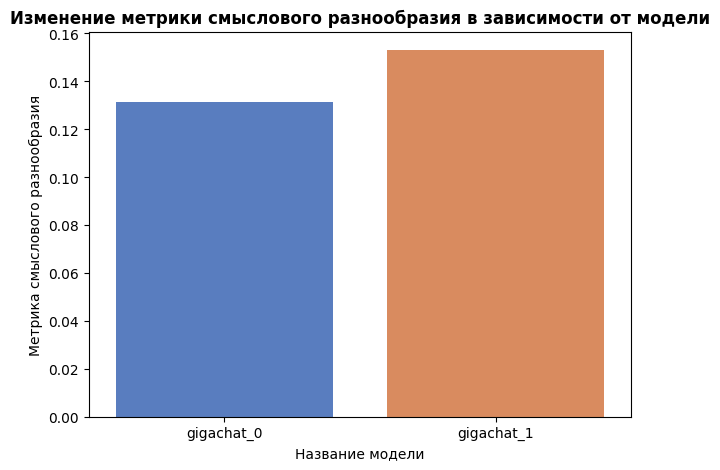

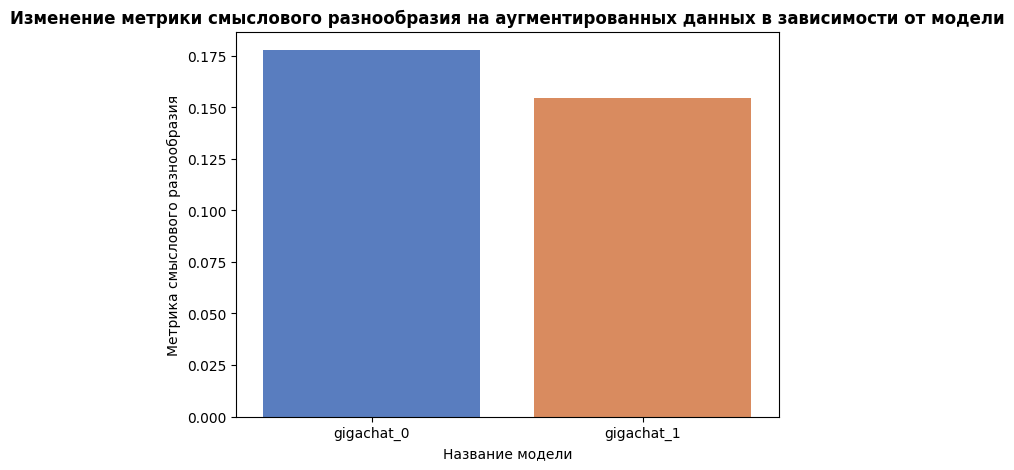

In [ ]:
res = valtest_answer_reproducibility(sampler=sampler_la2,
                                     data_type='test',
                                     models_list=[model, model],
                                     is_semantic_diversity=True,
                                     n_generated_answers=n_columns,
                                     augmentations_list=['word_swap', 'use_special_symbol', 'use_translit_symbol'],
                                     models_names=['gigachat_0', 'gigachat_1'],
                                     main_model='gigachat_1',
                                     semantic_model=semantic_model,
                                     semantic_tokenizer=semantic_model,
                                     semantic_model_config=semantic_model_config,
                                     semantic_tokenizer_config=semantic_model_config)

In [ ]:
display(res['report']['result_dataframes'][0])

,Метрика смыслового разнообразия,Результат теста
Разнообразие на исходных данных,0.153123,green
Разнообразие на аугментированных данных,0.154635,green


## Тест 11.5: Анализ качества ответа LLM в зависимости от локального drift запросов

In [10]:
from llm_val.val_test.stability_without_target.valtest_local_drift_stability import valtest_local_drift_stability

### LongAnswer

In [11]:
import numpy as np
from copy import deepcopy
from sklearn.model_selection import train_test_split

sampler_la_ = deepcopy(sampler_la2)
sampler_la_.test['X']['question'] = data_la2['question'] 

X_train, X_test, y_train, y_test = train_test_split(sampler_la_.test['X'],
                                                    sampler_la_.test['y'],
                                                    test_size=0.5,
                                                    random_state=42)
sampler_la_.train = {'X': X_train, 'y': y_train}
sampler_la_.test = {'X': X_test, 'y': y_test}

In [12]:
import faiss

class ANN():
    def __init__(self,
                 n_partitions: int=10,
                 nprobe: int=2):
        self.n_partitions = n_partitions
        self.nprobe = nprobe
        self.index = None
        
    def create_index(self,
                     embedding: tp.Any,
                     exact: bool=False):
        '''
        Создает в классе индекс для дальнейшего поиска по данным эмбеддингам
        Parameters:
            embedding: Набор эмбеддингов для создания индекса
            exact: Если True, то запускается точный поиск (kNN), рекомендуется для небольших наборов (меньше 10к наблюдений) 
        '''
        db_vectors = np.array(embedding).astype(np.float32)
        dimension = db_vectors.shape[1]
        faiss.normalize_L2(db_vectors)
        self.exact = exact
        if self.exact:
            self.index = faiss.IndexIDMap(faiss.IndexFlatIP(dimension))
        else:
            quantizer = faiss.IndexFlatL2(dimension)
            self.index = faiss.IndexIVFFlat(quantizer,
                                            dimension,
                                            self.n_partitions,
                                            faiss.METRIC_INNER_PRODUCT)
            self.index.train(db_vectors)
        self.index.add_with_ids(db_vectors, np.arange(len(db_vectors)))

    
    def search_query(self,
                     query_vector: tp.Any,
                     k: int) -> tp.List[tp.Dict[str, tp.Any]]:
        '''
        Выполняет поиск запроса в индексе
        Parameters:
            query_vector: Вектор эмбеддинга запроса
            k: Число получаемых наиболее близких запросов
        Return: 
            Список словарей с индексами наиболее близких запросов и значениями близости
        '''
        query_vector = np.array(query_vector).astype(np.float32).reshape(1, -1)
        self.index.nprobe = self.nprobe
        faiss.normalize_L2(query_vector)
        similarities, similarities_ids = self.index.search(query_vector, k)
        return [{'id': similarities_ids[0][i], 'similarity': similarities[0][i]} for i in range(len(similarities_ids[0]))]
    
ann = ANN()
config = {'create_index': {'exact': True}, 'search_query': {}}

Для проведения теста необходимо перевести разметку датасета типа LongAnswer в бинарные метки. Это необходимо сделать функцией, которая должна выдать Series со значениями 0 и 1. Эта функция должна быть передана в качестве параметра metric_binarizer в тест.

In [13]:
def long_answer_binarizer(y_data: pd.DataFrame) -> pd.Series:
    return pd.Series((y_data.sum(1) > 15) * 1)

In [14]:
res = valtest_local_drift_stability(sampler=sampler_la_,
                                    scorer=scorer,
                                    main_metric='single_mean_metric_value',
                                    model=model,
                                    ann=ann,
                                    ann_config=config,
                                    n_closest=4,
                                    metric_binarizer=long_answer_binarizer,
                                    metric_agg='single_mean',
                                    data_types=('train', 'test'))

In [15]:
display(res['report']['result_dataframes'][0])

,Значение метрики на train,Оценённое значение метрики на test,Абсолютная разница,Мера надежности теста,Результат теста
0,0.8,0.705614,0.094386,0.816813,green


## Тест 11.6: Анализ качества ответа LLM в зависимости от глобального drift запросов

In [10]:
from llm_val.val_test.stability_without_target.valtest_global_drift_stability import valtest_global_drift_stability

### LongAnswer

In [11]:
from copy import deepcopy
from sklearn.model_selection import train_test_split

sampler_la_ = deepcopy(sampler_la2)
sampler_la_.test['X']['question'] = data_la2['question'] 

X_train, X_test, y_train, y_test = train_test_split(sampler_la_.test['X'],
                                                    sampler_la_.test['y'],
                                                    test_size=0.5,
                                                    random_state=42)
sampler_la_.train = {'X': X_train, 'y': y_train}
sampler_la_.test = {'X': X_test, 'y': y_test}

Для проведения теста необходимо перевести разметку датасета типа LongAnswer в бинарные метки. Это необходимо сделать функцией, которая должна выдать Series со значениями 0 и 1. Эта функция должна быть передана в качестве параметра metric_binarizer в тест.

In [12]:
def long_answer_binarizer(y_data: pd.DataFrame) -> pd.Series:
    return pd.Series((y_data.sum(1) > 15) * 1)

In [13]:
res = valtest_global_drift_stability(sampler=sampler_la_,
                                     scorer=scorer,
                                     main_metric='single_mean_metric_value',
                                     model=model,
                                     n_chunks=3,
                                     top_distance_features=[5, 10],
                                     p_value=0.2, 
                                     corr_threshold=0.5,
                                     metric_binarizer=long_answer_binarizer)

In [14]:
display(res['report']['result_dataframes'][0])

,Значение метрики на train,Оценённое значение метрики на test,Абсолютная разница,Результат теста
0,0.72,0.690782,0.029218,green


# Раздел А.2 Качество прогноза end-2-end

## Тест А.2.3 Анализ динамики ключевой метрики качества модели в зависимости от длины запроса

Для работы этого теста нужна модель-обёртка, имеющая метод ```get_token_count``` - подсчитывающий число токенов в тексте.

Если поле ```token_counter_model``` указано как ```None```, будет произведен наивный подсчет числа токенов: ```len(text.encode('utf-8')) // 4 + 1```

В самом тесте наиболее интересный параметр - ```min_bin_size```. Он фиксирует минимально возможную долю наблюдений в одном бакете/бине. Варьируя его, можно получать более интерпритируемую визуализацию результатов. Бины и значения длин в токенах находятся в ```res['precomputed']['token_and_bins']```.

`bin_algo` - алгоритм формирования бинов. По умолчанию: `iter`.

- `iter`: итеративный алгоритм
- `merge`: алгоритм слияния бинов

См. подробнее `utils.binarization_algos`

In [27]:
import numpy as np
from llm_val.val_test.model_quality.valtest_metric_by_token_size import valtest_metric_by_token_size

In [28]:
class TokenCountModel:
    def __init__(self, 
                 contour="sigma", 
                 model_name="GigaChat-2-Max"):
        self.model_name = model_name
        self.model = GigaChatAPI(contour=contour, 
                                 auth_data=AUTH_DATA, 
                                 api_url=sigma_auth['API_URL'], 
                                 oauth_url=sigma_auth['OAUTH_URL'], 
                                 rquid=RQUID)
        
    def get_token_count(self, text: str) -> int:
        '''
        Возвращает число токенов
        Parameters:
            text: Входной текст.
        Return:
            Число токенов текста, используя токенезатор модели model_name
        '''
        return self.model.get_token_count(text,
                                          model=self.model_name, 
                                          profanity_check=False)['tokens']

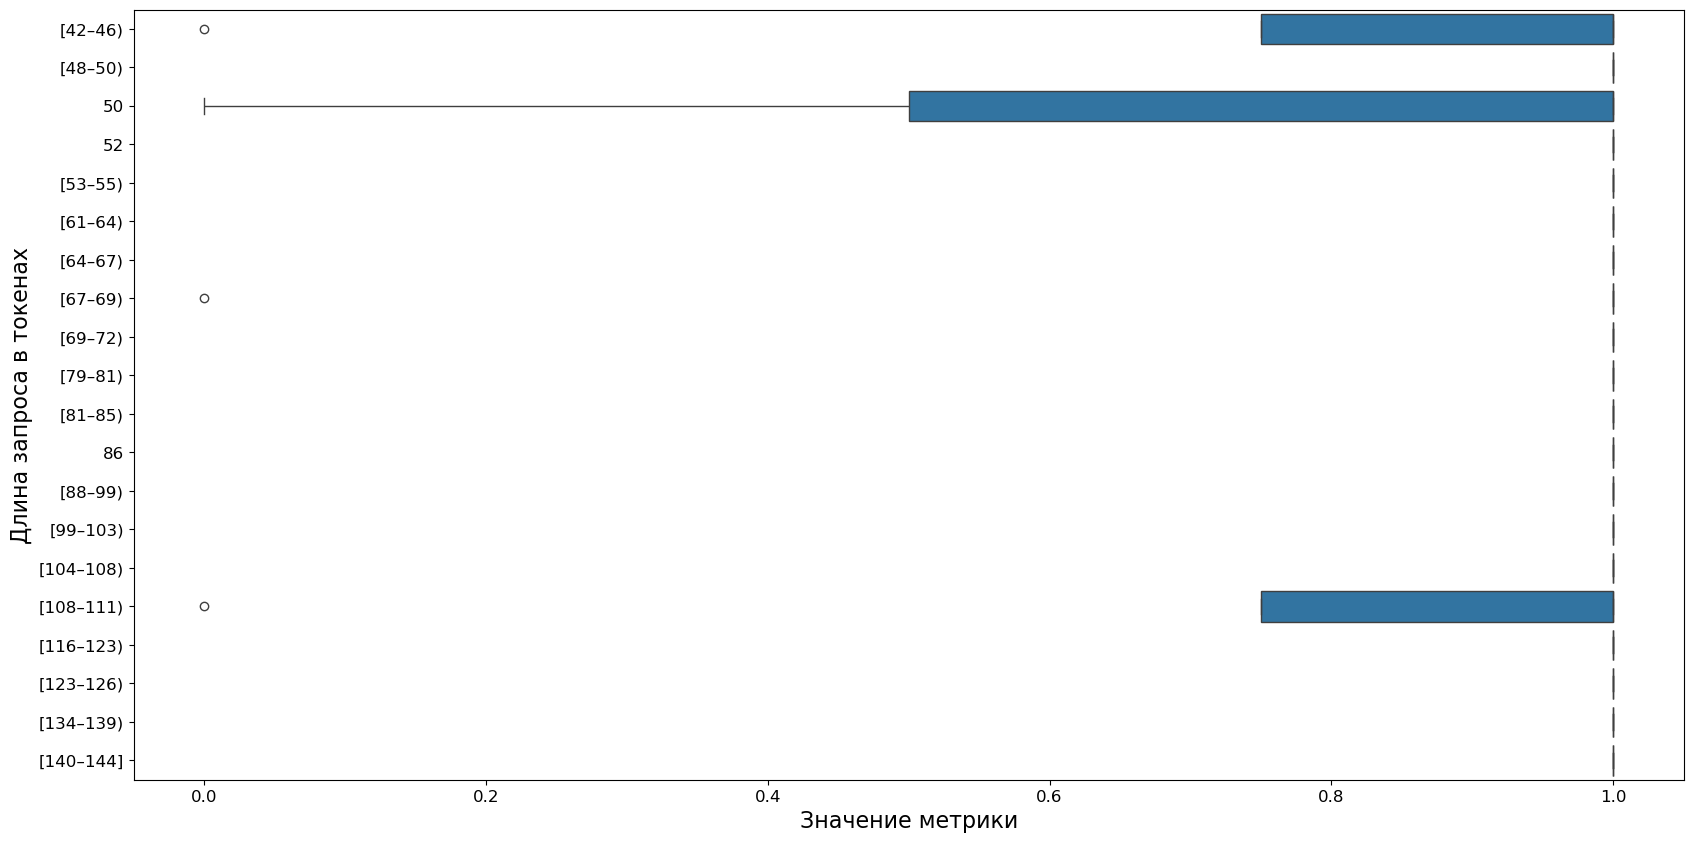

In [29]:
gc_token_count_model = TokenCountModel()
sampler_mmlu_dgr_cripto.test['y'] = pd.DataFrame(np.random.choice([0,1], len(sampler_mmlu_dgr_cripto.test['X']), p=[0.05, 0.95]))
res = valtest_metric_by_token_size(sampler=sampler_mmlu_dgr_cripto,
                                   scorer=scorer,
                                   data_type='test',
                                   token_counter_model=gc_token_count_model,
                                   min_bin_size=0.05,
                                   bin_algo='iter',
                                   metric_agg='single_mean', 
                                   n_bootstrap=100, 
                                   quantile=0.95,  
                                   random_state=73)

In [30]:
res['report']['result_dataframes'][0]

,Среднее значение метрики single_mean_0,Доверительный интервал метрики single_mean_0
[42–46),0.750,[0.301; 0.954]
[48–50),1.000,[0.439; 1.000]
50,0.667,[0.208; 0.939]
52,1.000,[0.510; 1.000]
[53–55),1.000,[0.566; 1.000]
[61–64),1.000,[0.439; 1.000]
[64–67),1.000,[0.439; 1.000]
[67–69),0.800,[0.376; 0.964]
[69–72),1.000,[0.510; 1.000]
[79–81),1.000,[0.439; 1.000]


# Раздел A.3. Аспект Инструменты

## Тест А.3.2. Изменение ответа агента при постепенном удалении инструментов


В данном тесте логика подсчета светофора дополнена относительно методики.

Тест можно проводить по автометрике (при ее наличии), а можно - по метрикам на исходных ответах (в методике приведен подсчет светофоров только для этого сценария).

В случае проведения теста по автометрике доступен расчет светофора только по статтестам по сравнению средних и дисперсий, в случае проведения теста на исходных ответах - по методике и по статтестам по сравнению средних и дисперсий. Даже во втором случае подсчет светофоров через статтесты выглядит предпочтительнее, так как статтесты обеспечивают статистически строгое и объективное доказательство наличия эффекта, учитывая не только разницу в средних, но и вариативность данных, что минимизирует риск принятия ложноположительных или ложноотрицательных решений.

В случае выставления светофора по статтестам используется худший светофор из всех проведенных тестов по средним и дисперсиям.

В зависимости от того, есть ли у вас автометрика, вы должны либо использовать функцию для подсчета корректности ответа, чтобы можно было эту автометрику посчитать, либо использовать функцию получения эмбеддингов, чтобы можно было посчитать метрики близости ответов модели.

Ниже приведены примеры использования всех этих способов работы с тестом. Модель (агент) представлена классом AgentWrapper, функция для подсчета корректности ответа - check_answer_by_length, функция получения эмбеддингов - get_embedding.

Функционал теста предполагает работу в 3 основных режимах удаления инструментов (removal_mode): 
- 'sequential' - последовательное удаление по одному (согласно методике) (режим по умолчанию)
- 'custom' - использование пользовательского списка инструментов (необходимо указать список всех списков включенных инструментов, на которых нужно проверить качество)
- 'random' - случайное удаление инструментов (каждый раз будет удаляться от 1 до M-1 инструментов, где M - суммарное число инструментов; отличие от 'sequential' состоит только в том, что выбор удаляемых инструментов случайный)

In [23]:
from llm_val.val_test.tools.valtest_metric_after_tools_removal import valtest_metric_after_tools_removal


In [24]:
import typing as tp
from copy import deepcopy

class AgentWrapper:
    def __init__(self, llm_model, 
                 tools: tp.List[tp.Dict] = None):
        self.llm_model = llm_model
        self._tools = tools if tools is not None else []
        self._temperature = getattr(llm_model, 'temperature', 1.0)
        self._top_p = getattr(llm_model, 'top_p', 0.0)

    def predict(self, 
                questions: tp.Union[str, tp.List[str]]) -> tp.List[str]:
        """Генерация ответов на вопросы."""
        if isinstance(questions, str):
            questions = [questions]
        
        prompts = []
        for question in questions:
            prompt = self._build_prompt(question)
            prompts.append(prompt)
        
        responses = self.llm_model.predict(prompts)        
        return self._process_responses(responses)
    
    def _build_prompt(self, 
                      question: str) -> str:
        """Строит промпт с учетом доступных инструментов"""
        if not self._tools:
            return question
        
        tools_info = "\n".join([
            f"- {tool['name']}: {tool.get('description', 'Без описания')}"
            for tool in self._tools
        ])
        
        return f"""Доступные инструменты: {tools_info} 
        Вопрос: {question} 
        Ответ:"""
    
    def _process_responses(self, 
                           responses: tp.Any) -> tp.List[str]:
        """Обрабатывает ответы модели"""
        if not isinstance(responses, list):
            responses = [responses]
        
        return [
            response[0] if isinstance(response, list) and response else 
            response if isinstance(response, str) else 
            str(response)
            for response in responses
        ]

    def get_params(self) -> tp.Dict[str, tp.Any]:
        return {'tools': deepcopy(self._tools),
                'temperature': self._temperature,
                'top_p': self._top_p}

    def set_params(self, 
                   **kwargs):
        if 'tools' in kwargs:
            self._tools = kwargs['tools']
        if 'temperature' in kwargs:
            self._temperature = kwargs['temperature']
        if 'top_p' in kwargs:
            self._top_p = kwargs['top_p']

In [88]:
import numpy as np
from typing import List

from llm_val.utils.api import GigaChatAPI

api = GigaChatAPI(contour='sigma',
                  auth_data=AUTH_DATA,
                  rquid=RQUID)

def get_embedding(text: str, 
                  max_length: int=1024) -> np.ndarray:
    '''
    Получает эмбеддинг для текста.
    Parameters:
        text: Входной текст.
        max_length: Максимальная длина текста (в символах).

    Returns:
        Эмбеддинг текста.
    '''
    parts = [text[i:i + max_length] for i in range(0, len(text), max_length)]
    
    embeddings = []
    for part in parts:
        embedding = api.get_embedding(part)[0]['embedding']
        embeddings.append(np.array(embedding))
    
    return np.mean(embeddings, axis=0).reshape(1, -1)

def get_embeddings(texts: List[str], 
                   max_length: int = 1024) -> List[np.ndarray]:
    """Получает эмбеддинги для списка текстов"""
    return [get_embedding(text, max_length) for text in texts]

In [103]:
tools = [{'name': 'search_weather', 'description': 'Поиск информации о погоде'},
         {'name': 'calculate_math', 'description': 'Математические вычисления'}]
    
agent = AgentWrapper(model, 
                     tools)

agent.set_params(sys_prompt="Ты - полезный AI ассистент. Используй доступные инструменты для точных ответов.")

Теперь посмотрим на способы проведения теста:


Случай, когда нет автометрики и результат выставляем по threshold'ам из методики:

In [104]:
result = valtest_metric_after_tools_removal(sampler=sampler_la,
                                            model=agent,
                                            get_embed_func=get_embeddings,
                                            remuval_num=2,
                                            stat_checker=False,
                                            data_type='test')

Tools removal sets: 100%|██████████| 2/2 [01:29<00:00, 44.52s/it]


In [105]:
display(result['report']['result_dataframes'][0])


,Удаляются,Косинусная близость,ROUGE-L,Результат теста
0,Инструмент_1,0.971,0.382,green
1,Инструмент_2,0.968,0.376,green
2,Итог,,,green


Случай, когда нет автометрики и используем статистический подход:



In [106]:
result = valtest_metric_after_tools_removal(sampler=sampler_la,
                                            model=agent,
                                            get_embed_func=get_embeddings,
                                            data_type='test')

Tools removal sets: 100%|██████████| 2/2 [01:06<00:00, 33.38s/it]


In [100]:
display(result['report']['result_dataframes'][0])


,Метрика,Значение
0,Косинусная близость,0.968
1,Rouge-L,0.378
2,p-value (cosine средние),0.184
3,p-value (cosine дисперсии),0.005
4,p-value (rouge средние),0.154
5,p-value (rouge дисперсии),0.026
6,Результат,red


Случай, когда автометрика есть:



In [107]:
def check_answer_by_length(question: str, 
                           answers: tp.List[str]) -> bool:
    """
    Пример функции проверки корректности ответа.
    """
    if not answers:
        return False
    answer = answers[0]
    return len(answer) > 2000

In [108]:
result = valtest_metric_after_tools_removal(sampler=sampler_la,
                                            model=agent,
                                            check_correct_answer=check_answer_by_length,
                                            data_type='test')

Tools removal sets: 100%|██████████| 2/2 [00:58<00:00, 29.25s/it]
/home/sigma.sbrf.ru@22314343/.conda/envs/agent_env/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


In [109]:
display(result['report']['result_dataframes'][0])


,Метрика,Значение
0,Базовое качество,1.000
1,Качество после удаления,0.900
2,p-value (средние),0.313
3,p-value (дисперсии),0.000
4,Результат,red


## Тест А.3.3 Изменение ответа агента при перемешивании списка инструментов

В данном тесте логика подсчета светофора дополнена относительно методики.

Тест можно проводить по автометрике (при ее наличии), а можно - по метрикам на исходных ответах (в методике приведен подсчет светофоров только для этого сценария).

В случае проведения теста по автометрике доступен расчет светофора только по статтестам по сравнению средних и дисперсий, в случае проведения теста на исходных ответах - по методике и по статтестам по сравнению средних и дисперсий. Даже во втором случае подсчет светофоров через статтесты выглядит предпочтительнее, так как статтесты обеспечивают статистически строгое и *объективное* доказательство наличия эффекта, учитывая не только разницу в средних, но и вариативность данных, что минимизирует риск принятия ложноположительных или ложноотрицательных решений.

В случае выставления светофора по статтестам используется худший светофор из всех проведенных тестов по средним и дисперсиям.

В зависимости от того, есть ли у вас автометрика, вы должны либо использовать функцию для подсчета корректности ответа, чтобы можно было эту автометрику посчитать, либо использовать функцию получения эмбеддингов, чтобы можно было посчитать метрики близости ответов модели.

Ниже приведены примеры использования всех этих способов работы с тестом. Модель (агент) представлена классом AgentWrapper, функция для подсчета корректности ответа - check_answer_by_length, функция получения эмбеддингов - get_embedding.


In [114]:
from llm_val.val_test.tools.valtest_metric_after_tools_shuffle import valtest_metric_after_tools_shuffle


In [115]:
import typing as tp
from copy import deepcopy

class AgentWrapper:
    def __init__(self, llm_model, 
                 tools: tp.List[tp.Dict] = None):
        self.llm_model = llm_model
        self._tools = tools if tools is not None else []
        self._temperature = getattr(llm_model, 'temperature', 1.0)
        self._top_p = getattr(llm_model, 'top_p', 0.0)

    def predict(self, 
                questions: tp.Union[str, tp.List[str]]) -> tp.List[str]:
        """Генерация ответов на вопросы."""
        if isinstance(questions, str):
            questions = [questions]
        
        prompts = []
        for question in questions:
            prompt = self._build_prompt(question)
            prompts.append(prompt)
        
        responses = self.llm_model.predict(prompts)        
        return self._process_responses(responses)
    
    def _build_prompt(self, 
                      question: str) -> str:
        """Строит промпт с учетом доступных инструментов"""
        if not self._tools:
            return question
        
        tools_info = "\n".join([
            f"- {tool['name']}: {tool.get('description', 'Без описания')}"
            for tool in self._tools
        ])
        
        return f"""Доступные инструменты: {tools_info} 
        Вопрос: {question} 
        Ответ:"""
    
    def _process_responses(self, 
                           responses: tp.Any) -> tp.List[str]:
        """Обрабатывает ответы модели"""
        if not isinstance(responses, list):
            responses = [responses]
        
        return [
            response[0] if isinstance(response, list) and response else 
            response if isinstance(response, str) else 
            str(response)
            for response in responses
        ]

    def get_params(self) -> tp.Dict[str, tp.Any]:
        return {'tools': deepcopy(self._tools),
                'temperature': self._temperature,
                'top_p': self._top_p}

    def set_params(self, 
                   **kwargs):
        if 'tools' in kwargs:
            self._tools = kwargs['tools']
        if 'temperature' in kwargs:
            self._temperature = kwargs['temperature']
        if 'top_p' in kwargs:
            self._top_p = kwargs['top_p']

In [116]:
import numpy as np
from typing import List

from llm_val.utils.api import GigaChatAPI

api = GigaChatAPI(contour='sigma',
                  auth_data=AUTH_DATA,
                  rquid=RQUID)

def get_embedding(text: str, 
                  max_length: int=1024) -> np.ndarray:
    '''
    Получает эмбеддинг для текста.
    Parameters:
        text: Входной текст.
        max_length: Максимальная длина текста (в символах).

    Returns:
        Эмбеддинг текста.
    '''
    parts = [text[i:i + max_length] for i in range(0, len(text), max_length)]
    
    embeddings = []
    for part in parts:
        embedding = api.get_embedding(part)[0]['embedding']
        embeddings.append(np.array(embedding))
    
    return np.mean(embeddings, axis=0).reshape(1, -1)

def get_embeddings(texts: List[str], 
                   max_length: int = 1024) -> List[np.ndarray]:
    """Получает эмбеддинги для списка текстов"""
    return [get_embedding(text, max_length) for text in texts]

In [117]:
tools = [{'name': 'search_weather', 'description': 'Поиск информации о погоде'},
         {'name': 'calculate_math', 'description': 'Математические вычисления'}]
    
agent = AgentWrapper(model, 
                     tools)

agent.set_params(sys_prompt="Ты - полезный AI ассистент. Используй доступные инструменты для точных ответов.")


Теперь посмотрим на способы проведения теста:



Случай, когда нет автометрики и результат выставляем по threshold'ам из методики:

In [129]:
result = valtest_metric_after_tools_shuffle(sampler=sampler_la,
                                            model=agent,
                                            get_embed_func=get_embeddings,
                                            shuffle_num=2, 
                                            stat_checker=False,
                                            data_type='test')

Tools shuffle: 100%|██████████| 2/2 [00:35<00:00, 17.60s/it]


In [130]:
display(result['report']['result_dataframes'][0])


,Метрика,Значение
0,Косинусная близость,0.970
1,Rouge-L,0.362
2,Результат,green


Случай, когда нет автометрики и используем статистический подход:

In [120]:
result = valtest_metric_after_tools_shuffle(sampler=sampler_la,
                                            model=agent,
                                            get_embed_func=get_embeddings,
                                            shuffle_num=10, 
                                            data_type='test')

Tools shuffle: 100%|██████████| 10/10 [03:03<00:00, 18.39s/it]


In [121]:
display(result['report']['result_dataframes'][0])

,Метрика,Значение
0,Косинусная близость,0.966
1,Rouge-L,0.383
2,p-value (cosine средние),0.255
3,p-value (cosine дисперсии),0.779
4,p-value (rouge средние),0.011
5,p-value (rouge дисперсии),0.576
6,Результат,red


Случай, когда автометрика есть:

In [122]:
def check_answer_by_length(question: str, 
                           answers: tp.List[str]) -> bool:
    """
    Пример функции проверки корректности ответа.
    """
    if not answers:
        return False
    answer = answers[0]
    return len(answer) > 2000

In [123]:
result = valtest_metric_after_tools_shuffle(sampler=sampler_la,
                                            model=agent,
                                            shuffle_num=10,
                                            check_correct_answer=check_answer_by_length,
                                            data_type='test')

Tools shuffle: 100%|██████████| 10/10 [01:30<00:00,  9.00s/it]


In [124]:
display(result['report']['result_dataframes'][0])

,Метрика,Значение
0,Базовое качество,0.940
1,Качество после перемешивания,0.940
2,p-value (средние),1.000
3,p-value (дисперсии),1.000
4,Результат,red


## Тест А.3.4. Изменение ответа агента при уточнении описания функции


В данном тесте логика подсчета светофора дополнена относительно методики.

Тест можно проводить по автометрике (при ее наличии), а можно - по метрикам на исходных ответах.

В любом случае светофор рассчитывается по тесту Уилкоксона на разностях.

В зависимости от того, есть ли у вас автометрика, вы должны либо использовать функцию для подсчета корректности ответа, чтобы можно было эту автометрику посчитать, либо использовать функцию получения эмбеддингов, чтобы можно было посчитать метрики близости ответов модели.

Ниже приведены примеры использования всех этих способов работы с тестом. Модель (агент) представлена классом AgentWrapper, функция для подсчета корректности ответа - check_answer_by_length, функция получения эмбеддингов - get_embedding, функция для перефразирования описания инструмента - rephrase_tool_description с примером system\user-промптов для модели перефразирования описания. 


In [206]:
from llm_val.val_test.tools.valtest_metric_after_tools_refine import valtest_metric_after_tools_refine


In [207]:
import typing as tp
from copy import deepcopy

class AgentWrapper:
    def __init__(self, llm_model, 
                 tools: tp.List[tp.Dict] = None):
        self.llm_model = llm_model
        self._tools = tools if tools is not None else []
        self._temperature = getattr(llm_model, 'temperature', 1.0)
        self._top_p = getattr(llm_model, 'top_p', 0.0)

    def predict(self, 
                questions: tp.Union[str, tp.List[str]]) -> tp.List[str]:
        """Генерация ответов на вопросы."""
        if isinstance(questions, str):
            questions = [questions]
        
        prompts = []
        for question in questions:
            prompt = self._build_prompt(question)
            prompts.append(prompt)
        
        responses = self.llm_model.predict(prompts)        
        return self._process_responses(responses)
    
    def _build_prompt(self, 
                      question: str) -> str:
        """Строит промпт с учетом доступных инструментов"""
        if not self._tools:
            return question
        
        tools_info = "\n".join([
            f"- {tool['name']}: {tool.get('description', 'Без описания')}"
            for tool in self._tools
        ])
        
        return f"""Доступные инструменты: {tools_info} 
        Вопрос: {question} 
        Ответ:"""
    
    def _process_responses(self, 
                           responses: tp.Any) -> tp.List[str]:
        """Обрабатывает ответы модели"""
        if not isinstance(responses, list):
            responses = [responses]
        
        return [
            response[0] if isinstance(response, list) and response else 
            response if isinstance(response, str) else 
            str(response)
            for response in responses
        ]

    def get_params(self) -> tp.Dict[str, tp.Any]:
        return {'tools': deepcopy(self._tools),
                'temperature': self._temperature,
                'top_p': self._top_p}

    def set_params(self, 
                   **kwargs):
        if 'tools' in kwargs:
            self._tools = kwargs['tools']
        if 'temperature' in kwargs:
            self._temperature = kwargs['temperature']
        if 'top_p' in kwargs:
            self._top_p = kwargs['top_p']

In [208]:
import numpy as np
from typing import List

from llm_val.utils.api import GigaChatAPI

api = GigaChatAPI(contour='sigma',
                  auth_data=AUTH_DATA,
                  rquid=RQUID)

def get_embedding(text: str, 
                  max_length: int=1024) -> np.ndarray:
    '''
    Получает эмбеддинг для текста.
    Parameters:
        text: Входной текст.
        max_length: Максимальная длина текста (в символах).

    Returns:
        Эмбеддинг текста.
    '''
    parts = [text[i:i + max_length] for i in range(0, len(text), max_length)]
    
    embeddings = []
    for part in parts:
        embedding = api.get_embedding(part)[0]['embedding']
        embeddings.append(np.array(embedding))
    
    return np.mean(embeddings, axis=0).reshape(1, -1)

def get_embeddings(texts: List[str], 
                   max_length: int = 1024) -> List[np.ndarray]:
    """Получает эмбеддинги для списка текстов"""
    return [get_embedding(text, max_length) for text in texts]

In [209]:
rephrase_model = MultiThreadGigaModel(n_jobs=8,
                                      rquid=RQUID,
                                      auth_data=AUTH_DATA,
                                      oauth_url=total_auth[contour]['OAUTH_URL'],
                                      api_url=total_auth[contour]['API_URL'],
                                      token=total_auth[contour]['TOKEN'])

In [210]:
def rephrase_tool_description(rephrase_model: tp.Any, 
                              original_description: str) -> str:
    """
    Функция для перефразирования описания инструмента
    Parameters:
        rephrase_model: Модель для перефразирования
        original_description: Оригинальное описание инструмента
    Returns:
        Перефразированное описание
    """
    rephrase_sys_prompt = """
    Ты - полезный AI ассистент. Используй доступное описание функции и уточни ее, добавив дополнительное описание.
    Важно: Не меняй смысл описываемой функции
    """
    prompt = f"""
    Перефразируй следующее описание инструмента, сохраняя его смысл, но изменив формулировку:
    "{original_description}"
    
    Верни только перефразированное описание без дополнительных комментариев.
    """
    
    response = rephrase_model.predict([rephrase_sys_prompt + prompt])
    return response[0].strip()

In [211]:
tools = [{'name': 'search_weather', 'description': 'Поиск информации о погоде'},
         {'name': 'calculate_math', 'description': 'Математические вычисления'}]

agent = AgentWrapper(model, 
                     tools)

rephrase_agent = AgentWrapper(rephrase_model, 
                              [])

agent.set_params(sys_prompt="Ты - полезный AI ассистент. Используй доступные инструменты для точных ответов.")


Случай, когда автометрика не используется:


In [198]:
result = valtest_metric_after_tools_refine(sampler=sampler_la,
                                           model=agent,
                                           rephrase_tool_description=rephrase_tool_description,
                                           rephrase_model=rephrase_agent,
                                           get_embed_func=get_embeddings,
                                           data_type='test')

Перефразирование описаний инструментов: 100%|██████████| 2/2 [00:00<00:00,  2.55it/s]


In [199]:
display(result['report']['result_dataframes'][0])


,Метрика,Значение
0,Косинусная близость,0.966
1,Rouge-L,0.373
2,Средняя разность (cosine),-0.034
3,Средняя разность (rouge),-0.627
4,p-value (cosine Уилкоксон),0.062
5,p-value (rouge Уилкоксон),0.062
6,Результат,red


Случай, когда автометрика есть:


In [202]:
def check_answer_by_length(question: str, 
                           answers: tp.List[str]) -> bool:
    """
    Пример функции проверки корректности ответа.
    """
    if not answers:
        return False
    answer = answers[0]
    return len(answer) > 2000

In [204]:
result = valtest_metric_after_tools_refine(sampler=sampler_la,
                                           model=agent,
                                           rephrase_model=rephrase_agent,
                                           rephrase_tool_description=rephrase_tool_description,
                                           check_correct_answer=check_answer_by_length,
                                           data_type='test')

Перефразирование описаний инструментов: 100%|██████████| 2/2 [00:00<00:00,  2.22it/s]


In [205]:
display(result['report']['result_dataframes'][0])

,Метрика,Значение
0,Базовое качество,1.000
1,Качество после уточнения,0.800
2,Средняя разность,-0.200
3,p-value (Уилкоксон),1.000
4,Результат,red


# Раздел А.5. Аспект Память

## Тест A.5.1. Анализ динамики ключевой метрики качества агента в зависимости от длины истории диалога с клиентом

In [4]:
from llm_val.val_test.agent_memory.valtest_metric_by_history_size import valtest_metric_by_history_size

### LongAnswer

In [15]:
from sentence_transformers import SentenceTransformer

In [6]:
rubert = SentenceTransformer('cointegrated/rubert-tiny2')

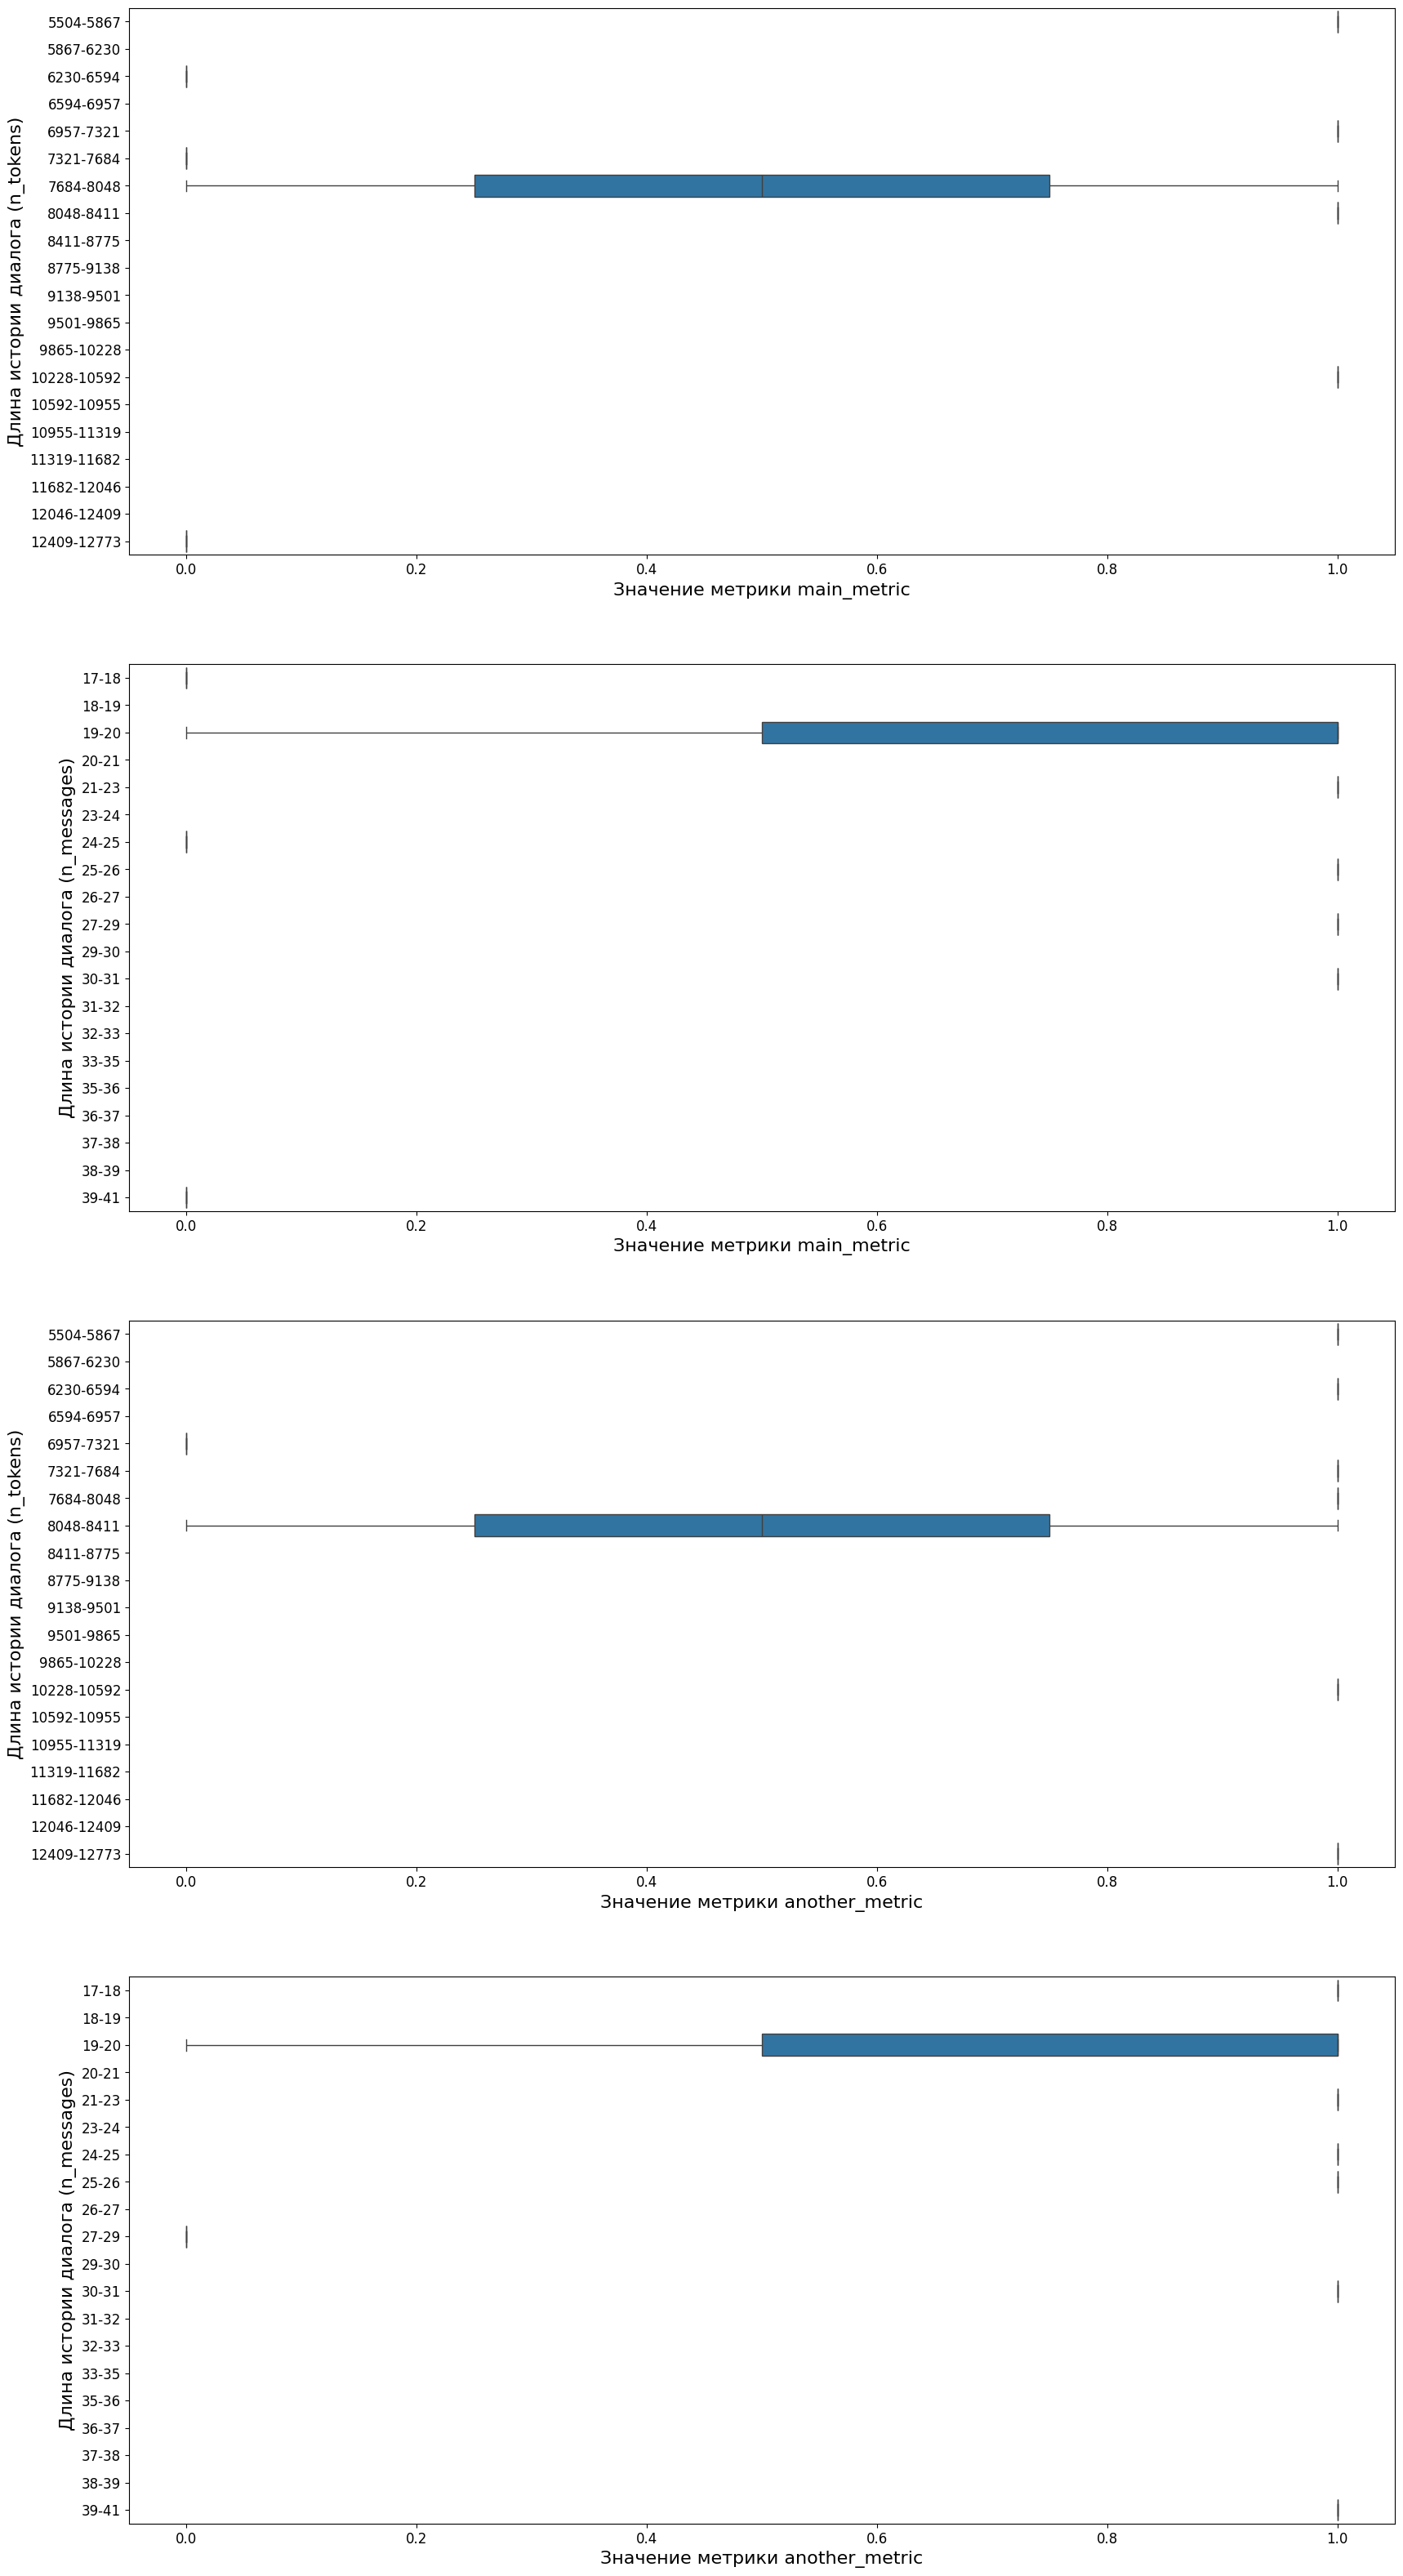

In [16]:
res = valtest_metric_by_history_size(sampler=sampler_agent_memory,
                                     scorer=scorer,
                                     tokenizer=rubert)

In [17]:
display(res['report']['result_dataframes'][0])

correlation   p_value semaphore
metric_name    history_len                                 
main_metric    n_tokens        0.071067  0.845324      gray
               n_messages      0.143889  0.691680      gray
another_metric n_tokens        0.000000  1.000000      gray
               n_messages      0.000000  1.000000      gray

## Тест A.5.2. Анализ качества суммаризации истории взаимодействия с клиентом

In [4]:
from llm_val.val_test.agent_memory.valtest_summarization_quality import valtest_summarization_quality

### LongAnswer

In [17]:
from nltk import word_tokenize
from llm_val.model.BaseGigaModel import BaseGigaModel

model_judge = BaseGigaModel(contour=contour,
                            token=token,
                            auth_data=auth_data,
                            api_url=api_url,
                            oauth_url=oauth_url,
                            rquid=rquid,
                            model='GigaChat:latest')

Пример функции для LLM-as-judge:

In [10]:
import re

def get_llm_as_judge_score(history_raw: str,
                           history_summarized: str,
                           model_judge: tp.Any) -> tp.Tuple[int, str]:
    '''
    Получение оценки LLM-as-judge.
    Parameters:
        history_raw: Фактическая история диалога
        history_summarization: Суммаризированная история диалога    
        model_judge: Модель для получения оценки llm-as-judge, имеет метод .predict()
    Return:
        Оценка llm-as-judge, комментарий к оценке
    '''
    prompt = '''
    ТВОЯ ЗАДАЧА:
    Ты — профессиональный редактор. Оцени полноту суммаризации оригинального текста, то есть насколько полно суммаризация передает ключевые элементы:
    - Основная тема и тезис
    - Ключевые факты и данные  
    - Важные выводы и заключения
    - Существенные детали и контекст
    
    Оригинальный текст представляет собой историю общения пользователя и его помощника. 
    Вопросы пользователя идут после текста #Вопрос пользователя:#
    Ответы помощника идут после текста #Ответ помощника:#
    
    ТВОИ ДАННЫЕ:
    ОРИГИНАЛЬНЫЙ ТЕКСТ: {}
    СУММАРИЗАЦИЯ: {}
    
    ШКАЛА ОЦЕНКИ:
    5 - Полностью исчерпывающая (все ключевые элементы сохранены)
    4 - Хорошая полнота (незначительные упущения)
    3 - Умеренная полнота (отсутствуют некоторые важные элементы)
    2 - Низкая полнота (упущена значительная часть информации)
    1 - Крайне неполная (передана лишь общая идея без деталей)
    
    ФОРМАТ ОТВЕТА:
    _ОЦЕНКА_ = число от 1 до 5
    _КОММЕНТАРИЙ_ = Итоговое заключение о качестве суммаризации, обоснование оценки.
    
    ПРИМЕРЫ ПРАВИЛЬНОГО РЕШЕНИЯ ЗАДАЧИ:
    ПРИМЕР 1:
    
    ОРИГИНАЛЬНЫЙ ТЕКСТ:
    Исследование, проведенное в Гарвардском университете, показало, что регулярные 30-минутные прогулки на свежем воздухе 
    снижают риск развития сердечно-сосудистых заболеваний на 25%. В исследовании участвовало 5000 человек в возрасте от 40 до 65 лет. 
    Ученые отмечают, что наибольший эффект наблюдается при прогулках в парковых зонах, где воздух менее загрязнен. 
    Результаты опубликованы в журнале 'Journal of Cardiology'.
    
    СУММАРИЗАЦИЯ:
    Согласно исследованию Гарвардского университета с участием 5000 человек, регулярные 30-минутные прогулки снижают риск сердечно-сосудистых заболеваний на 25%. 
    Наибольшая польза достигается при прогулках в парках с чистым воздухом. Результаты опубликованы в Journal of Cardiology.
    
    ЭТАЛОННЫЙ ОТВЕТ:
    _ОЦЕНКА_: 5
    _КОММЕНТАРИЙ_: Суммаризация идеально передает всю ключевую информацию: учреждение (Гарвард), длительность прогулок (30 минут), 
    размер выборки (5000 человек), процент снижения риска (25%), условие максимальной эффективности (парки с чистым воздухом) и источник публикации. 
    Все существенные детали сохранены без искажений.
    
    ПРИМЕР 2:
    ОРИГИНАЛЬНЫЙ ТЕКСТ:
    Компания Tesla объявила о выпуске новой модели электромобиля Model Z с запасом хода 600 км. 
    Цена стартует от $45,000. Производство начнется в четвертом квартале 2024 года на заводе в Техасе. 
    Особенности модели включают автопилот пятого уровня и возможность полной зарядки за 15 минут. 
    Ожидается, что первые поставки в Европу начнутся в начале 2025 года.
    
    СУММАРИЗАЦИЯ:
    Tesla выпускает новый электромобиль Model Z с большим запасом хода. Производство начнется в 2024 году.
    
    ЭТАЛОННЫЙ ОТВЕТ:
    _ОЦЕНКА_: 3
    КОММЕНТАРИЙ: Суммаризация передает основную тему (новый электромобиль Model Z) и сроки производства,
    но упускает критически важную информацию: точный запас хода (600 км), цену ($45,000), место производства (Техас),
    ключевые особенности (автопилот 5 уровня, быстрая зарядка) и планы международных поставок.
    Сохранена лишь базовая информация без конкретных деталей.
    
    ПРИМЕР 3:
    ОРИГИНАЛЬНЫЙ ТЕКСТ:
    Крупнейшее в истории исследование влияния кофе на здоровье, проведенное Национальным институтом здоровья США, охватило 500 000 человек за период 10 лет.
    Результаты показали, что употребление 3-4 чашек кофе в день снижает риск развития диабета 2-го типа на 30%, болезни Паркинсона на 25% и депрессии на 20%.
    Ученые подчеркивают, что положительный эффект наблюдается только при употреблении черного кофе без сахара и сливок. 
    Исследование опубликовано в New England Journal of Medicine.
    
    СУММАРИЗАЦИЯ:
    Кофе полезен для здоровья.
    
    ЭТАЛОННЫЙ ОТВЕТ:
    _ОЦЕНКА_: 1
    _КОММЕНТАРИЙ_: Суммаризация крайне неполная и непроинформированная. Упущена ВСЯ ключевая информация: масштаб исследования (500 000 человек, 10 лет), конкретные медицинские benefits (снижение риска диабета на 30%, Паркинсона на 25%, депрессии на 20%),
    важное условие (черный кофе без добавок), источник публикации (New England Journal of Medicine) и даже название института, проводившего исследование. 
    Сохранена лишь общая и размытая формулировка без каких-либо конкретных деталей.
    '''
    model_prompt = prompt.format(history_raw, history_summarized)
    model_answer = model_judge.predict(model_prompt)
    
    score_match = re.search(r'_ОЦЕНКА_:\s*[^\d]*(\d+)', 
                            model_answer[0])
    score = int(score_match.group(1)) / 5 if score_match else None

    comment_match = re.search(r'_КОММЕНТАРИЙ_:\s*(.*)', 
                              model_answer[0], 
                              re.DOTALL)
    comment = comment_match.group(1).strip() if comment_match else 'Гигачат не справился или вернул ответ в непредвиденном формате'

    return score, comment

In [11]:
res = valtest_summarization_quality(sampler=sampler_agent_memory,
                                    tokenizer=word_tokenize,
                                    func_llm_score=get_llm_as_judge_score,
                                    model_judge=model_judge)

In [13]:
display(res['report']['result_dataframes'][0])

,Значение
Наименование метрики,
WIL,1.0
Rouge-L,0.0
Meteor,0.0
Bert_score,0.5
LLM_as_judge_score,0.5


# Раздел А.6. Аспект Рефлексия

## Тест. А.6.1. Изменение ответов модели при удалении рефлексии 


В данном тесте логика подсчета светофора дополнена относительно методики.

Тест можно проводить по автометрике (при ее наличии), а можно - по метрикам на исходных ответах.

В зависимости от того, есть ли у вас автометрика, вы должны либо использовать функцию для подсчета корректности ответа, чтобы можно было эту автометрику посчитать, либо использовать функцию получения эмбеддингов, чтобы можно было посчитать метрики близости ответов модели.

Ниже приведены примеры использования всех этих способов работы с тестом. Модель (агент) представлена классом AgentWrapper, функция для подсчета корректности ответа - check_answer_by_length, функция получения эмбеддингов - get_embedding.

В обертке модели в функции get_params должен присутствовать параметр 'critique_model'.

In [21]:
from llm_val.val_test.reflection.valtest_metric_after_critique_remove import valtest_metric_after_critique_removal


In [22]:
import typing as tp
from copy import deepcopy

class AgentWrapper:
    def __init__(self, 
                 llm_model, 
                 tools: tp.List[tp.Dict]=None,
                 critique_model: tp.Optional=None):
        self.llm_model = llm_model
        self._tools = tools if tools is not None else []
        self._critique_model = critique_model
        self._temperature = getattr(llm_model, 'temperature', 1.0)
        self._top_p = getattr(llm_model, 'top_p', 0.0)
        self._sys_prompt = ""
        self._critique_sys_prompt = "Проанализируй ответ и предложи улучшенную версию."

    def predict(self, 
                questions: tp.Union[str, tp.List[str]]) -> tp.List[str]:
        """Генерация ответов на вопросы с возможностью критики."""
        if isinstance(questions, str):
            questions = [questions]
        
        prompts = []
        for question in questions:
            prompt = self._build_prompt(question)
            prompts.append(prompt)
        
        responses = self.llm_model.predict(prompts)
        processed_responses = self._process_responses(responses)
        
        if self._critique_model:
            return self._apply_critique(processed_responses, 
                                        questions)
        
        return processed_responses
    
    def _build_prompt(self, 
                      question: str) -> str:
        """Строит промпт с учетом доступных инструментов и системного промпта"""
        tools_part = ""
        if self._tools:
            tools_info = "\n".join([
                f"- {tool['name']}: {tool.get('description', 'Без описания')}"
                for tool in self._tools
            ])
            tools_part = f"Доступные инструменты:\n{tools_info}\n\n"
        
        sys_prompt_part = f"{self._sys_prompt}\n\n" if self._sys_prompt else ""
        
        return f"{sys_prompt_part}{tools_part}Вопрос: {question}\nОтвет:"
    
    def _process_responses(self, responses: tp.Any) -> tp.List[str]:
        """Обрабатывает ответы модели"""
        if not isinstance(responses, list):
            responses = [responses]
        
        return [
            response[0] if isinstance(response, list) and response else 
            response if isinstance(response, str) else 
            str(response)
            for response in responses
        ]

    def _apply_critique(self, responses: tp.List[str], questions: tp.List[str]) -> tp.List[str]:
        """Применяет критику к ответам используя critique модель"""
        critique_prompts = []
        for response, question in zip(responses, questions):
            critique_prompt = f"""{self._critique_sys_prompt}
            Вопрос: {question}
            Исходный ответ: {response}
            Критический анализ и улучшенный ответ:"""
            critique_prompts.append(critique_prompt)
        
        improved_responses = self._critique_model.predict(critique_prompts)
        return self._process_responses(improved_responses)

    def get_params(self) -> tp.Dict[str, tp.Any]:
        return {'tools': deepcopy(self._tools),
                'critique_model': deepcopy(self._critique_model) if self._critique_model else None,
                'temperature': self._temperature,
                'top_p': self._top_p,
                'sys_prompt': self._sys_prompt,
                'critique_sys_prompt': self._critique_sys_prompt}

    def set_params(self, **kwargs):
        if 'tools' in kwargs:
            self._tools = kwargs['tools']
        if 'critique_model' in kwargs:
            self._critique_model = kwargs['critique_model']
        if 'temperature' in kwargs:
            self._temperature = kwargs['temperature']
        if 'top_p' in kwargs:
            self._top_p = kwargs['top_p']
        if 'sys_prompt' in kwargs:
            self._sys_prompt = kwargs['sys_prompt']
        if 'critique_sys_prompt' in kwargs:
            self._critique_sys_prompt = kwargs['critique_sys_prompt']

In [45]:
import numpy as np
from typing import List

from llm_val.utils.api import GigaChatAPI

api = GigaChatAPI(contour='sigma',
                  auth_data=AUTH_DATA,
                  rquid=RQUID)

def get_embedding(text: str, 
                  max_length: int=1024) -> np.ndarray:
    '''
    Получает эмбеддинг для текста.
    Parameters:
        text: Входной текст.
        max_length: Максимальная длина текста (в символах).

    Returns:
        Эмбеддинг текста.
    '''
    parts = [text[i:i + max_length] for i in range(0, len(text), max_length)]
    
    embeddings = []
    for part in parts:
        embedding = api.get_embedding(part)[0]['embedding']
        embeddings.append(np.array(embedding))
    
    return np.mean(embeddings, axis=0).reshape(1, -1)

def get_embeddings(texts: List[str], 
                   max_length: int = 1024) -> List[np.ndarray]:
    """Получает эмбеддинги для списка текстов"""
    return [get_embedding(text, max_length) for text in texts]

In [46]:
main_model = model
critique_model = model

agent = AgentWrapper(llm_model=main_model,
                     tools=[{'name': 'search_weather', 'description': 'Поиск информации о погоде'},
                            {'name': 'calculate_math', 'description': 'Математические вычисления'}],
                     critique_model=critique_model
)

agent.set_params(sys_prompt="Ты - полезный AI ассистент. Используй доступные инструменты для точных ответов.",
                 critique_sys_prompt="Ты - эксперт по анализу ответов. Найди ошибки, улучши формулировки и сделай ответ более точным.")

In [47]:
def check_answer_by_length(question: str, 
                           answers: tp.List[str]) -> bool:
    """
    Пример функции проверки корректности ответа.
    """
    if not answers:
        return False
    answer = answers[0]
    return len(answer) > 2560

Случай, когда автометрика используется:



In [48]:
result = valtest_metric_after_critique_removal(sampler=sampler_la,
                                               model=agent,
                                               check_correct_answer=check_answer_by_length)

/home/sigma.sbrf.ru@22314343/.local/lib/python3.9/site-packages/scipy/stats/_morestats.py:3414: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
/home/sigma.sbrf.ru@22314343/.local/lib/python3.9/site-packages/scipy/stats/_morestats.py:3428: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


In [49]:
display(result['report']['result_dataframes'][0])


,Метрика,Значение
0,Базовое качество (с critique),1.000
1,Качество после удаления critique,0.800
2,p-value (Уилкоксон),0.317
3,Результат,red


Случай, когда автометрика не используется:


In [50]:
result = valtest_metric_after_critique_removal(sampler=sampler_la,
                                               model=agent,
                                               get_embed_func=get_embeddings)

In [51]:
display(result['report']['result_dataframes'][0])


,Метрика,Значение
0,Косинусная близость,0.972
1,p-value (косинусная близость),0.625
2,RougeL,0.310
3,p-value (RougeL),0.125
4,BLEU,0.521
5,p-value (BLEU),0.625
6,METEOR,0.325
7,p-value (METEOR),0.438
8,Результат,red


Случай, когда автометрика не используется и светофор выставляем по методике:


In [52]:
result = valtest_metric_after_critique_removal(sampler=sampler_la,
                                               model=agent,
                                               stat_checker=False,
                                               get_embed_func=get_embeddings)

In [53]:
display(result['report']['result_dataframes'][0])


,Метрика,Значение
0,Косинусная близость,0.972
1,RougeL,0.292
2,BLEU,0.540
3,METEOR,0.363
4,Результат,yellow


# Раздел А.7. Стабильность

## Тест А.7.4 Доля противоречий при сравнении out-of-sample и out-of-time выборок

В тест можно передать модель для формирования эмбеддингов для улучшения поиска семантических дубликатов. В случае, если подобная модель не передана, в качестве функции близости используется расстояние Хэмминга на хэшах от текстов.

Для всех типов корзин строится таблица пар расстояний между OOS и OOT, а также рассчитывается доля дубликатов. Для LongAnswer дополнительно рассчитывается доля противоречий для наиболее схожих вопросов. Далее в схожих вопросах происходит поиск схожих ответов. Для тех наблюдений, где схожи и вопрос, и ответ, рассчитывается доля противоречий среди них

Пример загрузки модели:
```python
from sentence_transformers import SentenceTransformer

**_sigma_:**

path = https://sberosc.sigma.sbrf.ru/repo/hosted//hosted/ModelsDS/80cf64e6-4cf8-433d-ad27-009ae10222b9/cointegrated_rubert-tiny2-cedr-emotion-detection.zip

**_mlspace_:**

path = 'cointegrated/rubert-tiny2-cedr-emotion-detection'

embedding_model = SentenceTransformer(path)
```

In [5]:
from llm_val.val_test.stability.valtest_share_of_contradictions import valtest_share_of_contradictions

### LongAnswer

In [8]:
data_la2_stability = data_la2.copy(deep = True)
data_la2_stability = data_la2_stability.drop('prompt', axis = 1)
data_la2_stability = data_la2_stability.rename(columns = {'question': 'prompt'})

In [10]:
sampler_oot_la = OOTLongAnswerSampler(test = data_la2_stability, 
                                      oot = data_la2_stability)

res = valtest_share_of_contradictions(sampler_oot_la, 
                                      embedding_model = None, 
                                      threshold = (0.01,0.05), 
                                      threshold_duplicates = 0.8)

Calculate cos similarity question:   0%|          | 0/50 [00:00<?, ?it/s]

Calculate cos similarity question + true answer:   0%|          | 0/50 [00:00<?, ?it/s]

In [11]:
res['report']['result_dataframes'][0]

,Доля семантических дубликатов вопросов в OOT относительно OOS,Доля семантических дубликатов ответов LLM на похожие вопросы в OOT относительно OOS,Доля противоречий меток асессоров в вопросах (допустимы разные ответы),Доля противоречий меток ассесоров в одних и тех же ответах на те же вопросы
0,1.0,1.0,0.0,0.0


### MMLU

In [13]:
sampler_oot_mmlu = OOTMMLUSampler(data_mmlu, data_mmlu)
res = valtest_share_of_contradictions(sampler_oot_mmlu, 
                                      embedding_model = None, 
                                      threshold = (0.01,0.05), 
                                      threshold_duplicates = 0.8)

Calculate cos similarity question:   0%|          | 0/5 [00:00<?, ?it/s]

In [14]:
res['report']['result_dataframes'][0]

,Доля семантических дубликатов вопросов в OOT относительно OOS
0,1.0


# Раздел А.8. Стабильность без таргета

## Тест А.8.1. Анализ динамики стандартных статистик для запроса и ответа агента

Доступные метрики близости: 'cos_sim', 'bleu', 'rouge', 'meteor' и 'bert_score'. По умолчанию стоит метрика 'rouge'.

Для подсчета 'cos_sim' в тест необходимо передавать embedding_model - обертку над эмбеддинг-моделью c методом get_embedding.

Метрика 'bert_score' может ОЧЕНЬ ДОЛГО считаться, используйте на свой страх и риск!

In [8]:
from llm_val.val_test.stability_without_target.valtest_statistics_dynamics_agent import valtest_statistics_dynamics_agent

### MMLU

In [9]:
import numpy as np
from copy import deepcopy
from sklearn.model_selection import train_test_split

In [10]:
data_mmlu_dgr_ = deepcopy(data_mmlu_dgr)
sampler_mmlu_dgr_ = DGR_MMLUSampler(data_mmlu_dgr_)
sampler_mmlu_dgr_.test['X']['model_answer'] = np.random.choice(['A', 'B', 'C', 'D'], sampler_mmlu_dgr_.test['X'].shape)
sampler_mmlu_dgr_.test['y'] = (sampler_mmlu_dgr_.test['X']['model_answer'] == sampler_mmlu_dgr_.test['X']['true_answer']) * 1.0

X_train, X_test, y_train, y_test = train_test_split(sampler_mmlu_dgr_.test['X'],
                                                    sampler_mmlu_dgr_.test['y'],
                                                    test_size=0.5,
                                                    random_state=42)
sampler_mmlu_dgr_.train = {'X': X_train, 'y': y_train}
sampler_mmlu_dgr_.test = {'X': X_test, 'y': y_test}

In [ ]:
res = valtest_statistics_dynamics_agent(sampler=sampler_mmlu_dgr_,
                                        metric_name='rouge',
                                        data_types=['train', 'test'],
                                        is_discrete=True,
                                        similarity_threshold=0.9)

In [12]:
display(res['report']['result_dataframes'][0])

,Доля новых запросов,Доля новых ответов
0,0.968992,0.101486


### LongAnswer

In [13]:
sampler_la_ = deepcopy(sampler_la2)
sampler_la_.test['X']['question'] = data_la2['question']
sampler_la_.test['y'] = pd.DataFrame({'metric_value': (sampler_la_.test['y'].sum(1) > 15) * 1})
sampler_la_.train = {'X': [], 'y': []}

X_train, X_test, y_train, y_test = train_test_split(sampler_la_.test['X'],
                                                    sampler_la_.test['y'],
                                                    test_size=0.5,
                                                    random_state=42)
sampler_la_.train = {'X': X_train, 'y': y_train}
sampler_la_.test = {'X': X_test, 'y': y_test}

In [14]:
res = valtest_statistics_dynamics_agent(sampler=sampler_la_,
                                        metric_name='rouge',
                                        embedding_model=None,
                                        data_types=['train', 'test'],
                                        is_discrete=False,
                                        similarity_threshold=0.4)

In [15]:
display(res['report']['result_dataframes'][0])

,Доля новых запросов,Доля новых ответов
0,0.96,1.0


Пример работы теста с метрикой 'cos_sim':

In [18]:
from llm_val.utils.api import GigaChatAPI

embedding_model = GigaChatAPI(contour=contour,
                              rquid=RQUID,
                              auth_data=AUTH_DATA,
                              oauth_url=total_auth[contour]['OAUTH_URL'],
                              api_url=total_auth[contour]['API_URL'],
                              token=total_auth[contour]['TOKEN'])

In [19]:
res = valtest_statistics_dynamics_agent(sampler=sampler_la_,
                                        metric_name='cos_sim',
                                        embedding_model=embedding_model,
                                        data_types=['train', 'test'],
                                        is_discrete=False,
                                        similarity_threshold=0.8)

In [20]:
display(res['report']['result_dataframes'][0])

,Доля новых запросов,Доля новых ответов
0,0.04,0.0
